# Final project P10 · The Price of Dinner
**Data Visualization · UEH · Final group project** · team notebook

| | |
|---|---|
| **Team** | Team 10 · team name *(not chosen yet)* |
| **Members** | Nguyễn Hoàng Minh (leader), Phạm Quang Minh, Phạm Tuấn Anh, Trần Nhã Đoan, Nguyễn Minh Nguyệt, Trần Nguyễn Thanh Thảo |
| **Client** | Consumer Lab, a consumer rights association |
| **Big question** | Where should a student on a tight budget buy food in Ho Chi Minh City: at the wet market, at the supermarket or through a delivery app? |
| **Status** | Updated on 15 November 2026 with all eight weeks (576 prices, 558 usable). M0 to M6 have a full draft; M4 chart 7 and the AI audit wait for the team; M7 to M10 come next |
| **How to run** | Run `python data/raw/download_raw.py` once from the repository root (or set `REFRESH = True` in Setup), then *Restart and run all* |

This notebook holds the whole project, from Module M0 to Module M10, in the order of the brief. Every number in a chart title is printed by the code next to it, and every figure is also saved in `report/figures/`. Before anyone edits this notebook, they read `AGENTS.md` (the writing and chart rules of the team) and the latest entries of `CHANGELOG.md`, and they add a changelog entry when they finish. The project website, in Vietnamese, is https://p10-price-of-dinner.vercel.app.

## Summary for Consumer Lab (write this last)
**Big Idea v0:** A student who **[persona]** can save **[X to Y]%** of a weekly food basket by buying **[item group]** at the **[channel]**, but this saving **[stays / shrinks]** once **[travel time / delivery fees / food waste]** is counted.

My group fills in the persona and the saving after the student survey. The eight weeks of prices point in one direction: for the same item, district and week, the supermarket costs about 1.18 times the wet market price and the delivery app about 1.34 times (medians of 187 and 180 matched pairs, Section M4.2). The same basket costs 22% to 29% more on the app in every complete week. M6 finds a group of six foods (water spinach, tomato, watermelon, onion, white tofu and red tilapia) where the app costs a median 67% more than the wet market, against 21% for the other six foods (Section M6.5).

### Module map

| Module | Topic | Lead | Checkpoint | Status on 18 November 2026 |
|---|---|---|---|---|
| M0 | Project setup: brief, team, repository, raw data | Nguyễn Hoàng Minh | | Done |
| M1 | Frame the problem: interview, question tree, Big Idea v0, team contract | *(fill in)* | CP0, CP1 | Draft done; a second short call is needed (Section M1.1) |
| M2 | Acquire, abstract and clean the data | *(fill in)* | CP1 | Done for all eight weeks; the dates of weeks 6 to 8 are later than the export and need a check against the photos (Section M2.3) |
| M3 | House style, colour check, makeover, honest and misleading pair | *(fill in)* | | Draft done; the 150 word text needs a final read |
| M4 | Core charts that answer the four questions | *(fill in)* | | Charts 1 to 6 done; chart 7 waits for the survey; the AI audit and the sketches are for the team |
| M5 | Dashboard and a second tool | *(fill in)* | | Dashboard and Excel file done; the 300 word comparison is a draft for the lead |
| M6 | Hidden structure: PCA and clustering | *(fill in)* | | Done on all eight weeks |
| M7 | Many dimensions: heatmap, treemap, parallel coordinates | *(fill in)* | CP2 | Draft done: heatmap, treemap, stacked bars and parallel coordinates on all eight weeks; the sealed twist arrives at CP2 |
| M8 | Beyond the flat screen: 3D view and experiment | *(fill in)* | | Not started |
| M9 | Interaction, animation and story | *(fill in)* | CP3 | Not started |
| M10 | Evaluation and improvement | *(fill in)* | CP4 | Not started |

## Setup
The first cell writes `house_style.py` next to this notebook, so the style lives in one place and every chart uses it. My group explains each rule of the style in Module M3. The second cell sets the folders and loads the libraries.

In [1]:
%%writefile house_style.py
"""House style for P10 The Price of Dinner.

Every notebook starts with:

    from house_style import *
    apply_style()

The style follows one rule: a chart shows one finding. Context is grey, the element that
carries the finding gets the highlight colour, the title states the finding, and the
subtitle gives the units. Labels sit next to the data instead of in a legend.
"""

from pathlib import Path

import numpy as np
import matplotlib as mpl
from matplotlib import font_manager
from matplotlib.ft2font import FT2Font
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb

# ---------------------------------------------------------------- colours

INK = "#1A1A1A"        # text, axes, the highlight in black and white charts
GREY = "#8C8C8C"       # context data
LIGHT = "#D9D9D9"      # grid lines, empty bars, faint context
PAPER = "#FFFFFF"

# One colour per shopping channel, always in this order and always with these colours.
# The three colours differ in lightness (L* 50, 25, 75), so they also work in greyscale,
# and they stay apart under protan, deutan and tritan simulation (see cvd_report below).
CHANNEL_ORDER = ["Chợ", "Siêu thị", "App"]
CHANNEL = {"Chợ": "#B85C38", "Siêu thị": "#1F3D55", "App": "#9BBDD6"}
CHANNEL_EN = {"Chợ": "Wet market", "Siêu thị": "Supermarket", "App": "Delivery app"}

# Districts never get their own colour: they get a line style or a marker.
DISTRICT_ORDER = ["Quận 10", "Quận 3"]
DISTRICT_LINE = {"Quận 10": "-", "Quận 3": "--"}
DISTRICT_MARKER = {"Quận 10": "o", "Quận 3": "s"}

HIGHLIGHT = CHANNEL["Chợ"]  # single highlight colour for one-finding charts

# Sequential map for amounts (light to dark blue) and diverging map for changes
# (blue below the centre, terracotta above). Centre the diverging map with
# TwoSlopeNorm at 100 for an index or at 0 for a percentage change.
SEQ = LinearSegmentedColormap.from_list("p10_seq", ["#F2F5F8", "#1F3D55"])
DIV = LinearSegmentedColormap.from_list("p10_div", ["#1F3D55", "#F7F7F7", "#B85C38"])


def div_norm(center=100.0, spread=20.0):
    """A diverging norm centred on `center` (100 for an index, 0 for a % change)."""
    return TwoSlopeNorm(vcenter=center, vmin=center - spread, vmax=center + spread)


# ---------------------------------------------------------------- fonts

# Georgia is the house font. Georgia on Windows lacks some Vietnamese letters (ậ, ả, ệ), and
# matplotlib then draws empty boxes. The repository therefore ships Gelasio (notebooks/fonts,
# SIL Open Font License), a free serif with the letter widths of Georgia and every Vietnamese
# letter. apply_style() keeps Georgia when it has all the letters and uses Gelasio otherwise,
# so every computer draws the same words in the same space.
_FONT_DIR = Path(__file__).resolve().parent / "fonts"
_VIETNAMESE = "Đđàáảãạăằắẳẵặâầấẩẫậèéẻẽẹêềếểễệìíỉĩịòóỏõọôồốổỗộơờớởỡợùúủũụưừứửữựỳýỷỹỵ"


def _has_vietnamese(family):
    """True when `family` is installed in regular, bold and italic and has every Vietnamese letter."""
    for style, weight in [("normal", "normal"), ("normal", "bold"), ("italic", "normal")]:
        try:
            path = font_manager.findfont(font_manager.FontProperties(family=family, style=style, weight=weight),
                                         fallback_to_default=False)
        except ValueError:
            return False
        charmap = FT2Font(path).get_charmap()
        if any(ord(ch) not in charmap for ch in _VIETNAMESE):
            return False
    return True


def house_fonts():
    """Register the Gelasio files of notebooks/fonts and return the font list for matplotlib."""
    for path in sorted(_FONT_DIR.glob("*.ttf")):
        font_manager.fontManager.addfont(str(path))
    first = "Georgia" if _has_vietnamese("Georgia") else "Gelasio"
    return [first, "Gelasio", "DejaVu Serif"]


# ---------------------------------------------------------------- numbers

def fmt_vnd(x, short=True):
    """45000 -> '45k' (short) or '45,000 VND'."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return ""
    if short:
        return f"{x / 1000:,.0f}k" if abs(x) >= 1000 else f"{x:,.0f}"
    return f"{x:,.0f} VND"


def fmt_pct(x, digits=0, sign=False):
    """0.123 -> '12%'; with sign=True -> '+12%'."""
    return f"{x:+.{digits}%}" if sign else f"{x:.{digits}%}"


# ---------------------------------------------------------------- matplotlib defaults

def apply_style():
    """Set the house defaults for every figure in the notebook."""
    mpl.rcParams.update({
        "font.family": house_fonts(),
        "font.serif": ["Georgia", "DejaVu Serif", "Times New Roman", "serif"],
        "font.size": 10,
        "text.color": INK,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlelocation": "left",
        "axes.titlesize": 12.5,
        "axes.titleweight": "bold",
        "axes.titlepad": 22,
        "axes.labelsize": 9.5,
        "axes.grid": False,
        "xtick.color": INK,
        "ytick.color": INK,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.frameon": False,
        "legend.fontsize": 9,
        "figure.dpi": 110,
        "figure.facecolor": PAPER,
        "savefig.dpi": 200,
        "savefig.bbox": "tight",
        "savefig.facecolor": PAPER,
    })


def title(ax, text, subtitle=None):
    """Action title in bold and an italic subtitle with the units, both left aligned."""
    ax.set_title(text, loc="left")
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9.5,
                style="italic", color=INK, va="bottom", ha="left")


def figure_title(fig, text, subtitle=None, y=1.0):
    """Headline for a multi-panel figure."""
    fig.text(0.01, y, text, fontsize=17, fontweight="bold", ha="left", va="bottom")
    if subtitle:
        fig.text(0.01, y - 0.012, subtitle, fontsize=10.5, style="italic", ha="left", va="top")


def note(fig, text, y=-0.02):
    """Source and limitation line at the bottom of a figure."""
    fig.text(0.01, y, text, fontsize=8.5, color=INK, ha="left", va="top", style="italic")


def _trim(path, pad=40):
    """Cut the empty white border of a saved PNG (3D axes leave a lot of it)."""
    import time
    from PIL import Image, ImageChops
    for attempt in range(5):
        try:
            with Image.open(path) as raw:
                im = raw.convert("RGB")
                box = ImageChops.difference(im, Image.new("RGB", im.size, (255, 255, 255))).getbbox()
                if box:
                    cropped = im.crop((max(box[0] - pad, 0), max(box[1] - pad, 0),
                                       min(box[2] + pad, im.width), min(box[3] + pad, im.height)))
                else:
                    cropped = None
            if cropped is not None:
                cropped.save(path)
            break
        except OSError:
            if attempt == 4:
                raise
            time.sleep(0.15)


def save(fig, path, pdf=False):
    """Save a figure as PNG with the house settings; pdf=True also writes a PDF (needed for the M5 dashboard)."""
    import time
    for attempt in range(5):
        try:
            fig.savefig(path)
            break
        except OSError:
            if attempt == 4:
                raise
            time.sleep(0.15)
    if str(path).endswith(".png"):
        _trim(path)
        if pdf:
            fig.savefig(str(path)[:-4] + ".pdf")


# ---------------------------------------------------------------- 3D style
# The team draws its charts as 3D columns. Three rules keep them honest: columns start at zero,
# every column that carries the finding has its value printed, and the view stays low (elev about 20)
# so that the tops of the columns do not drift away from their values.

def tint(color, f):
    """Mix a colour with white (f > 0) or with black (f < 0)."""
    r = np.array(to_rgb(color))
    return tuple(r + (1 - r) * f) if f > 0 else tuple(r * (1 + f))


def faces3d(color):
    """Face colours for one ax.bar3d column: light top, base colour in front, darker sides."""
    # bar3d face order: bottom, top, front (-y), back (+y), left (-x), right (+x)
    return [tint(color, -0.2), tint(color, 0.35), color, color, tint(color, -0.25), tint(color, -0.25)]


def bars3d(ax, x, y, heights, colors, width=0.6, depth=0.6, base=0.0, edge="white"):
    """Draw 3D columns centred on (x, y); `colors` is one colour per column."""
    x, y, h = (np.atleast_1d(np.asarray(v, dtype=float)) for v in (x, y, heights))
    face = sum((faces3d(c) for c in colors), [])
    ax.bar3d(x - width / 2, y - depth / 2, np.full_like(h, base), width, depth, h - base,
             color=face, shade=False, edgecolor=edge, linewidth=0.4)


def style3d(ax, elev=20, azim=-60, aspect=(3, 1.4, 1.6), zoom=1.0, grid=False, zaxis=True, yaxis=True):
    """House look for a 3D axes: no panes, no grid, thin grey axis lines, a low view.

    zaxis=False hides the value axis; use it when every column carries its printed value.
    """
    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect(aspect, zoom=zoom)
    ax.grid(grid)
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.set_pane_color((1, 1, 1, 0))
        a.pane.set_edgecolor((1, 1, 1, 0))
        a._axinfo["grid"]["color"] = (0, 0, 0, 0.08)
        a.line.set_color(GREY)
        a.line.set_linewidth(0.6)
    if not zaxis:
        ax.set_zticks([])
        ax.zaxis.line.set_color((1, 1, 1, 0))
    if not yaxis:
        ax.set_yticks([])
        ax.yaxis.line.set_color((1, 1, 1, 0))
    ax.tick_params(axis="both", pad=0, colors=INK, labelsize=8.5, length=0)


def label3d(ax, x, y, z, text, dx=0, dy=12, **kw):
    """Write `text` at the 3D point (x, y, z), drawn in 2D on top so that no column hides it."""
    from mpl_toolkits.mplot3d import proj3d
    sx, sy, _ = proj3d.proj_transform(x, y, z, ax.get_proj())
    kw.setdefault("fontsize", 9)
    kw.setdefault("ha", "center")
    kw.setdefault("va", "bottom")
    return ax.annotate(text, xy=(sx, sy), xytext=(dx, dy), textcoords="offset points", zorder=20, **kw)


def title3d(ax, text, subtitle=None):
    """Action title and subtitle for a 3D axes (set_title sits too high on 3D axes)."""
    ax.text2D(0, 1.02, text, transform=ax.transAxes, fontsize=12.5, fontweight="bold", va="bottom")
    if subtitle:
        ax.text2D(0, 0.985, subtitle, transform=ax.transAxes, fontsize=9.5, style="italic", va="top")


# ---------------------------------------------------------------- colour vision check

_CVD = {   # Machado, Oliveira and Fernandes (2009), severity 1.0, applied in linear RGB
    "protan": np.array([[0.152286, 1.052583, -0.204868],
                        [0.114503, 0.786281, 0.099216],
                        [-0.003882, -0.048116, 1.051998]]),
    "deutan": np.array([[0.367322, 0.860646, -0.227968],
                        [0.280085, 0.672501, 0.047413],
                        [-0.011820, 0.042940, 0.968881]]),
    "tritan": np.array([[1.255528, -0.076749, -0.178779],
                        [-0.078411, 0.930809, 0.147602],
                        [0.004733, 0.691367, 0.303900]]),
}


def _lin(c):
    c = np.asarray(c, dtype=float)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)


def _unlin(c):
    c = np.clip(c, 0, 1)
    return np.where(c <= 0.0031308, c * 12.92, 1.055 * c ** (1 / 2.4) - 0.055)


def _lab(rgb):
    m = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]])
    t = (m @ _lin(rgb)) / np.array([0.95047, 1.0, 1.08883])
    f = np.where(t > 216 / 24389, np.cbrt(t), (24389 / 27 * t + 16) / 116)
    return np.array([116 * f[1] - 16, 500 * (f[0] - f[1]), 200 * (f[1] - f[2])])


def simulate(color, kind):
    """RGB tuple of `color` as seen with protan, deutan or tritan vision, or in greyscale."""
    rgb = np.array(to_rgb(color))
    if kind == "normal":
        return tuple(rgb)
    if kind == "greyscale":
        y = _unlin(np.array([0.2126, 0.7152, 0.0722]) @ _lin(rgb))
        return (float(y),) * 3
    return tuple(_unlin(_CVD[kind] @ _lin(rgb)))


def cvd_report(colors=None):
    """Smallest colour difference (CIE76 delta E) between any two colours, per vision type.

    A delta E above about 20 is easy to tell apart on screen.
    """
    if colors is None:
        colors = CHANNEL
    if isinstance(colors, dict):
        colors = list(colors.values())
    out = {}
    for kind in ["normal", "protan", "deutan", "tritan", "greyscale"]:
        labs = [_lab(np.array(simulate(c, kind))) for c in colors]
        out[kind] = min(np.linalg.norm(a - b) for i, a in enumerate(labs) for b in labs[i + 1:])
    return out



Overwriting house_style.py


In [2]:
import re
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex, to_rgba
from IPython.display import display

import importlib, house_style
importlib.reload(house_style)
from house_style import *
apply_style()
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, CLEAN, FIG = ROOT / "data" / "raw", ROOT / "data" / "clean", ROOT / "report" / "figures"
for folder in (CLEAN, FIG):
    folder.mkdir(parents=True, exist_ok=True)

REFRESH = False     # True downloads the team sheet and the public files again (needs internet)
WEEK1_START = pd.Timestamp("2026-10-12")      # Monday of collection week 1
print("Repository root:", ROOT)

Repository root: C:\Users\Admin\Desktop\FINAL\DataViz_Final_P10


In [3]:
# The download functions of data/raw/download_raw.py, run only when REFRESH is True
"""Download every raw file that notebooks/01_data.ipynb reads.

Run from the repository root:  python data/raw/download_raw.py

The script never edits a file after download. Each run saves a dated copy of the team's
price sheet, so earlier snapshots stay available for checking.

Sources
1. Team price sheet (primary data): Google Sheet "P10 · The Price of Dinner · Bảng thu giá",
   exported as xlsx. The sheet is shared by link, so no login is needed.
2. NSO Viet Nam (formerly GSO): monthly CPI press release tables, one xlsx per month,
   found through the CPI listing page https://www.nso.gov.vn/en/cpi/.
3. FAOSTAT: Consumer Price Indices, bulk download (all countries, normalized).
4. World Bank: Commodity Price Data ("Pink Sheet"), monthly prices.
"""

import datetime as dt
import re
import urllib.request
from pathlib import Path

RAW = ROOT / "data" / "raw"
PRIMARY = RAW / "primary"
PUBLIC = RAW / "public"
SHEET_ID = "1f6CMh-ICjBKUe3QGSaUeeAVF4M5Ol_N5suMf_-ZIDo0"
HEADERS = {"User-Agent": "Mozilla/5.0 (P10 student project, UEH)"}


def fetch(url, timeout=90):
    req = urllib.request.Request(url, headers=HEADERS)
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()


def save_raw(content, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
    print(f"saved {path.relative_to(RAW.parent.parent)} ({len(content) / 1024:,.0f} KB)")


def team_sheet():
    today = dt.date.today().strftime("%Y%m%d")
    url = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=xlsx"
    save_raw(fetch(url), PRIMARY / f"price_sheet_{today}.xlsx")


def nso_cpi():
    pages = set()
    for suffix in ["", "page/2/", "page/3/"]:
        html = fetch(f"https://www.nso.gov.vn/en/cpi/{suffix}").decode("utf-8", "ignore")
        pages |= set(re.findall(r'https://www\.nso\.gov\.vn/en/data-and-statistics/20\d\d/\d\d/consumer-price-index[^"]*', html))
    for page in sorted(pages):
        html = fetch(page).decode("utf-8", "ignore")
        # The period is written either as "9/2026" or as "May 2026".
        period = re.search(r"Reference period:\s*(?:<[^>]+>\s*)*([A-Za-z]+|\d{1,2})[ /](\d{4})", html)
        links = re.findall(r'href="([^"]+\.xlsx)"', html)
        if not (period and links):
            print("skipped (no period or table):", page)
            continue
        m = period.group(1)
        month = int(m) if m.isdigit() else dt.datetime.strptime(m[:3], "%b").month
        year = int(period.group(2))
        save_raw(fetch(links[0]), PUBLIC / "nso_cpi" / f"nso_cpi_{year}_{month:02d}.xlsx")


def faostat_cpi():
    url = "https://bulks-faostat.fao.org/production/ConsumerPriceIndices_E_All_Data_(Normalized).zip"
    save_raw(fetch(url, timeout=180), PUBLIC / "faostat_cpi_normalized.zip")


def world_bank_pink_sheet():
    page = fetch("https://www.worldbank.org/en/research/commodity-markets").decode("utf-8", "ignore")
    url = re.findall(r'https?://[^"]*CMO-Historical-Data-Monthly[^"]*\.xlsx', page)[0]
    save_raw(fetch(url, timeout=180), PUBLIC / "worldbank_cmo_monthly.xlsx")



if REFRESH:
    for step in [team_sheet, nso_cpi, faostat_cpi, world_bank_pink_sheet]:
        try:
            step()
        except Exception as err:
            print(f"FAILED {step.__name__}: {err}")

SHEET = sorted((RAW / "primary").glob("price_sheet_*.xlsx"))[-1]      # newest snapshot of the team sheet
SNAPSHOT = pd.to_datetime(re.search(r"(\d{8})", SHEET.stem).group(1))     # day the sheet was exported
SHEET_DATE = SNAPSHOT.strftime("%d %B %Y").lstrip("0")
print("Price sheet snapshot:", SHEET.name)

Price sheet snapshot: price_sheet_20261115.xlsx


---
# M0 · Project setup
### M0.1 The brief in one table

| Part | What the brief asks |
|---|---|
| Client and role | Consumer Lab; my group works as its research officers |
| Big question | Where should a student on a tight budget buy food, and how much can the channel choice save? |
| Primary data | At least 500 prices that my group collects: 12 items × 3 channels × 2 districts × 8 weeks = 576 planned |
| Survey | At least 60 students, for the three personas of the basket question |
| Public data | At least two public sources, mixed with our own data (my group uses NSO, FAOSTAT and the World Bank) |
| Collector rule | Each record carries the collector, the date and the time; each member is the collector of at least 20% of the records |
| Grading | Group project 40% of the course, final report 20% |
| What the client must be able to do | Repeat the Big Idea in one sentence, see the evidence in at most three explanatory charts, explore the details in an explorer, and trust the data |

### M0.2 Team and items

| Member | Branch | Items whose specification they wrote |
|---|---|---|
| Nguyễn Hoàng Minh (leader) | `hwinh` | SP01 Pork belly, SP02 Water spinach |
| Phạm Quang Minh | `quang-minh` | SP03 Mackerel, SP04 Tomato |
| Phạm Tuấn Anh | `tuan-anh` | SP05 Beef, SP06 Free range chicken |
| Trần Nhã Đoan | `nha-doan` | SP07 Watermelon, SP08 Onion |
| Nguyễn Minh Nguyệt | `minh-nguyet` | SP09 Đà Lạt potato, SP10 White tofu |
| Trần Nguyễn Thanh Thảo | `thao` | SP11 Chicken eggs, SP12 Red tilapia |

Each member wrote the specification of two items. The collection schedule rotates: every week the sheet gives each member two items, so every member visits different items over the eight weeks.

### M0.3 How my group works
Each member works on their own branch and opens a pull request into `dev`. The leader reviews and merges it, and only `dev` can go into `main`. The README explains the steps. Every member, and every AI agent that a member uses, follows `AGENTS.md`, so that the text and the charts look like the work of one team.

### M0.4 Raw data
The cell in Setup downloads four sources when `REFRESH = True`: the team price sheet (a dated xlsx snapshot), the NSO monthly CPI tables, the FAOSTAT consumer price indices and the World Bank Pink Sheet. My group never edits a raw file; every change happens in Module M2.

---
# M1 · Frame the problem
This module holds the interview, the question tree, Big Idea v0, the proposal for CP1 and the team contract. The text also lives in `report/M1_frame_the_problem.md`.

### M1.1 Stakeholder interview

#### M1.1.1 How my group ran the interview

| Item | Detail |
|---|---|
| Date and format | 22 October 2026, 21:09, Microsoft Teams, audio only |
| Respondent | A woman who shops for her family and lives in Tân Phú District. She did not give her name, and my group keeps her anonymous |
| Why this person | The lecturer asked each group to interview someone who buys food for a household. Her shopping covers all three channels in our study |
| Interviewers | Members of my group; Nguyễn Hoàng Minh organised the call and Phạm Quang Minh recorded it |
| Consent | At 04:04, the interviewer explained that the interview was for a course project and asked for permission. She agreed at 04:22. At 22:57, the interviewer promised that her answers would be used only for the course and that no personal details would be shared |
| Length | The whole recording lasts 24 minutes 16 seconds. The interview itself runs from 04:04 to 23:15, which is about 19 minutes |
| Questions | Eight open questions based on *The Mom Test*: each question asks about a recent, real event instead of an opinion about the future |
| Transcript | The audio was transcribed with Whisper (model `large-v3-turbo`). A member then listened again and corrected the wrong words. The full transcript stays in `evidence/`, which git does not publish |

**A gap that my group must close.** The brief asks for an interview of at least 20 minutes. Our formal interview is about one minute short. My group will make a second, short call with the same person, of about 10 minutes, for three reasons. First, the call brings the interview time above 20 minutes. Second, two parts of the recording are unclear: the shop that sold watermelon at 18,000 to 19,000 VND per kg (08:54), and the area she called "near 12" (11:39). Third, the brief says that the lecturer may contact the respondent, so my group needs her permission to share a phone number or an email with the lecturer.

#### M1.1.2 What my group learned

The table links each finding to one of our four smaller questions (Section M1.2). The times refer to the recording.

| Finding | Evidence from the interview | Question |
|---|---|---|
| She splits her basket by channel. She buys vegetables, tofu, onions, lemons and spices at the wet market, and pork, eggs and milk at the supermarket | 06:56. The market is cheaper, she can bargain, and she can buy a small amount. The supermarket keeps meat cold, so she trusts it more | Q1 |
| The price gap for the same item is a few thousand VND | Watermelon: 17,000 VND per kg at the supermarket, 18,000 to 20,000 VND per kg elsewhere (08:54). A 300 g bunch of water spinach: 9,000 VND at one supermarket and 12,000 VND at another (08:54) | Q1 |
| She sees little quality difference between two supermarkets, but the time of day matters | 10:08. The same 300 g bunch looks similar in both shops; freshness depends on morning or afternoon | Q1 |
| Prices differ between areas of the city | Tofu costs 5,000 to 6,000 VND per piece near her home and 3,500 to 4,000 VND near a friend's home in another district (11:03). Some vegetables differ by 3,000 to 4,000 VND | Q2 |
| She notices a price rise by comparing it with her last purchase | Water spinach went from 9,000 to about 12,000 VND per bunch a week before the interview (12:38). She guessed that weather or transport costs were the cause | Q3 |
| One small rise does not matter, but many small rises add up | 13:47. She switches to a cheaper vegetable with similar nutrition | Q3, Q4 |
| Splitting the basket saves money but costs time | 14:58. She saves from 5,000 VND to a few tens of thousands VND per trip, and a few tens of thousands VND per week. She often visits two places. On busy days she goes only to the supermarket | Q4 |
| A cheap price is not always a saving | 18:01. Evening discounts of 30% to 50% gave her vegetables that were wilted inside, and she threw a large part away. Now she checks more carefully or pays more at another shop | Q4 |
| Convenience can beat price | 21:16. Late at night, when the supermarket is closed, she orders fruit on GrabMart or buys it at a convenience store. A bunch of bananas costs about 20,000 VND at the supermarket, while one banana costs about 10,000 VND or more at a convenience store or on an app | Q1, Q4 |

#### M1.1.3 What the interview changes in our design

1. **The unit matters.** She talks about prices per bunch, per piece and per kg. My group therefore records the pack size of every price and converts it to a price per kg (Module M2).
2. **The time of day matters.** Evening discounts and freshness change during the day, so the price sheet records the time of every price.
3. **The cheapest price is not the full cost.** Travel time, the number of trips, the delivery fee and food waste all change what a student really pays. Our student survey will ask about these costs, and the basket cost in Q4 will show the price and the extra costs separately.
4. **The delivery app is a channel for urgent or late purchases.** My group will not judge the app by price alone. The final guide will say when the app is worth its higher price.

### M1.2 Question tree

**Big question:** Where should a student on a tight budget buy food in Ho Chi Minh City, and how much can the choice of channel save?

| Question | Tasks (action and target) | Main chart | Data | Module |
|---|---|---|---|---|
| **Q1.** How large is the price gap between channels for the same item, and does it stay the same over eight weeks? | Compare the price per kg across the three channels for each of the 12 items. Track the gap between channels week by week. Rank the items by the size of the gap | Dot plot per item; line chart of the weekly gap | Team price sheet | M4, M7 |
| **Q2.** Do prices differ between Quận 10 and Quận 3? | Compare the two districts for each item and channel. Find the items with the largest district gap | Dumbbell chart | Team price sheet | M4, M7 |
| **Q3.** How do the price changes that we observe compare with the official food CPI? | Build a price index from our data (week 1 = 100). Compare it with the NSO CPI groups "Foodstuff" and "Food and foodstuff" for Ho Chi Minh City. Place both against world prices of rice, oil and meat | Two panels on the same time axis (no dual axis) | Team price sheet, NSO, FAOSTAT, World Bank | M4 |
| **Q4.** How much does a real student basket cost, and how much can the channel choice save? | Estimate the weekly basket cost for three student personas. Add travel time, delivery fees and waste to the price. Rank the channels by real saving | Bar chart per persona with the price and the extra costs shown separately | Price sheet, student survey (at least 60 students) | M4, M7, M9 |

Each task needs at least one chart. The chart list in Module M4 will refer to these task names.

### M1.3 Big Idea v0

My group uses the template from the brief and leaves the persona and the saving open until the student survey is in.

> A student who **[persona]** can save **[X to Y]%** of a weekly food basket by buying **[item group]** at the **[channel]**, but this saving **[stays / shrinks]** once **[travel time / delivery fees / food waste]** is counted.

**Our working hypothesis.** The interview suggests that the wet market is cheaper for vegetables and that the supermarket wins on trust for meat. My group expects the delivery app to cost the most, but to be the only option for some late purchases. The eight weeks of our data support this hypothesis: for the same item, district and week, the median supermarket price is about 1.18 times the wet market price (187 matched pairs), and the median app price is about 1.34 times (180 matched pairs, Section M4.2). The data cover two districts only, so the Big Idea speaks about Quận 10 and Quận 3, not the whole city.

### M1.4 Proposal on one page (CP1)

#### M1.4.1 Question and plan

The question tree in Section M1.2 is our plan. Every smaller question has a task, a chart and a data source.

#### M1.4.2 Sources tested

My group downloaded every source and read one real row from each.

| Source | What it gives | One row that my group read |
|---|---|---|
| Team price sheet (primary) | Price of 12 items × 3 channels × 2 districts × 8 weeks | Week 1, SP01 pork belly, Grab Mart, Quận 10, 18 October 2026, 12:00: 192,000 VND per kg, promotion, delivery fee 41,000 VND |
| NSO Viet Nam, monthly CPI | CPI by group for Viet Nam and Ho Chi Minh City | September 2026, Ho Chi Minh City, "Foodstuff": 100.19 (previous month = 100) |
| FAOSTAT, consumer price indices | Viet Nam food CPI, 2015 = 100 | June 2026, Viet Nam, food: 140.87 |
| World Bank, Pink Sheet | World commodity prices in US dollars | September 2026, rice (Viet Nam 5% broken): 418.50 USD per tonne |

The data cards in `data/data_cards.md` describe each source in full. The old GSO address (gso.gov.vn) did not respond, so my group uses the new NSO address.

#### M1.4.3 Field data plan

| Part | Plan |
|---|---|
| Price collection | 576 planned prices from 12 October to 6 December 2026. Each member owns two items and checks them in all six channel and district cells every week. The app alternates between Grab Mart (odd weeks) and Shopee Mart (even weeks) |
| Item specification | Each item has a fixed brand, pack and quality note in the overview tab of the sheet |
| Evidence | A photo of the price tag or a screenshot of the app, with the date visible. Photos keep their original timestamp |
| Student survey | At least 60 students. The survey asks where students buy food, how often, how much they spend, how long a trip takes and how much food they throw away. It gives the three personas for Q4 |
| Status on 15 November 2026 | All eight weeks are entered: 576 prices, 558 usable after cleaning, 58 more than the 500 required. The dates of weeks 6 to 8 (18 to 30 November) are later than the export day, so the team checks them against the photos (Section M2.3) |

#### M1.4.4 Risks and plan B

| Risk | Sign | Plan B |
|---|---|---|
| Too few prices to reach 500 | A week ends with fewer than 50 usable prices | The leader reminds the member on Sunday evening. A member who has finished their own items takes over the missing cells and is named as the collector |
| An item is out of stock | The stock column says "Hết hàng" | The row stays with no price. If an item is out of stock in three weeks, my group picks a close substitute and notes it in the item specification |
| The 20% collector rule cannot be met | With six members and one collector per price, a full share is 16.7% | My group asks the lecturer whether a price that two members collect together can carry both names |
| The November CPI arrives late | NSO publishes each month's CPI in the first days of the next month; October arrived in early November | Q3 uses the months that exist at the deadline (October so far) and says clearly which months are missing |
| The app shows a different price at checkout | The final price includes a fee or a voucher | The sheet stores the listed price and the delivery fee separately |
| Fewer than 60 survey answers | Fewer than 40 answers one week before CP2 | Each member shares the survey in two more class groups and asks friends in person |

#### M1.4.5 Constraint card

The constraint card is drawn at CP1. My group will write the card here and say which final chart it applies to.

| Card drawn | Chart it applies to | How the design changes |
|---|---|---|
| *(fill in at CP1)* | *(fill in)* | *(fill in)* |

### M1.5 Team contract

All six members read and sign this contract. My group can change it only when all members agree.

**Roles.** The leader, Nguyễn Hoàng Minh, merges pull requests into `dev` and `main` and sends the weekly reminder. Each module has a lead, who writes the module and asks one other member to review it before the pull request.

**Meetings.** My group meets online every Sunday at 20:00 for 30 minutes. Before the meeting, each member enters the week's prices in the sheet. The meeting starts with the data status figure of Module M2.

**Decisions.** My group decides by discussion first. If the team cannot agree within the meeting, the team votes, and the majority wins. On a tie, the lead of the module decides.

**Deadlines.** A member who cannot finish a task on time tells the team at least 24 hours before the deadline. The team then moves the task or helps.

**When a member does not deliver.** The first time, the leader sends a private message and agrees on a new date. The second time, the team discusses the problem in the next meeting and writes it in the team log. The third time, or if a member does not answer for one week, the leader informs the lecturer, and the team log shows who did each task.

**Conflicts.** Members talk about a problem directly and politely, first in private and then in the meeting. If the conflict continues, the team asks the lecturer for help.

**AI use.** Every member writes the AI tools that they use, and what they used them for, in the AI log. No member uses AI to create price data or survey answers.

| Member | Signature | Date |
|---|---|---|
| Nguyễn Hoàng Minh | | |
| Phạm Quang Minh | | |
| Phạm Tuấn Anh | | |
| Trần Nhã Đoan | | |
| Nguyễn Minh Nguyệt | | |
| Trần Nguyễn Thanh Thảo | | |

---
# M2 · Acquire, abstract and clean the data
**Project:** P10 · The Price of Dinner · **Module lead:** *(fill in)* · **Reviewer:** *(fill in)*

This module turns the raw files in `data/raw/` into one tidy master table in `data/clean/`.
My group never edits a raw file by hand:
every change is a function below, and every function writes one line to the cleaning log.

| Step | What happens | Output |
|---|---|---|
| 1 | Load the team price sheet (8 week tabs) and the item list | raw long table |
| 2 | Write the item specification sheet and the data abstraction table | `item_spec.csv` |
| 3 | Clean with logged functions | `cleaning_log.csv` |
| 4 | Build the master table and the price index (week 1 = 100) | `master_prices.csv` |
| 5 | Load NSO, FAOSTAT and World Bank data and merge them by month | `public_monthly.csv` |
| 6 | Join the official CPI to the weekly table by month | `master_prices.csv` |
| 7 | Data dictionary and a data status figure on one page | `data_dictionary.csv`, figure |

### M2.1 · Load the team price sheet

The Google Sheet has one tab per week. Each tab has 72 rows: 6 members × 2 items × 3 channels × 2 districts.
The overview tab holds the item list and the settings (the two district names and the two delivery apps).

In [4]:
xls = pd.ExcelFile(SHEET)
overview = pd.read_excel(xls, "Tổng quan", header=None)

SETTINGS = {
    "district_a": overview.iat[9, 3], "district_b": overview.iat[10, 3],
    "app_odd": overview.iat[9, 7], "app_even": overview.iat[10, 7],
}
print(SETTINGS)

ITEM_COLS = ["item_code", "chosen_by", "item_name", "item_group", "brand", "pack", "std_unit_sheet", "quality_note"]
items_raw = overview.iloc[14:26, 1:9].copy()
items_raw.columns = ITEM_COLS

WEEK_COLS = ["item", "channel_raw", "district", "assigned_to", "date", "time", "price_vnd", "qty", "unit",
             "promo", "stock", "delivery_fee", "photo", "collected_by_other", "note", "status_sheet", "collector_sheet"]

def read_week(week):
    # One week tab as a table: rows 6 to 77 of the sheet, 17 columns.
    t = pd.read_excel(xls, f"Tuần {week}", header=None).iloc[5:77, :17].copy()
    t.columns = WEEK_COLS
    t.insert(0, "week", week)
    return t

raw = pd.concat([read_week(w) for w in range(1, 9)], ignore_index=True)
print(raw.shape, "| prices entered per week:", raw.groupby("week")["price_vnd"].count().to_dict())
raw.head(3)

{'district_a': 'Quận 10', 'district_b': 'Quận 3', 'app_odd': 'Grab Mart', 'app_even': 'Shopee Mart'}


(576, 18) | prices entered per week: {1: 72, 2: 72, 3: 72, 4: 72, 5: 72, 6: 72, 7: 72, 8: 72}


,week,item,channel_raw,district,assigned_to,date,time,price_vnd,qty,unit,promo,stock,delivery_fee,photo,collected_by_other,note,status_sheet,collector_sheet
0,1,SP01 · Thịt heo ba chỉ,Chợ,Quận 10,Nguyễn Hoàng Minh,2026-10-18 00:00:00,8h,170000,1,kg,False,NaN,NaN,NaN,NaN,NaN,Đủ,Nguyễn Hoàng Minh
1,1,SP01 · Thịt heo ba chỉ,Chợ,Quận 3,Nguyễn Hoàng Minh,2026-10-18 00:00:00,8h,160000,1,kg,False,NaN,NaN,NaN,NaN,NaN,Đủ,Nguyễn Hoàng Minh
2,1,SP01 · Thịt heo ba chỉ,Siêu thị,Quận 10,Nguyễn Hoàng Minh,2026-10-18 00:00:00,12h,179000,1,kg,True,Còn hàng,NaN,NaN,NaN,NaN,Đủ,Nguyễn Hoàng Minh


### M2.2 · Item specification sheet and data abstraction

The item list comes from the overview tab, where each member wrote the specification of their two items.
My group adds one decision here: tofu (SP10) uses **kg** as its standard unit instead of "cái", because
42 of its 48 prices were written in grams or kilograms; the other 6 were written per piece and count as 0.2 kg each (see the cleaning log).

In [5]:
item_spec = items_raw.copy()
item_spec["std_unit"] = item_spec["std_unit_sheet"].replace({"cái": "piece", "lít": "litre"})
item_spec.loc[item_spec["item_code"] == "SP10", "std_unit"] = "kg"
item_spec["piece_weight_kg"] = np.where(item_spec["item_code"] == "SP10", 0.2, np.nan)  # spec note: about 200 g a piece
item_spec["quality_note"] = item_spec["quality_note"].str.replace(r"\s+", " ", regex=True).str.strip()
# Promotion rule (proposed by my group, to confirm at the next meeting): the collector writes the price that a
# shopper pays that day and ticks "promo" when a discount applies. Loyalty prices are not recorded.
item_spec["promo_rule"] = "price paid that day; promo flag ticked; M4 repeats each chart without promo prices"
item_spec.to_csv(CLEAN / "item_spec.csv", index=False)
item_spec[["item_code", "item_name", "item_group", "pack", "std_unit_sheet", "std_unit", "chosen_by", "promo_rule"]]

,item_code,item_name,item_group,pack,std_unit_sheet,std_unit,chosen_by,promo_rule
14,SP01,Thịt heo ba chỉ,Đạm,Bình thường,kg,kg,Nguyễn Hoàng Minh,price paid that day; promo flag ticked; M4 rep...
15,SP02,Rau muống,Rau củ quả,Bình thường,kg,kg,Nguyễn Hoàng Minh,price paid that day; promo flag ticked; M4 rep...
16,SP03,Cá thu,Đạm,Bình thường,kg,kg,Phạm Quang Minh,price paid that day; promo flag ticked; M4 rep...
17,SP04,Cà chua,Rau củ quả,Bình thường,kg,kg,Phạm Quang Minh,price paid that day; promo flag ticked; M4 rep...
18,SP05,Thịt bò,Đạm,Bình thường,kg,kg,Phạm Tuấn Anh,price paid that day; promo flag ticked; M4 rep...
19,SP06,Thịt gà ta (gà Ri Lai),Đạm,Bình thường,kg,kg,Phạm Tuấn Anh,price paid that day; promo flag ticked; M4 rep...
20,SP07,Dưa hấu,Rau củ quả,Bình thường,kg,kg,Trần Nhã Đoan,price paid that day; promo flag ticked; M4 rep...
21,SP08,Hành tây,Rau củ quả,Bình thường,kg,kg,Trần Nhã Đoan,price paid that day; promo flag ticked; M4 rep...
22,SP09,Khoai tây Đà Lạt,Rau củ quả,Bán theo kg,kg,kg,Nguyễn Minh Nguyệt,price paid that day; promo flag ticked; M4 rep...
23,SP10,Đậu hũ trắng,Đạm,Miếng khoảng 200–300 g,cái,kg,Nguyễn Minh Nguyệt,price paid that day; promo flag ticked; M4 rep...


**Data abstraction.** The primary dataset is a **table**: one item = one price observation of one product,
in one channel, one district and one week. The table below gives the attribute types.

| Attribute | Type | Direction | Role |
|---|---|---|---|
| `item_code`, `item_name` | categorical | none | key |
| `item_group` | categorical | none | value (context) |
| `channel` | categorical (3 levels) | none | key |
| `district` | categorical (2 levels) | none | key |
| `week` | ordinal (1 to 8) | sequential | key |
| `app_name` | categorical | none | value (which app the App row used) |
| `collector` | categorical | none | value (evidence) |
| `date`, `time` | ordinal (time) | sequential | value (evidence) |
| `price_vnd` | quantitative (ratio) | sequential | value (price as written on the tag) |
| `qty`, `unit` | quantitative, categorical | sequential, none | value (pack size) |
| `price_std` | quantitative (ratio) | sequential | value (VND per kg, litre or piece) |
| `promo`, `in_stock` | categorical (boolean) | none | value |
| `delivery_fee` | quantitative (ratio) | sequential | value (App rows only) |
| `index_w1` | quantitative (ratio) | diverging around 100 | derived value |
| `flags` | categorical (set) | none | value (data quality) |

The public data are three more **tables**. They share one key, `year_month`, so they can be joined to each other and to the weekly table.

| Table | Keys | Values | Attribute types |
|---|---|---|---|
| NSO CPI | `year_month` (ordinal, sequential), `area` (categorical), `series` (categorical, CPI group) | `value` with `measure` = index against the previous month or against 2024 | quantitative ratio, diverging around 100 |
| FAOSTAT CPI | `year_month`, `series` (food or all items) | `value`, index 2015 = 100 | quantitative ratio, sequential |
| World Bank Pink Sheet | `year_month`, `series` (commodity) | `value`, price in US dollars per kg or per tonne | quantitative ratio, sequential |

All three are stacked into one long table, `data/clean/public_monthly.csv`, with the columns `year_month, source, area, series, measure, value` (details in `data/data_cards.md`).

### M2.3 · Cleaning pipeline

Each step is a function that takes the table and returns the table. The helper `logged` runs a step,
counts the rows it changed, and writes one line to the cleaning log with the rule and the reason.

In [6]:
LOG = []

def logged(step, rule, reason, hits):
    # Decorator: run a cleaning step and record how many rows the rule touched.
    # hits(table) returns True for the rows that the rule touched.
    def wrap(fn):
        def run(df):
            n_before = len(df)
            after = fn(df.copy())
            LOG.append({"step": step, "rule": rule, "reason": reason, "rows_before": n_before,
                        "rows_after": len(after), "rows_affected": int(hits(after).sum())})
            return after
        return run
    return wrap

In [7]:
@logged("01_standardise", "Split 'SP01 · name' into code and name; map Grab Mart / Shopee Mart to channel App and keep the app name; strip spaces.",
        "The sheet shows the app name in the channel column; the analysis needs three channels.",
        hits=lambda d: d["app_name"].notna())
def standardise(df):
    df["item_code"] = df["item"].str.extract(r"(SP\d{2})")
    df = df.merge(item_spec[["item_code", "item_name", "item_group", "std_unit", "piece_weight_kg"]], on="item_code", how="left")
    apps = {SETTINGS["app_odd"], SETTINGS["app_even"]}
    df["app_name"] = df["channel_raw"].where(df["channel_raw"].isin(apps))
    df["channel"] = np.where(df["channel_raw"].isin(apps), "App", df["channel_raw"])
    for col in ["unit", "stock", "note", "photo", "collected_by_other"]:
        df[col] = df[col].astype("string").str.strip()
    df["week_start"] = WEEK1_START + pd.to_timedelta((df["week"] - 1) * 7, unit="D")
    return df.drop(columns=["item"])

@logged("02_collected", "A row counts as collected when it has a price; rows without a price stay in the table with collected = False.",
        "Keeping the empty slots in the table shows where prices are missing.",
        hits=lambda d: ~d["collected"])
def mark_collected(df):
    df["collected"] = df["price_vnd"].notna()
    return df

@logged("03_date_typo", "If a date falls in the wrong year but on the right day and month of its week, set the year to 2026.",
        "One row in week 1 was typed as 18/10/2027.",
        hits=lambda d: d["date_fixed"])
def fix_date_year(df):
    d = pd.to_datetime(df["date"], errors="coerce")
    wrong_year = d.notna() & (d.dt.year != 2026)
    df["date_fixed"] = wrong_year
    df.loc[wrong_year, "date"] = d[wrong_year].map(lambda x: x.replace(year=2026))
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    return df

@logged("03b_future_date", "A price dated after the day the sheet was exported is flagged future_date, so that the team checks its date against the photo. The price stays in the analysis.",
        "The team lead confirmed on 15 November 2026 that the sheet holds all eight weeks; a date later than the export is most likely a typing error in the date column.",
        hits=lambda d: d["future_date"])
def flag_future_dates(df):
    df["future_date"] = df["date"].notna() & (df["date"] > SNAPSHOT)
    return df

@logged("04_qty_as_date", "If the quantity was turned into a date (Sheets reads '2.5' as 2 May), rebuild the number as day.month.",
        "The sheet uses the Vietnamese locale; typing 2.5 kg produced a date instead of a number.",
        hits=lambda d: d["qty_fixed"])
def fix_quantity_dates(df):
    is_date = df["qty"].map(lambda v: hasattr(v, "month") and hasattr(v, "day"))
    df["qty_fixed"] = is_date
    df.loc[is_date, "qty"] = df.loc[is_date, "qty"].map(lambda v: float(f"{v.day}.{v.month}"))
    df["qty"] = pd.to_numeric(df["qty"], errors="coerce")
    return df

@logged("05_out_of_stock", "If the stock column says 'Hết hàng', drop the price (keep the row, in_stock = False).",
        "A price for an item that was not available cannot be bought, so it must not enter averages.",
        hits=lambda d: ~d["in_stock"])
def out_of_stock(df):
    df["in_stock"] = ~df["stock"].fillna("").str.contains("Hết hàng")
    df.loc[~df["in_stock"], "price_vnd"] = np.nan
    return df

UNIT = {"kg": ("kg", 1.0), "g": ("kg", 0.001), "lít": ("litre", 1.0), "ml": ("litre", 0.001),
        "cái": ("piece", 1.0), "miếng": ("piece", 1.0)}

@logged("06_unit_price", "price_std = price / (qty × factor): g to kg, ml to litre, pieces stay pieces. Tofu pieces count as 0.2 kg each.",
        "Packs differ in size (500 g, 2.5 kg, 10 eggs); only a price per standard unit can be compared.",
        hits=lambda d: d["price_std"].notna() & d["qty_std"].ne(1))
def unit_price(df):
    unit = df["unit"].fillna("").str.lower()
    fam = unit.map(lambda u: UNIT.get(u, (np.nan, np.nan))[0]).astype(object)
    factor = unit.map(lambda u: UNIT.get(u, (np.nan, np.nan))[1]).astype(float)
    piece_to_kg = (fam == "piece") & (df["std_unit"] == "kg") & df["piece_weight_kg"].notna()
    factor = factor.where(~piece_to_kg, df["piece_weight_kg"])
    fam = fam.where(~piece_to_kg, "kg")
    df["qty_std"] = df["qty"] * factor
    df["unit_ok"] = [f == u for f, u in zip(fam.fillna("none").astype(str), df["std_unit"].fillna("").astype(str))]
    df["price_std"] = np.where(df["unit_ok"], df["price_vnd"] / df["qty_std"], np.nan)
    df["assumed_weight"] = piece_to_kg & df["price_vnd"].notna()
    return df

@logged("07_collector", "collector = the name in 'Người thu thực tế' if filled, otherwise the assigned member.",
        "The brief counts each member's share of records by the person who actually collected the price.",
        hits=lambda d: d["collector"].ne(d["assigned_to"]))
def set_collector(df):
    df["collector"] = df["collected_by_other"].fillna(df["assigned_to"])
    return df

@logged("08_time", "Write every time as HH:MM ('8h' -> 08:00, '17h30' -> 17:30, '08:30:00' -> 08:30).",
        "Members typed times in three formats.",
        hits=lambda d: d["time_changed"])
def tidy_time(df):
    def hhmm(v):
        if pd.isna(v):
            return pd.NA
        s = str(v).strip().lower()
        m = re.match(r"^(\d{1,2})\s*[h:]\s*(\d{0,2})", s)
        return f"{int(m.group(1)):02d}:{int(m.group(2) or 0):02d}" if m else pd.NA
    new = df["time"].map(hhmm).astype("string")
    df["time_changed"] = df["time"].notna() & (df["time"].astype(str) != new.fillna("").astype(str))
    df["time"] = new
    return df

@logged("09_promo_flags", "promo and delivery_fee become a boolean and a number; delivery_fee is kept only for App rows.",
        "A delivery fee on a wet market row would be an entry error.",
        hits=lambda d: d["delivery_fee"].notna())
def tidy_flags(df):
    df["promo"] = df["promo"].fillna(False).astype(bool)
    df["delivery_fee"] = pd.to_numeric(df["delivery_fee"], errors="coerce").where(df["channel"] == "App")
    return df

@logged("10_outlier_flag", "Flag (do not delete) a price per unit above 2 times or below half the median of the same item across all channels, districts and weeks.",
        "My group wants to check these rows against the photo before trusting them; deleting them silently would hide real price gaps.",
        hits=lambda d: d["outlier"])
def flag_outliers(df):
    med = df["price_std"].groupby(df["item_code"]).transform("median")
    ratio = df["price_std"] / med
    df["outlier"] = ((ratio > 2) | (ratio < 0.5)).fillna(False).astype(bool)
    return df

def add_flags(df):
    f = pd.DataFrame({
        "not_collected": ~df["collected"],
        "future_date": df["future_date"],
        "out_of_stock": df["collected"] & ~df["in_stock"],
        "unit_mismatch": df["price_vnd"].notna() & ~df["unit_ok"],
        "assumed_weight": df["assumed_weight"],
        "outlier": df["outlier"].fillna(False),
    })
    df["flags"] = f.apply(lambda r: ";".join(c for c in f.columns if r[c]), axis=1)
    df["usable"] = df["price_std"].notna() & ~df["outlier"].fillna(False)
    return df

pipeline = [standardise, mark_collected, fix_date_year, flag_future_dates, fix_quantity_dates, out_of_stock,
            unit_price, set_collector, tidy_time, tidy_flags, flag_outliers]
clean = raw.copy()
for step in pipeline:
    clean = step(clean)
clean = add_flags(clean).drop(columns=["date_fixed", "qty_fixed", "time_changed"])

cleaning_log = pd.DataFrame(LOG)
cleaning_log.insert(0, "run_date", pd.Timestamp.today().strftime("%Y-%m-%d"))
cleaning_log.insert(1, "source", SHEET.name)
cleaning_log.to_csv(CLEAN / "cleaning_log.csv", index=False)
cleaning_log[["step", "rows_before", "rows_after", "rows_affected", "rule"]]

,step,rows_before,rows_after,rows_affected,rule
0,01_standardise,576,576,192,Split 'SP01 · name' into code and name; map Gr...
1,02_collected,576,576,0,A row counts as collected when it has a price;...
2,03_date_typo,576,576,1,If a date falls in the wrong year but on the r...
3,03b_future_date,576,576,216,A price dated after the day the sheet was expo...
4,04_qty_as_date,576,576,2,If the quantity was turned into a date (Sheets...
5,05_out_of_stock,576,576,1,"If the stock column says 'Hết hàng', drop the ..."
6,06_unit_price,576,576,106,"price_std = price / (qty × factor): g to kg, m..."
7,07_collector,576,576,0,collector = the name in 'Người thu thực tế' if...
8,08_time,576,576,563,"Write every time as HH:MM ('8h' -> 08:00, '17h..."
9,09_promo_flags,576,576,124,promo and delivery_fee become a boolean and a ...


In [8]:
# M2.3 Every unit conversion that the pipeline uses, saved as its own table
conversions = pd.DataFrame([{"unit_written": u, "standard_unit": fam, "factor": f} for u, (fam, f) in UNIT.items()])
conversions = pd.concat([conversions, pd.DataFrame([{"unit_written": "cái or miếng (tofu, SP10 only)", "standard_unit": "kg", "factor": 0.2}])],
                        ignore_index=True)
valid = clean[clean["collected"]]
conversions["used_in_valid_weeks"] = conversions["unit_written"].map(lambda u: int((valid["unit"].str.lower() == u).sum()) if u in UNIT else int(valid["assumed_weight"].sum()))
conversions.to_csv(CLEAN / "unit_conversions.csv", index=False)
conversions

,unit_written,standard_unit,factor,used_in_valid_weeks
0,kg,kg,1.000,467
1,g,kg,0.001,54
2,lít,litre,1.000,0
3,ml,litre,0.001,0
4,cái,piece,1.000,52
5,miếng,piece,1.000,2
6,"cái or miếng (tofu, SP10 only)",kg,0.200,6


**Rows that the pipeline flagged.** My group keeps flagged rows in the master table, so the decision to drop them
stays visible. Rows flagged `outlier` are checked against the photo or screenshot before the analysis in M4.

In [9]:
flagged = clean[clean["collected"] & (clean["flags"] != "")]
flagged[["week", "item_code", "item_name", "channel", "app_name", "district", "price_vnd", "qty", "unit", "price_std", "flags"]].round(0)

,week,item_code,item_name,channel,app_name,district,price_vnd,qty,unit,price_std,flags
29,1,SP04,Cà chua,App,Grab Mart,Quận 3,42000,500.0,g,84000.0,outlier
42,1,SP10,Đậu hũ trắng,Chợ,NaN,Quận 10,5000,1.0,miếng,25000.0,assumed_weight
43,1,SP10,Đậu hũ trắng,Chợ,NaN,Quận 3,6000,1.0,miếng,30000.0,assumed_weight
64,1,SP08,Hành tây,App,Grab Mart,Quận 10,32800,500.0,g,65600.0,outlier
70,1,SP09,Khoai tây Đà Lạt,App,Grab Mart,Quận 10,NaN,1.0,kg,NaN,out_of_stock
...,...,...,...,...,...,...,...,...,...,...,...
571,8,SP11,Trứng gà công nghiệp,Chợ,NaN,Quận 3,22000,10.0,cái,2200.0,future_date
572,8,SP11,Trứng gà công nghiệp,Siêu thị,NaN,Quận 10,26500,10.0,cái,2650.0,future_date
573,8,SP11,Trứng gà công nghiệp,Siêu thị,NaN,Quận 3,27000,10.0,cái,2700.0,future_date
574,8,SP11,Trứng gà công nghiệp,App,Shopee Mart,Quận 10,35000,10.0,cái,3500.0,future_date


### M2.4 · Master table and price index

One row is one item × channel × district × week. The price index compares each price with the same series in
week 1 (week 1 = 100). The App channel alternates between two apps, so an App price is compared with the first
week of the **same app**: odd weeks with week 1 (Grab Mart), even weeks with week 2 (Shopee Mart).

In [10]:
KEY = ["item_code", "channel", "district", "week"]
master = clean.sort_values(KEY).reset_index(drop=True)

def base_week(row):
    if row["channel"] == "App":
        return 1 if row["week"] % 2 == 1 else 2
    return 1

master["base_week"] = master.apply(base_week, axis=1)
base = (master[master["usable"]].set_index(["item_code", "channel", "district", "week"])["price_std"])
master["base_price"] = [base.get((r.item_code, r.channel, r.district, r.base_week), np.nan) for r in master.itertuples()]
master["index_w1"] = np.where(master["usable"], master["price_std"] / master["base_price"] * 100, np.nan)

assert not master.duplicated(KEY).any(), "a key appears twice"

WEEKS_DONE = sorted(master.loc[master["collected"], "week"].unique())       # weeks with valid prices
NUM_WORD = dict(enumerate(["zero", "one", "two", "three", "four", "five", "six", "seven", "eight"]))
PERIOD = f"weeks 1 to {WEEKS_DONE[-1]}" if len(WEEKS_DONE) > 2 else "weeks 1 and 2"
print("Weeks with valid prices:", WEEKS_DONE, "|", PERIOD)
print(master.shape, "| usable prices:", int(master["usable"].sum()))

Weeks with valid prices: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)] | weeks 1 to 8
(576, 39) | usable prices: 558


**Weekly table.** The brief also asks for a weekly table. My group keeps the long master table for the analysis and saves a wide copy for reading: one row per item, channel and district, one column per week, with the price per standard unit.

In [11]:
# M2.4 Weekly table: price per standard unit, one column per week (empty until the week is collected)
weekly = (master[master["usable"]].pivot_table(index=["item_code", "channel", "district"], columns="week", values="price_std")
          .reindex(columns=range(1, 9)).add_prefix("week_").round(0))
weekly.to_csv(CLEAN / "weekly_table.csv")
weekly.head(6)

week                           week_1    week_2    week_3    week_4    week_5  \
item_code channel  district                                                     
SP01      App      Quận 10   192000.0  180000.0  190000.0  164000.0  198000.0   
                   Quận 3    198000.0  114000.0  187000.0  170000.0  205000.0   
          Chợ      Quận 10   170000.0  148000.0  183000.0  140000.0  165000.0   
                   Quận 3    160000.0  150000.0  186000.0  135000.0  170000.0   
          Siêu thị Quận 10   179000.0  150000.0  192000.0  153600.0  192000.0   
                   Quận 3    169000.0  150000.0  193000.0  153600.0  200000.0   

week                           week_6    week_7    week_8  
item_code channel  district                                
SP01      App      Quận 10   186745.0  195000.0  190500.0  
                   Quận 3    186745.0  202000.0  192700.0  
          Chợ      Quận 10   170000.0  172000.0  170000.0  
                   Quận 3    160000.0  165000.0  165000.0  
          Siêu thị Quận 10   160000.0  185000.0  179500.0  
                   Quận 3    169000.0  195000.0  169800.0

### M2.5 · Public data: NSO, FAOSTAT and World Bank

| Source | What my group takes | Coverage now |
|---|---|---|
| NSO Viet Nam (formerly GSO), monthly CPI release | CPI by group: food and foodstuff, food (grain), foodstuff, eating out; national and Ho Chi Minh City; change against the previous month | May to October 2026 |
| FAOSTAT, Consumer Price Indices | Viet Nam food CPI and general CPI (2015 = 100) | to June 2026 |
| World Bank, Pink Sheet | World prices of rice (Viet Nam 5%), palm oil, soybean oil, sugar, chicken, beef | to October 2026 |

All three are merged into one long table with the key `year_month`.

In [12]:
NSO_LABELS = {"consumer price index": "all_items", "i. food and foodstuff": "food_and_foodstuff",
              "1- food": "food_grain", "2- foodstuff": "foodstuff", "3- eating out": "eating_out"}

def read_nso(path):
    # One NSO release: national CPI by group and the Ho Chi Minh City column of the province sheet.
    year, month = map(int, re.findall(r"(\d{4})_(\d{2})", path.name)[0])
    ym = f"{year}-{month:02d}"
    x = pd.ExcelFile(path)
    rows = []
    nat = pd.read_excel(x, x.sheet_names[0], header=None)
    head = nat.index[nat.astype(str).apply(lambda r: r.str.contains("Base year").any(), axis=1)][0]
    for i in nat.index[nat.index > head]:
        label = str(nat.iat[i, 0]).strip().lower()
        if label in NSO_LABELS:
            rows.append({"year_month": ym, "source": "NSO", "area": "Viet Nam", "series": NSO_LABELS[label],
                         "measure": "index_prev_month_100", "value": float(nat.iat[i, 4])})
            rows.append({"year_month": ym, "source": "NSO", "area": "Viet Nam", "series": NSO_LABELS[label],
                         "measure": "index_base_2024_100", "value": float(nat.iat[i, 1])})
    prov = pd.read_excel(x, x.sheet_names[-1], header=None)
    hit = prov.astype(str).apply(lambda c: c.str.contains("Ho Chi Minh"))
    r0, c0 = np.argwhere(hit.values)[0]
    for i in prov.index[prov.index > r0]:
        label = str(prov.iat[i, 0]).strip().lower()
        if label in NSO_LABELS:
            rows.append({"year_month": ym, "source": "NSO", "area": "Ho Chi Minh City", "series": NSO_LABELS[label],
                         "measure": "index_prev_month_100", "value": float(prov.iat[i, c0])})
    return pd.DataFrame(rows)

nso = pd.concat([read_nso(p) for p in sorted((RAW / "public" / "nso_cpi").glob("nso_cpi_*.xlsx"))], ignore_index=True)

with zipfile.ZipFile(RAW / "public" / "faostat_cpi_normalized.zip") as z:
    name = [n for n in z.namelist() if n.endswith("All_Data_(Normalized).csv")][0]
    fao_all = pd.read_csv(z.open(name), encoding="latin1", low_memory=False)
MONTHS = {m: i for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July",
                                      "August", "September", "October", "November", "December"], 1)}
fao = fao_all[(fao_all["Area"] == "Viet Nam") & fao_all["Item"].str.startswith("Consumer Prices") & (fao_all["Year"] >= 2024)].copy()
fao = pd.DataFrame({
    "year_month": fao["Year"].astype(str) + "-" + fao["Months"].map(MONTHS).map("{:02d}".format),
    "source": "FAOSTAT", "area": "Viet Nam",
    "series": np.where(fao["Item"].str.contains("Food"), "food", "all_items"),
    "measure": "index_2015_100", "value": fao["Value"].astype(float)})

wb_raw = pd.read_excel(RAW / "public" / "worldbank_cmo_monthly.xlsx", "Monthly Prices", header=None)
WB_COLS = {"Rice, Viet Namese 5%": "rice_vn_5pct", "Palm oil": "palm_oil", "Soybean oil": "soybean_oil",
           "Sugar, world": "sugar_world", "Chicken **": "chicken", "Beef **": "beef"}
names = wb_raw.iloc[4].astype(str).str.strip()
units = wb_raw.iloc[5].astype(str).str.strip()
data = wb_raw.iloc[6:].rename(columns={0: "period"})
wb_rows = []
for col, series in WB_COLS.items():
    j = names.index[names == col][0]
    d = pd.DataFrame({"period": data["period"], "value": pd.to_numeric(data[j], errors="coerce")}).dropna()
    d = d[d["period"].str.match(r"^(2024|2025|2026)M")]
    wb_rows.append(pd.DataFrame({"year_month": d["period"].str.replace("M", "-"), "source": "World Bank",
                                 "area": "World", "series": series, "measure": f"price_usd {units[j]}", "value": d["value"]}))
wb = pd.concat(wb_rows, ignore_index=True)

public = pd.concat([nso, fao, wb], ignore_index=True).sort_values(["source", "area", "series", "measure", "year_month"])
public.to_csv(CLEAN / "public_monthly.csv", index=False)
print(public.groupby(["source", "area"])["year_month"].agg(["min", "max", "count"]))

                                 min      max  count
source     area                                     
FAOSTAT    Viet Nam          2024-01  2026-06     60
NSO        Ho Chi Minh City  2026-05  2026-10     30
           Viet Nam          2026-05  2026-10     60
World Bank World             2024-01  2026-10    204


### M2.6 · Join the official CPI to the weekly table

The join key is `year_month`, taken from the Monday of each collection week. Weeks 1 to 3 start in October 2026 and weeks 4 to 8 in November (week 8 starts on Monday 30 November). NSO published the October CPI in early November, so weeks 1 to 3 carry the official values. The November CPI arrives in early December, so weeks 4 to 8 stay empty until then. The table below shows the months that are available.

In [13]:
hcmc = (nso[(nso["area"] == "Ho Chi Minh City") & (nso["measure"] == "index_prev_month_100")]
        .pivot(index="year_month", columns="series", values="value").add_prefix("cpi_hcmc_mom_").reset_index())
master["year_month"] = master["week_start"].dt.strftime("%Y-%m")
master = master.drop(columns=[c for c in master.columns if c.startswith("cpi_hcmc_mom_")]).merge(hcmc, on="year_month", how="left")
print("weeks with an official CPI value:", master.loc[master["cpi_hcmc_mom_foodstuff"].notna(), "week"].unique())
hcmc.round(2)

weeks with an official CPI value: [1 2 3]


series,year_month,cpi_hcmc_mom_all_items,cpi_hcmc_mom_eating_out,cpi_hcmc_mom_food_and_foodstuff,cpi_hcmc_mom_food_grain,cpi_hcmc_mom_foodstuff
0,2026-05,100.27,100.10,99.84,99.83,99.66
1,2026-06,99.65,100.35,100.26,100.07,100.23
2,2026-07,99.67,99.97,99.85,99.88,99.76
3,2026-08,100.42,99.92,99.84,99.83,99.79
4,2026-09,100.43,99.51,99.93,100.11,100.19
5,2026-10,100.30,99.99,100.37,100.39,100.62


In [14]:
MASTER_COLS = ["item_code", "item_name", "item_group", "channel", "app_name", "district", "week", "week_start",
               "year_month", "collector", "assigned_to", "date", "time", "price_vnd", "qty", "unit", "std_unit",
               "qty_std", "price_std", "promo", "in_stock", "delivery_fee", "collected", "usable", "flags",
               "base_week", "index_w1", "photo", "note"] + [c for c in master.columns if c.startswith("cpi_hcmc_mom_")]
master[MASTER_COLS].to_csv(CLEAN / "master_prices.csv", index=False)
master[MASTER_COLS].head()

,item_code,item_name,item_group,channel,app_name,district,week,week_start,year_month,collector,...,flags,base_week,index_w1,photo,note,cpi_hcmc_mom_all_items,cpi_hcmc_mom_eating_out,cpi_hcmc_mom_food_and_foodstuff,cpi_hcmc_mom_food_grain,cpi_hcmc_mom_foodstuff
0,SP01,Thịt heo ba chỉ,Đạm,App,Grab Mart,Quận 10,1,2026-10-12,2026-10,Nguyễn Hoàng Minh,...,,1,100.0,<NA>,<NA>,100.3032,99.9925,100.3691,100.3913,100.6231
1,SP01,Thịt heo ba chỉ,Đạm,App,Shopee Mart,Quận 10,2,2026-10-19,2026-10,Phạm Tuấn Anh,...,,2,100.0,<NA>,<NA>,100.3032,99.9925,100.3691,100.3913,100.6231
2,SP01,Thịt heo ba chỉ,Đạm,App,Grab Mart,Quận 10,3,2026-10-26,2026-10,Trần Nhã Đoan,...,,1,98.958333,<NA>,<NA>,100.3032,99.9925,100.3691,100.3913,100.6231
3,SP01,Thịt heo ba chỉ,Đạm,App,Shopee Mart,Quận 10,4,2026-11-02,2026-11,Trần Nguyễn Thanh Thảo,...,,2,91.111111,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
4,SP01,Thịt heo ba chỉ,Đạm,App,Grab Mart,Quận 10,5,2026-11-09,2026-11,Nguyễn Minh Nguyệt,...,,1,103.125,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN


### M2.7 · Data dictionary

In [15]:
DESCRIPTION = {
    "item_code": "Item code SP01 to SP12 (see item_spec.csv)", "item_name": "Item name in Vietnamese",
    "item_group": "Đạm (protein) or Rau củ quả (vegetables and fruit)", "channel": "Chợ (wet market), Siêu thị (supermarket) or App",
    "app_name": "Delivery app used in an App row (Grab Mart in odd weeks, Shopee Mart in even weeks)",
    "district": "Quận 10 or Quận 3", "week": "Collection week, 1 to 8", "week_start": "Monday of the collection week",
    "year_month": "Month of week_start, the key for the official CPI", "collector": "Member who collected the price",
    "assigned_to": "Member the schedule assigned to this row", "date": "Date the price was seen", "time": "Time the price was seen (HH:MM)",
    "price_vnd": "Price as written on the tag or app, VND", "qty": "Pack size as written", "unit": "Unit of the pack as written",
    "std_unit": "Standard unit of the item (kg or piece)", "qty_std": "Pack size in the standard unit",
    "price_std": "Price per standard unit, VND", "promo": "True if the price was a promotion",
    "in_stock": "False if the item was out of stock", "delivery_fee": "Delivery and service fee of the App order, VND",
    "collected": "True if a price was entered", "usable": "True if price_std exists and the row is not an outlier",
    "flags": "Data quality flags separated by ';'", "base_week": "Week used as 100 in index_w1",
    "index_w1": "price_std / price_std in base_week × 100", "photo": "Photo file name or link (optional)", "note": "Free note by the collector",
}
for c in MASTER_COLS:
    if c.startswith("cpi_hcmc_mom_"):
        DESCRIPTION[c] = f"NSO CPI, Ho Chi Minh City, {c.replace('cpi_hcmc_mom_', '').replace('_', ' ')}, previous month = 100"
dictionary = pd.DataFrame({"column": MASTER_COLS, "dtype": [str(master[c].dtype) for c in MASTER_COLS],
                           "description": [DESCRIPTION[c] for c in MASTER_COLS],
                           "missing": [int(master[c].isna().sum()) for c in MASTER_COLS]})
dictionary.to_csv(CLEAN / "data_dictionary.csv", index=False)
dictionary

,column,dtype,description,missing
0,item_code,object,Item code SP01 to SP12 (see item_spec.csv),0
1,item_name,object,Item name in Vietnamese,0
2,item_group,object,Đạm (protein) or Rau củ quả (vegetables and fr...,0
3,channel,str,"Chợ (wet market), Siêu thị (supermarket) or App",0
4,app_name,str,Delivery app used in an App row (Grab Mart in ...,384
5,district,str,Quận 10 or Quận 3,0
6,week,int64,"Collection week, 1 to 8",0
7,week_start,datetime64[us],Monday of the collection week,0
8,year_month,str,"Month of week_start, the key for the official CPI",0
9,collector,string,Member who collected the price,0


### M2.8 · Data status
*Task:* check whether the team is on track for 500 usable prices, and find the gaps before the weekly meeting.
*Why this chart:* The main panel is a 3D bar chart with members on one axis and weeks on the other. My group chose 3D here for one reason: the data form a grid of two categories, and every full cell has the same height (12 prices), so the reader only needs to spot a missing column, not to compare heights. The 3D view makes a gap visible at a glance. The panels on the right use flat bars and big numbers, because there the reader must read exact values.
*Choices:* Entered prices are dark blue columns. A week that is not entered yet would show as flat grey tiles, and a member week with missing prices as a terracotta tile with its label; neither occurs in the eight weeks. The 3D view hides some back rows, so the exact counts are printed in the output below the figure.

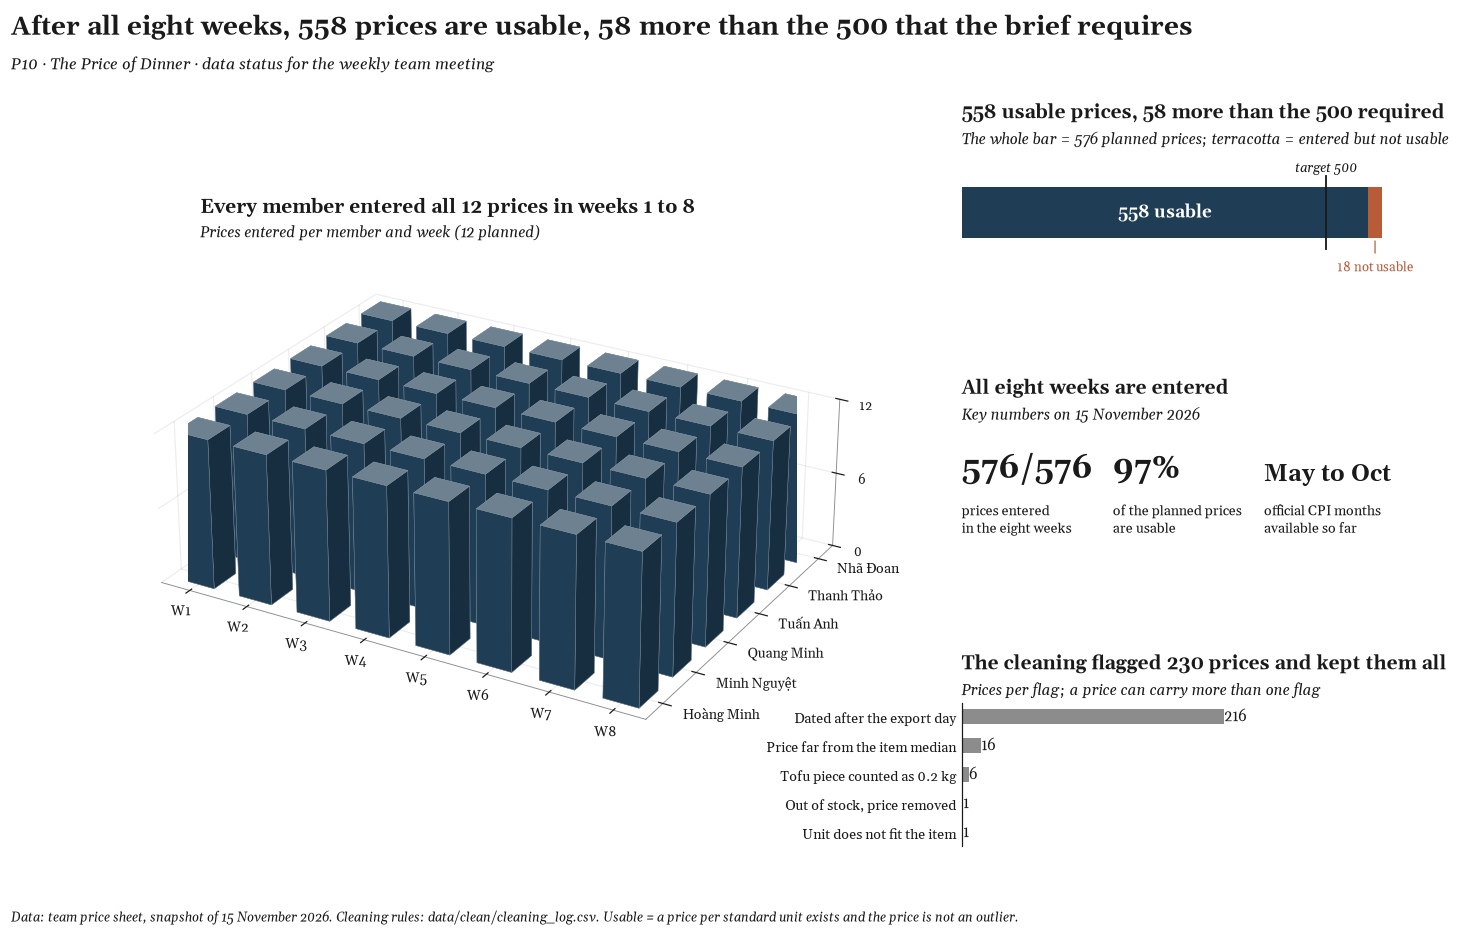

Prices entered per member and week:


week,1,2,3,4,5,6,7,8
assigned_to,,,,,,,,
Nguyễn Hoàng Minh,12,12,12,12,12,12,12,12
Nguyễn Minh Nguyệt,12,12,12,12,12,12,12,12
Phạm Quang Minh,12,12,12,12,12,12,12,12
Phạm Tuấn Anh,12,12,12,12,12,12,12,12
Trần Nguyễn Thanh Thảo,12,12,12,12,12,12,12,12
Trần Nhã Đoan,12,12,12,12,12,12,12,12


In [16]:
# M2.8 The data status figure: a 3D grid of prices per member and week, and three flat panels

# ---------------- numbers
PLANNED, TARGET, WEEKS = 576, 500, 8
grid = master.pivot_table(index="assigned_to", columns="week", values="collected", aggfunc="sum").reindex(columns=range(1, 9), fill_value=0)
grid = grid.loc[grid.sum(axis=1).sort_values().index]           # fewest prices in front
weeks_done = int((master.groupby("week")["collected"].sum() > 0).sum())
entered = int(master["collected"].sum())
usable = int(master["usable"].sum())
flagged = entered - usable
weeks_left = WEEKS - weeks_done
need_week = int(np.ceil(max(TARGET - usable, 0) / weeks_left)) if weeks_left else 0
n_flag_rows = int((master.loc[master["collected"], "flags"].fillna("") != "").sum())
missing = [(r, w) for r in grid.index for w in range(1, weeks_done + 1) if grid.loc[r, w] < 12]
flag_counts = (master.loc[master["collected"], "flags"].fillna("").str.split(";").explode().replace("", np.nan).dropna().value_counts())
FLAG_NAMES = {"assumed_weight": "Tofu piece counted as 0.2 kg", "outlier": "Price far from the item median",
              "out_of_stock": "Out of stock, price removed", "unit_mismatch": "Unit does not fit the item",
              "future_date": "Dated after the export day"}

DONE, MISS = CHANNEL["Siêu thị"], HIGHLIGHT
fig = plt.figure(figsize=(14, 8.2))
gs = fig.add_gridspec(3, 2, width_ratios=[1.45, 1], height_ratios=[1, 1, 1.05], hspace=1.0, wspace=0.32)

# ---------------- A: 3D skyline of prices entered per member and week
ax = fig.add_subplot(gs[:, 0], projection="3d")
names = list(grid.index)
d = 0.56
bars = [(w - 1, i, grid.loc[n, w]) for i, n in enumerate(names) for w in range(1, weeks_done + 1) if grid.loc[n, w] > 0]
x, y, z = (np.array(v, dtype=float) for v in zip(*bars))
ax.bar3d(x - d / 2, y - d / 2, 0, d, d, z, color=sum((faces3d(DONE) for _ in bars), []), shade=False,
         edgecolor=tint(DONE, 0.5), linewidth=0.25)
plan = [(w - 1, i) for i in range(len(names)) for w in range(weeks_done + 1, 9)]
if plan:
    px, py = (np.array(v, dtype=float) for v in zip(*plan))
    ax.bar3d(px - d / 2, py - d / 2, 0, d, d, 0.12, color="#E3E8ED", shade=False, edgecolor="#C9D2DA", linewidth=0.4)
for r, w in missing:
    ax.bar3d(w - 1 - d / 2, names.index(r) - d / 2, 0, d, d, 0.12, color=tint(MISS, 0.55), shade=False, edgecolor=MISS, linewidth=1.2)
ax.set_xticks(range(8), [f"W{w}" for w in range(1, 9)], fontsize=9)
ax.set_yticks(range(len(names)), [" ".join(n.split()[-2:]) for n in names], fontsize=9, ha="left", va="center")
ax.set_zticks([0, 6, 12], ["0", "6", "12"], fontsize=8.5)
ax.set_xlim(-0.5, 7.5); ax.set_ylim(-0.5, len(names) - 0.5); ax.set_zlim(0, 12)
ax.view_init(elev=26, azim=-60)
ax.set_box_aspect((8, 6, 2.4), zoom=1.12)
for a in (ax.xaxis, ax.yaxis, ax.zaxis):
    a.set_pane_color((1, 1, 1, 0)); a._axinfo["grid"]["color"] = (0, 0, 0, 0.07)
    a.line.set_color(GREY); a.line.set_linewidth(0.6)
ax.tick_params(axis="both", pad=0, colors=INK)
from mpl_toolkits.mplot3d import proj3d
for r, w in missing:   # 3D text is hidden behind the bars, so the label is drawn in 2D on top
    sx, sy, _ = proj3d.proj_transform(w - 1, names.index(r), 0.1, ax.get_proj())
    ax.annotate(f"{r.split()[-2]} {r.split()[-1]}: 0 of 12", xy=(sx, sy), xytext=(28, -26), textcoords="offset points",
                color=MISS, fontsize=10, fontweight="bold", zorder=10, bbox=dict(fc="white", ec="none", pad=1.5),
                arrowprops=dict(arrowstyle="-", color=MISS, lw=1, shrinkA=0, shrinkB=2))
if missing:
    grid_title = f"{len(missing)} member week{'s' if len(missing) > 1 else ''} still missing prices"
else:
    grid_title = "Every member entered all 12 prices in " + (f"weeks 1 and {weeks_done}" if weeks_done == 2 else f"weeks 1 to {weeks_done}")
ax.text2D(0.02, 0.97, grid_title, transform=ax.transAxes, fontsize=12.5, fontweight="bold")
ax.text2D(0.02, 0.93, "Prices entered per member and week (12 planned)" + ("; flat tiles = weeks not valid yet" if plan else ""),
          transform=ax.transAxes, fontsize=9.5, style="italic")

# ---------------- B: progress to 500
ax = fig.add_subplot(gs[0, 1])
ax.barh(0, usable, color=DONE, height=0.5)
ax.barh(0, flagged, left=usable, color=MISS, height=0.5)
rest = PLANNED - usable - flagged
if rest > 0:
    ax.barh(0, rest, left=usable + flagged, color="white", height=0.5, edgecolor=LIGHT, hatch="////", lw=0.5)
    ax.text(usable + flagged + rest / 2, 0, f"{rest} not entered", ha="center", va="center", fontsize=9.5)
ax.text(usable / 2, 0, f"{usable} usable", color="white", ha="center", va="center", fontsize=11, fontweight="bold")
ax.annotate(f"{flagged} not usable", (usable + flagged / 2, -0.25), xytext=(0, -14), textcoords="offset points",
            ha="center", va="top", fontsize=8.5, color=MISS, arrowprops=dict(arrowstyle="-", color=MISS, lw=0.8))
ax.plot([TARGET, TARGET], [-0.36, 0.36], color=INK, lw=1.2)
ax.text(TARGET, 0.4, "target 500", ha="center", fontsize=8.5, style="italic")
ax.set_xlim(0, PLANNED); ax.set_ylim(-0.75, 0.6); ax.axis("off")
title(ax, f"{usable} of the 500 required prices are usable" if usable < TARGET else f"{usable} usable prices, {usable - TARGET} more than the 500 required",
      f"The whole bar = {PLANNED} planned prices; terracotta = entered but not usable")

# ---------------- C: key numbers
ax = fig.add_subplot(gs[1, 1]); ax.axis("off")
cpi_span = f"{pd.Timestamp(hcmc['year_month'].min()):%b} to {pd.Timestamp(hcmc['year_month'].max()):%b}"
if weeks_left:
    tiles = [(f"{need_week}/72", "usable prices needed\nin each remaining week"), (f"{entered}", f"prices entered\nin {PERIOD}"),
             (cpi_span, "official CPI months\navailable so far")]
    head_c = f"Each remaining week needs {need_week} of its 72 prices"
else:
    tiles = [(f"{entered}/{PLANNED}", "prices entered\nin the eight weeks"), (f"{usable / PLANNED:.0%}", "of the planned prices\nare usable"),
             (cpi_span, "official CPI months\navailable so far")]
    head_c = "All eight weeks are entered"
for k, (big, small) in enumerate(tiles):
    x0 = k * 0.36
    ax.text(x0, 0.55, big, fontsize=21 if k < 2 else 15, fontweight="bold", color=MISS if (k == 0 and weeks_left) else INK, transform=ax.transAxes, va="bottom")
    ax.text(x0, 0.45, small, fontsize=9, transform=ax.transAxes, va="top")
title(ax, head_c, "Key numbers on " + SHEET_DATE)

# ---------------- D: flags
ax = fig.add_subplot(gs[2, 1])
fc = flag_counts.rename(index=FLAG_NAMES).sort_values()
ax.barh(fc.index, fc.values, color=GREY, height=0.5)
for i, v in enumerate(fc.values):
    ax.text(v + 0.05, i, f"{v}", va="center", fontsize=10)
ax.set_xlim(0, fc.max() * 1.6)
ax.spines[["bottom"]].set_visible(False); ax.set_xticks([]); ax.tick_params(axis="y", length=0)
title(ax, f"The cleaning flagged {n_flag_rows} prices and kept them all", "Prices per flag; a price can carry more than one flag")

fig_head = (f"After {NUM_WORD[weeks_done]} of eight weeks, {usable} prices are usable and the target is still within reach" if weeks_left
            else f"After all eight weeks, {usable} prices are usable, {abs(usable - TARGET)} {'more' if usable >= TARGET else 'fewer'} than the 500 that the brief requires")
figure_title(fig, fig_head,
             "P10 · The Price of Dinner · data status for the weekly team meeting", y=1.0)
note(fig, "Data: team price sheet, snapshot of " + SHEET_DATE + ". Cleaning rules: data/clean/cleaning_log.csv. "
          "Usable = a price per standard unit exists and the price is not an outlier.", y=0.04)
save(fig, FIG / "m2_data_status.png")
plt.show()
print("Prices entered per member and week:")
display(grid.astype(int))

### M2.9 · What my group learned from the data

1. **Quantities typed with a decimal point become dates.** The sheet uses the Vietnamese locale, so "2.5" turned into 2 May. My group fixes this in code and asks members to type "2,5".
2. **Tofu needs one standard unit.** Members wrote tofu prices per piece, per 280 g pack and per kg. My group uses kg and counts one piece as 0.2 kg, as the item specification says; a member should weigh one piece to check this.
3. **Some prices carry the wrong unit.** Sixteen prices sit far from their item's median. Some look like a whole fruit or a different pack written as 1 kg, for example watermelon at 320,000 VND per kg on the app and red tilapia at 65,000 VND for 300 g. All six tofu prices of week 6 (7,000 to 16,500 VND per kg) look like prices per piece written as per kg. Two cheap onion prices at the wet market in week 4 may be real. The pipeline flags all of them, and the team checks each one against its photo or screenshot.
4. **A new unit appeared.** One onion price on the app is per bulb ("củ"), which has no weight. The pipeline leaves it out until the team adds the bulb weight.
5. **Dates later than the export.** Weeks 6 to 8 carry dates from 18 to 30 November, later than the export of 15 November 2026. The team lead confirmed that the sheet holds all eight weeks, so these 216 prices enter the analysis with the flag `future_date`, and the team checks their dates against the photos. A typing error in the date column is the most likely cause.
6. **The official CPI arrives one month late.** October is now joined; November arrives in early December.
7. **The 20% rule does not fit a team of six.** If each price has one collector, a full share is 16.7%. My group will ask the lecturer whether a price that two members collect together can carry both names.

---
# M3 · House style, colour check, makeover, honest and misleading pair
This module explains the house style that Setup wrote to `house_style.py`, tests it for colour vision and greyscale, redesigns a press chart and shows how the same numbers can mislead. The page `report/M3_style.md` repeats the text for the report.

In [17]:
usable_prices = master[master["usable"]]      # the usable rows of the master table from M2

### M3.1 · The house style on one page

My group fixed five rules so that every chart in the project looks the same.

1. **Channels have fixed colours, always in the same order:** wet market (terracotta), supermarket (dark blue),
   delivery app (light blue). The three colours also differ in lightness, so they work in greyscale.
2. **Districts never get a colour.** Quận 10 uses a solid line or a circle, and Quận 3 a dashed line or a square.
3. **Amounts use the sequential blue map. Changes use the diverging map** with its centre at 100 for an index or at 0
   for a percentage change. My group never uses a rainbow map.
4. **A chart that compares a few magnitudes is drawn as 3D columns** with `bars3d()`: a light top, the base colour in
   front and darker sides. Three rules keep them honest: columns start at zero, the values that carry the finding are
   printed with `label3d()`, and the view stays low (about 20 degrees) so that the top of a column stays close to its
   value. Every other idiom keeps its own flat form: lines over time, dot plots, dumbbells, heatmaps, biplots,
   dendrograms and the panels of the dashboard.
5. **Text:** a serif font, a bold title that states the finding, an italic subtitle with the units, labels next to
   the data, and a source line at the bottom. Prices appear as "45k" in charts and as "45,000 VND" in tables.

**From v0 to v1.** My group wrote a first house style (v0) in Task 0 of Group Homework 3. Version 1 changes three things. First, v0 gave the wet market blue, the supermarket orange and the app teal; v1 gives the wet market terracotta and both other channels a blue, so that the highlight colour of the project is also the cheapest channel. The greyscale test of M3.2 then made my group darken the supermarket blue once more. Second, v0 used the ready made maps cividis and RdBu_r; v1 builds both maps from the channel colours, so that the whole project uses one family of colours, and the diverging map keeps light and dark ends that stay apart in greyscale. Third, v1 adds the 3D column style and the helpers `bars3d`, `style3d`, `label3d` and `title3d`.

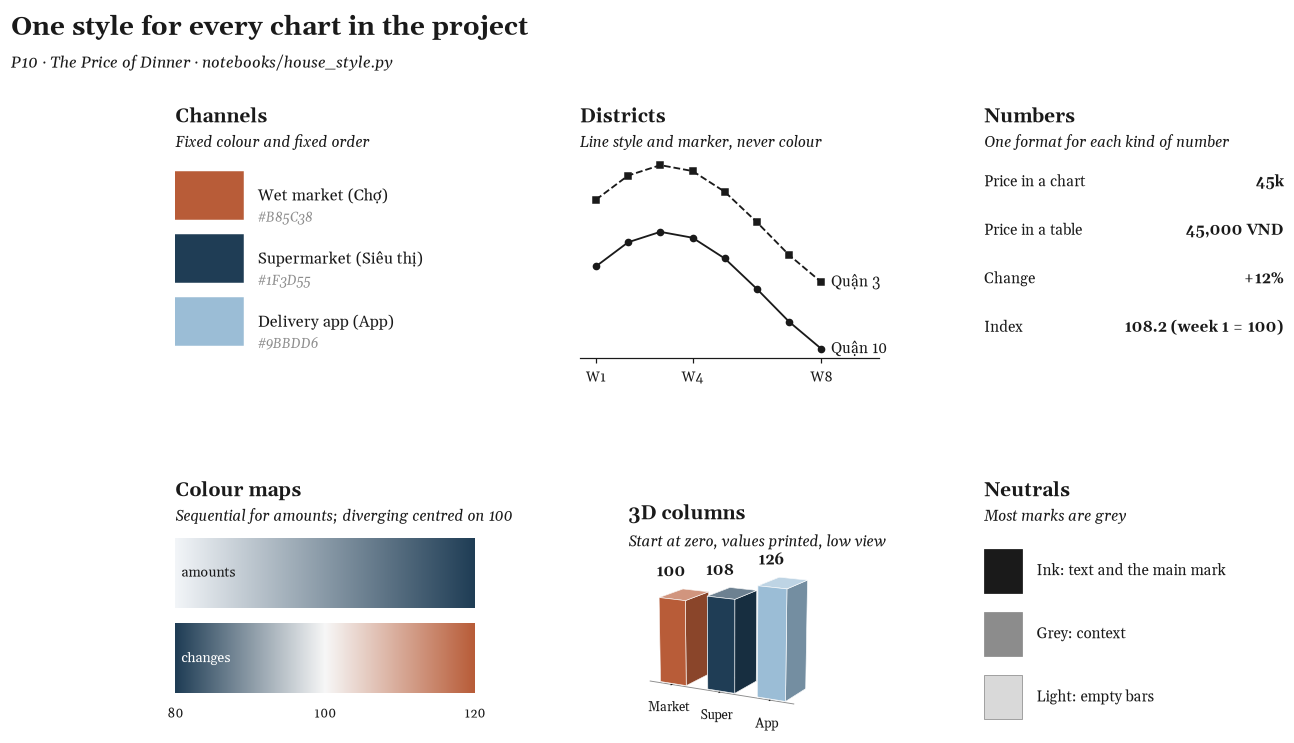

In [18]:
# M3.1 The house style on one page: colours, districts, numbers, colour maps, 3D columns and neutrals
fig = plt.figure(figsize=(13, 6.8))
gs = fig.add_gridspec(2, 3, hspace=0.85, wspace=0.35)

# A: channel colours
ax = fig.add_subplot(gs[0, 0]); ax.axis("off")
for i, ch in enumerate(CHANNEL_ORDER):
    ax.add_patch(plt.Rectangle((0, 2 - i), 0.9, 0.75, color=CHANNEL[ch]))
    ax.text(1.1, 2 - i + 0.37, f"{CHANNEL_EN[ch]} ({ch})", va="center", fontsize=10.5)
    ax.text(1.1, 2 - i + 0.02, CHANNEL[ch], va="center", fontsize=8.5, style="italic", color=GREY)
ax.set_xlim(0, 4); ax.set_ylim(-0.2, 3)
title(ax, "Channels", "Fixed colour and fixed order")

# B: districts
ax = fig.add_subplot(gs[0, 1])
x = np.arange(1, 9)
for d in DISTRICT_ORDER:
    y = 100 + (2 if d == "Quận 3" else 0) + np.sin(x / 2) * 2
    ax.plot(x, y, color=INK, ls=DISTRICT_LINE[d], marker=DISTRICT_MARKER[d], ms=4, lw=1.2)
    ax.text(8.3, y[-1], d, va="center", fontsize=9.5)
ax.set_xlim(0.5, 9.8); ax.set_xticks([1, 4, 8], ["W1", "W4", "W8"]); ax.set_yticks([])
ax.spines["left"].set_visible(False)
title(ax, "Districts", "Line style and marker, never colour")

# C: number formats
ax = fig.add_subplot(gs[0, 2]); ax.axis("off")
examples = [("Price in a chart", fmt_vnd(45000)), ("Price in a table", fmt_vnd(45000, short=False)),
            ("Change", fmt_pct(0.123, sign=True)), ("Index", "108.2 (week 1 = 100)")]
for i, (k, v) in enumerate(examples):
    ax.text(0, 0.85 - i * 0.24, k, fontsize=10, transform=ax.transAxes)
    ax.text(1, 0.85 - i * 0.24, v, fontsize=10, ha="right", fontweight="bold", transform=ax.transAxes)
title(ax, "Numbers", "One format for each kind of number")

# D: colour maps
ax = fig.add_subplot(gs[1, 0])
grad = np.linspace(0, 1, 256)[None, :]
ax.imshow(grad, aspect="auto", cmap=SEQ, extent=[0, 1, 0.55, 1])
ax.imshow(grad, aspect="auto", cmap=DIV, extent=[0, 1, 0, 0.45])
ax.text(0.02, 0.775, "amounts", va="center", fontsize=9, color=INK)
ax.text(0.02, 0.225, "changes", va="center", fontsize=9, color="white")
for xpos, lab in [(0, "80"), (0.5, "100"), (1, "120")]:
    ax.text(xpos, -0.08, lab, ha="center", va="top", fontsize=8.5)
ax.set_xlim(0, 1); ax.set_ylim(-0.25, 1.05); ax.axis("off")
title(ax, "Colour maps", "Sequential for amounts; diverging centred on 100")

# E: the 3D column style
ax = fig.add_subplot(gs[1, 1], projection="3d")
sample = [100, 108, 126]
bars3d(ax, range(3), [0] * 3, sample, [CHANNEL[c] for c in CHANNEL_ORDER], width=0.55, depth=0.55)
style3d(ax, elev=14, azim=-62, aspect=(3, 1, 2.2), zoom=1.0, zaxis=False, yaxis=False)
ax.set_xticks(range(3), ["Market", "Super", "App"], fontsize=8.5)
ax.set_zlim(0, 135)
for i, v in enumerate(sample):
    label3d(ax, i, -0.3, v, f"{v}", fontsize=9.5, fontweight="bold")
title3d(ax, "3D columns", "Start at zero, values printed, low view")

# F: neutrals
ax = fig.add_subplot(gs[1, 2]); ax.axis("off")
for i, (name, c) in enumerate([("Ink: text and the main mark", INK), ("Grey: context", GREY), ("Light: empty bars", LIGHT)]):
    ax.add_patch(plt.Rectangle((0, 2 - i), 0.5, 0.7, color=c, ec=GREY if c == LIGHT else c, lw=0.5))
    ax.text(0.7, 2 - i + 0.35, name, va="center", fontsize=9.5)
ax.set_xlim(0, 4); ax.set_ylim(-0.2, 3)
title(ax, "Neutrals", "Most marks are grey")

figure_title(fig, "One style for every chart in the project", "P10 · The Price of Dinner · notebooks/house_style.py", y=1.03)
save(fig, FIG / "m3_house_style.png")
plt.show()

### M3.2 · Colour vision and greyscale check

My group checks the palette in two ways.

* **Numbers.** `cvd_report()` simulates protanopia, deuteranopia and tritanopia with the matrices of Machado,
  Oliveira and Fernandes (2009) and converts the result to greyscale. It then measures the smallest colour
  difference (CIE76 ΔE) between any two channel colours. A ΔE above about 20 is easy to see on a screen.
* **Pictures.** The notebook draws one real 3D chart five times, once for each type of vision: the median price index of the three channels. Each panel holds only three columns, so the reader compares colours and nothing else.

In [19]:
report = pd.Series(cvd_report(CHANNEL)).rename("smallest ΔE between two channel colours").round(1)
report.to_frame()

,smallest ΔE between two channel colours
normal,50.5
protan,50.4
deutan,50.4
tritan,50.1
greyscale,25.1


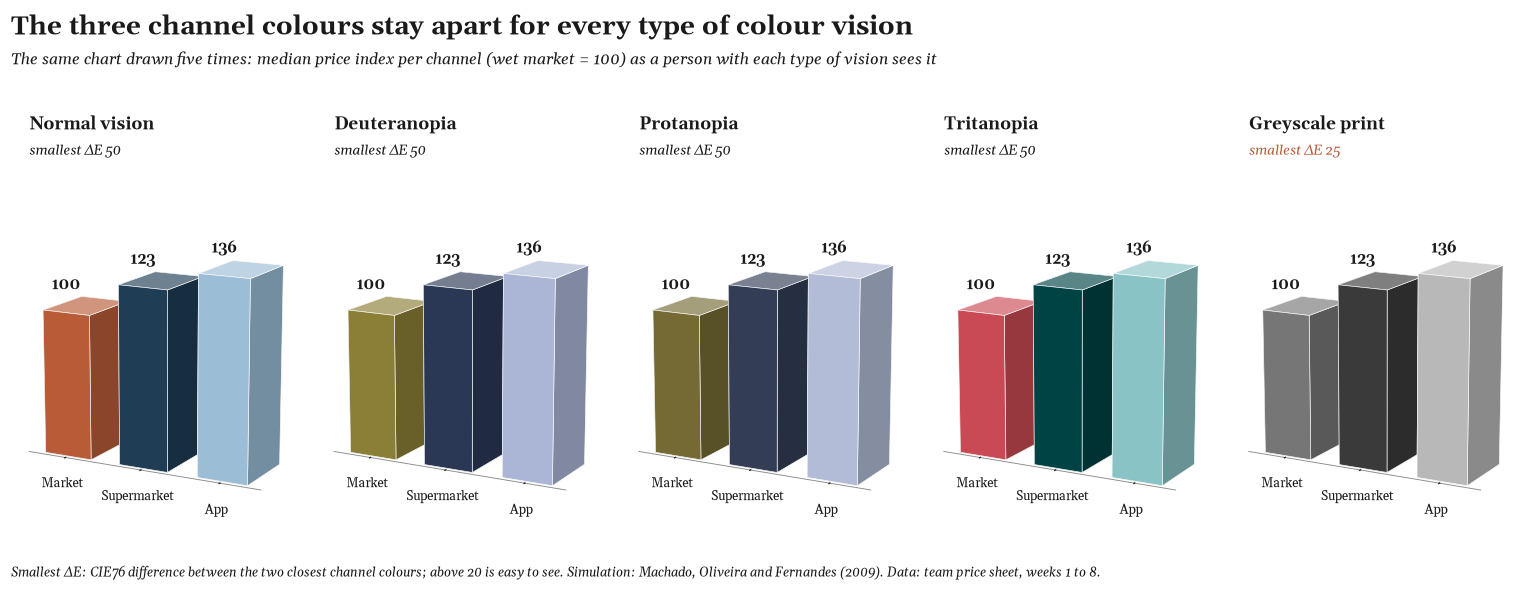

Median price index per channel: {'Chợ': 100.0, 'Siêu thị': 123.0, 'App': 136.0}


In [20]:
# M3.2 One real 3D chart (median price index per channel) as seen with each type of colour vision
item_avg = usable_prices.groupby(["item_code", "channel"])["price_std"].mean().unstack()[CHANNEL_ORDER]
idx = (item_avg.div(item_avg["Chợ"], axis=0) * 100).median()[CHANNEL_ORDER]
KINDS = [("normal", "Normal vision"), ("deutan", "Deuteranopia"), ("protan", "Protanopia"),
         ("tritan", "Tritanopia"), ("greyscale", "Greyscale print")]
SHORT_EN = {"Chợ": "Market", "Siêu thị": "Super-\nmarket", "App": "App"}

fig = plt.figure(figsize=(14, 4.6))
w = 0.19
for j, (kind, label) in enumerate(KINDS):
    x0 = 0.01 + j * 0.198
    ax = fig.add_axes([x0, 0.0, w, 0.8], projection="3d")
    cols = [to_hex(simulate(CHANNEL[c], kind)) for c in CHANNEL_ORDER]
    bars3d(ax, range(3), [0] * 3, idx.values, cols, width=0.62, depth=0.62)
    style3d(ax, elev=14, azim=-62, aspect=(3, 1, 2.4), zoom=1.15, zaxis=False, yaxis=False)
    ax.set_zlim(0, 140)
    ax.set_xticks(range(3), [SHORT_EN[c].replace("-\n", "") for c in CHANNEL_ORDER], fontsize=8.5)
    for i, v in enumerate(idx.values):
        label3d(ax, i, -0.31, v, f"{v:.0f}", fontsize=10, fontweight="bold")
    fig.text(x0 + 0.012, 0.86, label, fontsize=11, fontweight="bold", ha="left")
    fig.text(x0 + 0.012, 0.81, f"smallest ΔE {report[kind]:.0f}", fontsize=9, style="italic", ha="left",
             color=HIGHLIGHT if report[kind] < 30 else INK)
figure_title(fig, "The three channel colours stay apart for every type of colour vision",
             "The same chart drawn five times: median price index per channel (wet market = 100) as a person with each type of vision sees it", y=1.03)
note(fig, "Smallest ΔE: CIE76 difference between the two closest channel colours; above 20 is easy to see. "
          f"Simulation: Machado, Oliveira and Fernandes (2009). Data: team price sheet, {PERIOD}.", y=0.0)
save(fig, FIG / "m3_cvd_check.png")
plt.show()
print("Median price index per channel:", idx.round(0).to_dict())

**What my group concludes.** Under the three colour vision simulations, the smallest difference stays above 45 ΔE.
Greyscale is the hardest case, with about 25 ΔE between the supermarket and the wet market, which is still above
the guide value of 20. In greyscale the three colours keep their order from dark to light (supermarket, wet market,
app), so a printed report stays readable.

My group changed the palette once because of this check. The first version used a lighter supermarket blue
(#2C4F6B) and a darker app blue (#8FB3CF). That version passed all three colour vision tests, but in greyscale the
wet market and the supermarket were only 17 ΔE apart. A darker supermarket blue and a lighter app blue fixed it. My group still writes the channel name next to the marks in every final chart, so no reader
has to rely on colour alone.

### M3.3 · Makeover of a press chart about inflation
**The original.** My group chose Figure 5 on page 13 of the report *Tổng quan thị trường giá cả tháng 9, quý III và 9 tháng năm 2026* (Overview of prices in September, the third quarter and the first nine months of 2026) by the Cục Thống kê (National Statistics Office, Ministry of Finance). The report is dated 30 September 2026 and was published on 3 October 2026 with the [press release](https://www.nso.gov.vn/tin-tuc-thong-ke/2026/10/thong-cao-bao-chi-ve-tinh-hinh-gia-thang-chin-quy-iii-va-9-thang-nam-2026/). My group read the report on 19 October 2026 through this [PDF](https://www.nso.gov.vn/wp-content/uploads/2026/10/Tong-quan-CPI-chi-so-gia-vang-do-la-My-thang-9-QIII-va-9-thang-nam-2026.pdf). My group first planned this makeover in Group Homework 3.

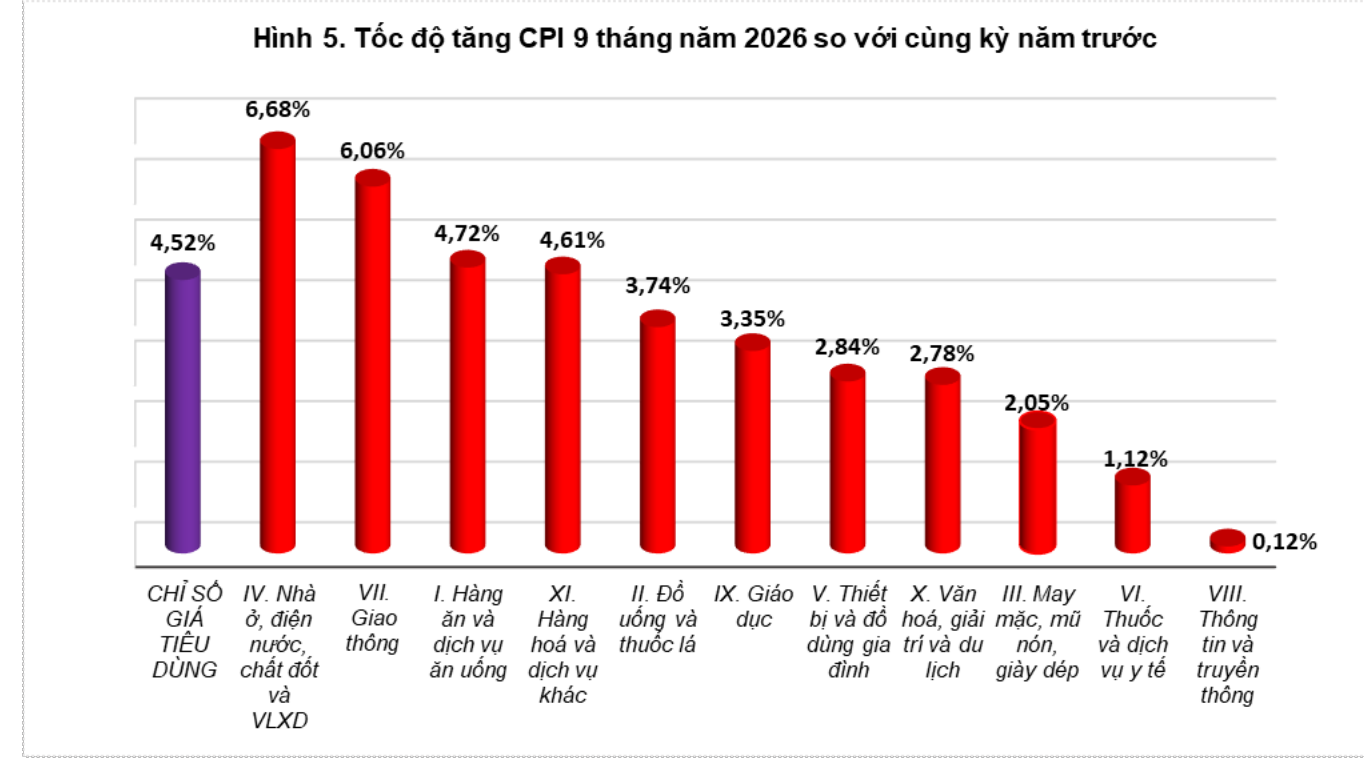

Figure 5 shows how much the prices of each of the 11 groups of goods and services rose in the first nine months of 2026, compared with the same months of 2025. The text under the chart asks which groups pushed the CPI up, so my group takes that as the task of the chart.

| # | What my group sees | Principle broken | Effect on the reader | My group's fix |
|---|---|---|---|---|
| 1 | Every bar is a shaded 3D cylinder with an oval top, and the smallest group (0.12%) appears only as a red disc | Data ink and expressiveness | The reader has to judge where an oval top ends, and the 0.12% group looks like a blob instead of a bar that is almost zero | Flat bars on a common baseline at zero |
| 2 | The national CPI (4.52%) is one more bar, in purple, at the left end of the row of groups | Gestalt similarity and expressiveness | The reader takes the average for a twelfth group and has to compare every red bar with a purple bar far away | A reference line at 4.52% across all the groups |
| 3 | All eleven groups have the same strong red | Colour job and preattentive attention | Red signals danger for every group, so no group stands out | All groups grey, and one colour for food and catering, the group that our project studies |
| 4 | The labels carry Roman numerals and wrap over up to five lines in small italics | Short term memory and effectiveness | The reader has to decode codes such as IV. and XI. and read five short lines under each narrow bar | Horizontal bars with short names on one line |
| 5 | The chart has gridlines, but the axis has no numbers | Data ink | The gridlines cannot be read, so they add clutter | No gridlines, and a value label on every bar |
| 6 | The chart shows only how fast prices rose; the text says that food and catering added the most to the CPI (1.69 percentage points) | Expressiveness: the chart does not fit the task | The reader concludes that housing and transport drove inflation | A second panel that shows how many points each group added to the CPI |

**Why this redesign stays flat.** The redesign compares magnitudes, so the rule of M3.1 would ask for 3D columns. The makeover is the one exception: the first problem that my group names in the original is its 3D cylinders, so a 3D redesign would repeat the error that the critique describes.

**The hand sketch** that my group drew before coding the redesign:

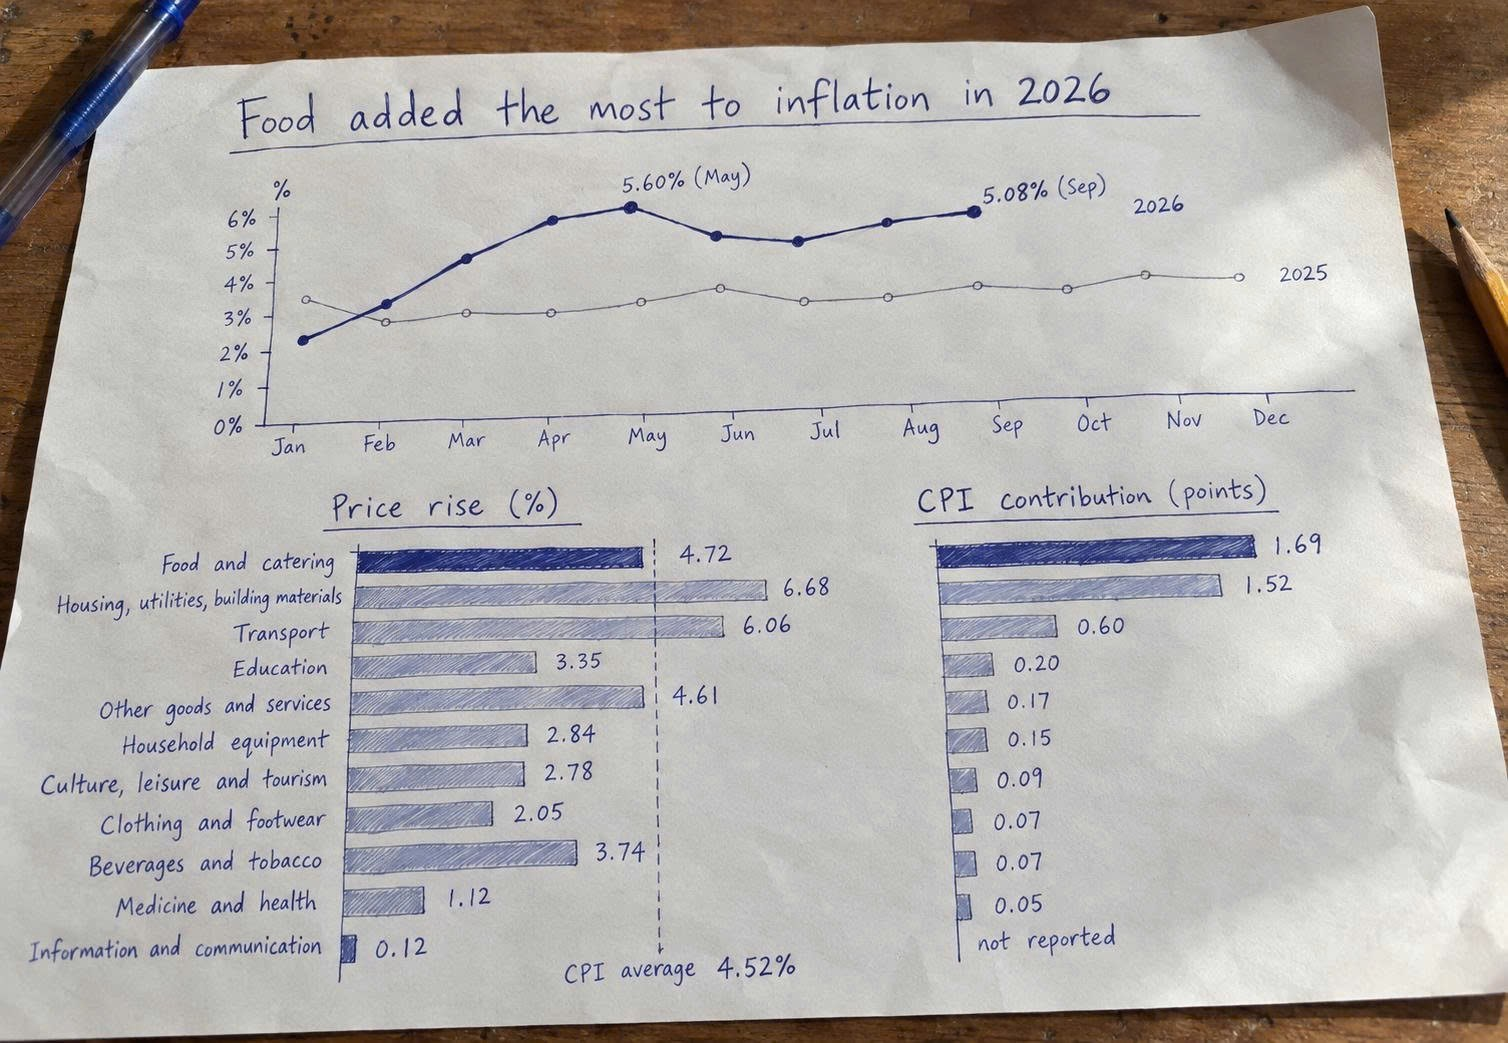

In [21]:
# M3.3 The numbers of the redesign, typed from the NSO report: monthly CPI rates (Figure 4, page 12),
# group rates (Figure 5, page 13) and contributions to the CPI (text on pages 13 and 14)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
cpi_2025 = [3.63, 2.91, 3.13, 3.12, 3.24, 3.57, 3.19, 3.24, 3.38, 3.25, 3.58, 3.48]   # % against the same month of 2024
cpi_2026 = [2.53, 3.35, 4.65, 5.46, 5.60, 4.69, 4.45, 4.88, 5.08]                     # % against the same month of 2025
CPI_9M = 4.52                                                                         # average of January to September 2026, %
groups = pd.DataFrame({
    "group": ["Housing, utilities, building materials", "Transport", "Food and catering",
              "Other goods and services", "Beverages and tobacco", "Education", "Household equipment",
              "Culture, leisure and tourism", "Clothing and footwear", "Medicine and health",
              "Information and communication"],
    "rate": [6.68, 6.06, 4.72, 4.61, 3.74, 3.35, 2.84, 2.78, 2.05, 1.12, 0.12],
    "points": [1.52, 0.60, 1.69, 0.17, 0.07, 0.20, 0.15, 0.09, 0.07, 0.05, np.nan],
}).sort_values("points", na_position="first").reset_index(drop=True)
FOCUS = "Food and catering"
food = groups.set_index("group").loc[FOCUS]
months_above = [MONTHS[i] for i in range(len(cpi_2026)) if cpi_2026[i] > cpi_2025[i]]
print("Groups that rose faster than food:", groups.loc[groups["rate"] > food["rate"], "group"].tolist())
print("Largest contribution:", groups.loc[groups["points"].idxmax(), "group"], groups["points"].max(), "points")
print("Months of 2026 above the same month of 2025:", months_above)

Groups that rose faster than food: ['Transport', 'Housing, utilities, building materials']
Largest contribution: Food and catering 1.69 points
Months of 2026 above the same month of 2025: ['Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep']


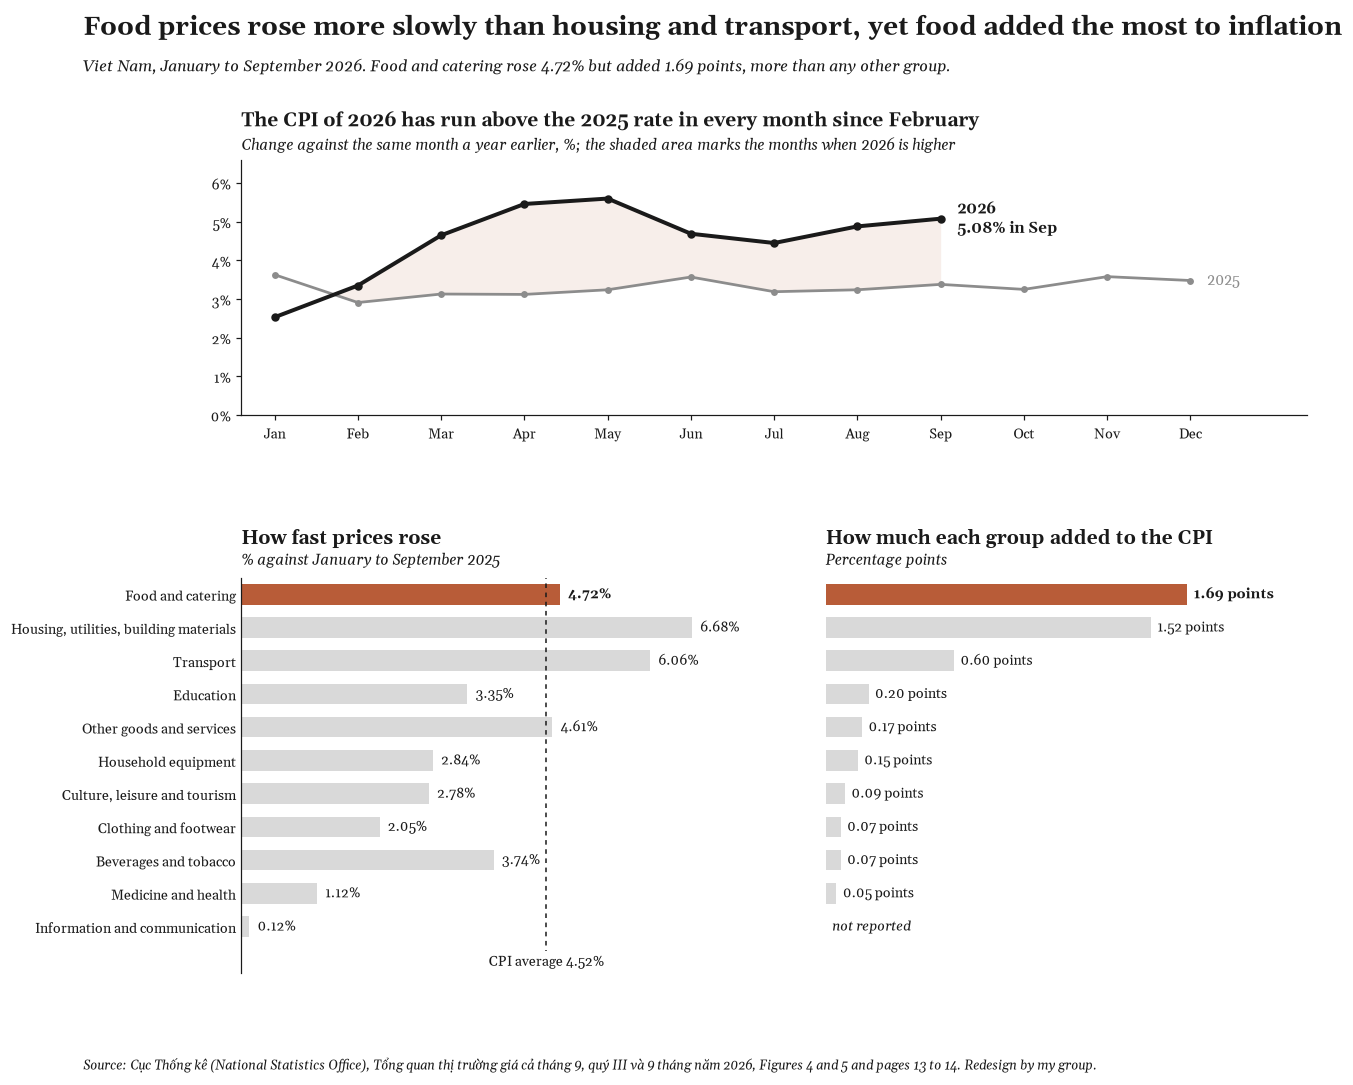

In [22]:
# M3.3 The redesign: the CPI month by month on top, and two aligned bar panels for the groups below
fig = plt.figure(figsize=(12.5, 9.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.55], width_ratios=[1.15, 1], hspace=0.5, wspace=0.06)
ax_m, ax_r = fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0])
ax_p = fig.add_subplot(gs[1, 1], sharey=ax_r)

x25, x26 = np.arange(12), np.arange(len(cpi_2026))
ax_m.fill_between(x26, cpi_2025[:len(x26)], cpi_2026, where=np.array(cpi_2026) > np.array(cpi_2025[:len(x26)]),
                  interpolate=True, color=HIGHLIGHT, alpha=0.10, lw=0)
ax_m.plot(x25, cpi_2025, color=GREY, lw=1.8, marker="o", ms=3.5)
ax_m.plot(x26, cpi_2026, color=INK, lw=2.6, marker="o", ms=4.5)
ax_m.text(11.2, cpi_2025[-1], "2025", va="center", color=GREY, fontsize=10)
ax_m.text(x26[-1] + 0.2, cpi_2026[-1], f"2026\n{cpi_2026[-1]:.2f}% in Sep", va="center", fontsize=10, fontweight="bold")
ax_m.set_xticks(x25, MONTHS); ax_m.set_xlim(-0.4, 12.4); ax_m.set_ylim(0, 6.6)
ax_m.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
title(ax_m, "The CPI of 2026 has run above the 2025 rate in every month since February",
      "Change against the same month a year earlier, %; the shaded area marks the months when 2026 is higher")

colors = [HIGHLIGHT if g == FOCUS else LIGHT for g in groups["group"]]
y = np.arange(len(groups))
ax_r.barh(y, groups["rate"], color=colors, height=0.62)
ax_r.axvline(CPI_9M, color=INK, lw=1, ls=(0, (3, 3)))
ax_r.text(CPI_9M, -0.8, f"CPI average {CPI_9M:.2f}%", ha="center", va="top", fontsize=9,
          bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
for yi, (g, r) in enumerate(zip(groups["group"], groups["rate"])):
    ax_r.text(r + 0.12, yi, f"{r:.2f}%", va="center", fontsize=9, fontweight="bold" if g == FOCUS else "normal")
ax_r.set_yticks(y, groups["group"]); ax_r.set_ylim(-1.4, len(groups) - 0.5); ax_r.set_xlim(0, 8.2)
ax_r.set_xticks([]); ax_r.spines["bottom"].set_visible(False); ax_r.tick_params(axis="y", length=0)
title(ax_r, "How fast prices rose", "% against January to September 2025")

ax_p.barh(y, groups["points"].fillna(0), color=colors, height=0.62)
for yi, (g, p) in enumerate(zip(groups["group"], groups["points"])):
    ax_p.text((0 if np.isnan(p) else p) + 0.03, yi, "not reported" if np.isnan(p) else f"{p:.2f} points",
              va="center", fontsize=9, style="italic" if np.isnan(p) else "normal", fontweight="bold" if g == FOCUS else "normal")
ax_p.set_xlim(0, 2.25); ax_p.set_xticks([]); ax_p.spines[["bottom", "left"]].set_visible(False)
ax_p.tick_params(axis="y", length=0, labelleft=False)
title(ax_p, "How much each group added to the CPI", "Percentage points")

figure_title(fig, "Food prices rose more slowly than housing and transport, yet food added the most to inflation",
             f"Viet Nam, January to September 2026. Food and catering rose {food['rate']:.2f}% but added {food['points']:.2f} points, more than any other group.",
             y=0.99)
note(fig, "Source: Cục Thống kê (National Statistics Office), Tổng quan thị trường giá cả tháng 9, quý III và 9 tháng năm 2026, "
          "Figures 4 and 5 and pages 13 to 14. Redesign by my group.", y=0.03)
save(fig, FIG / "m3_makeover_redesign.png")
plt.show()

**Makeover text (150 words).** The original Figure 5 draws eleven CPI groups as red 3D cylinders and the national average as a purple bar beside them. The 3D shading breaks the data ink principle, because the reader must guess where each oval top ends, and the purple bar breaks Gestalt similarity, because it looks like a twelfth group. The chart also fails its task: the text asks which groups pushed the CPI up, but the bars show only how fast prices rose. My group redrew it with flat horizontal bars on a zero baseline and the average as a dashed line. A second aligned panel shows how many points each group added to the CPI. Food and catering is the only coloured group, and the title states the finding: food prices rose more slowly than housing and transport, yet food added the most to inflation, because it weighs most in the basket.

### M3.4 · Honest and misleading pair
Both charts show the same three numbers: the cost of one basket of our twelve items in each channel. The basket holds 1 kg of each item sold by weight (tofu included) and 10 eggs, the same basket as Chart 3 of M4, at the average price of all valid weeks in both districts. Both charts use the 3D column style of the project, so the pair shows exactly which choices turn the same style from honest into misleading.

In [23]:
QTY = {code: 1.0 for code in master["item_code"].unique()}
QTY["SP11"] = 10                       # eggs are priced per egg
item_avg = usable_prices.groupby(["item_code", "channel"])["price_std"].mean().unstack()[CHANNEL_ORDER]
basket = item_avg.mul(pd.Series(QTY), axis=0).sum()
premium = basket / basket["Chợ"] - 1
pd.DataFrame({"basket_vnd": basket.round(-3), "vs_wet_market": premium.map(lambda v: fmt_pct(v, 0, sign=True))})

,basket_vnd,vs_wet_market
channel,,
Chợ,1037000.0,+0%
Siêu thị,1174000.0,+13%
App,1314000.0,+27%


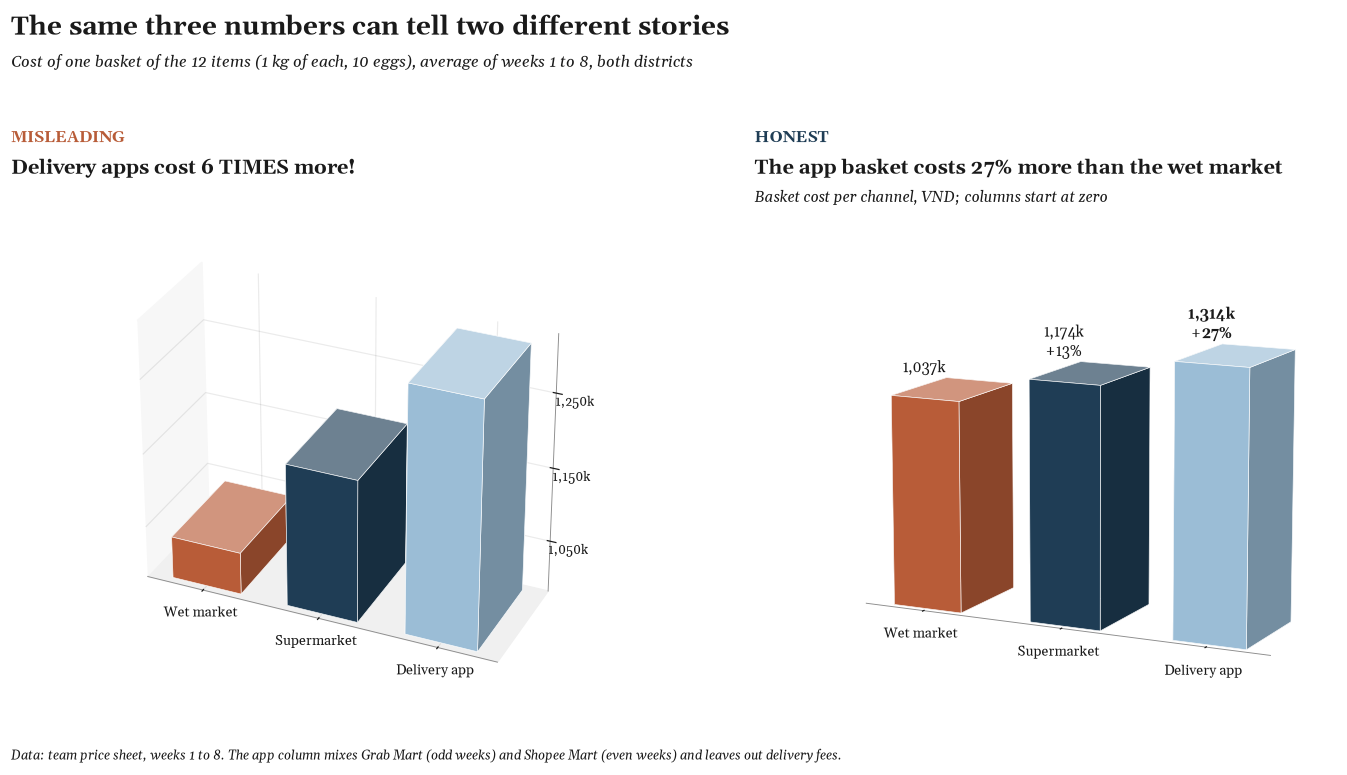

Misleading chart: the app column is 5.8 times as tall as the wet market column above the cut. Real ratio: 1.27.


In [24]:
# M3.4 The same basket costs drawn twice in 3D: misleading (cut axis, steep view, no values) and honest
low = np.floor(basket.min() / 50_000) * 50_000 - 20_000
ratio_bars = (basket["App"] - low) / (basket["Chợ"] - low)
colors = [CHANNEL[c] for c in CHANNEL_ORDER]
names = [CHANNEL_EN[c] for c in CHANNEL_ORDER]
fig = plt.figure(figsize=(13, 6.4))

fig.text(0.01, 0.86, "MISLEADING", fontsize=10.5, fontweight="bold", color=HIGHLIGHT)
fig.text(0.01, 0.815, f"Delivery apps cost {ratio_bars:.0f} TIMES more!", fontsize=13, fontweight="bold")
a1 = fig.add_axes([0.0, 0.02, 0.48, 0.76], projection="3d")
bars3d(a1, range(3), [0] * 3, basket.values, colors, width=0.6, depth=0.6, base=low)
style3d(a1, elev=30, azim=-66, aspect=(3, 1.1, 2.3), zoom=0.92, grid=True, yaxis=False)
a1.zaxis.set_pane_color((0.94, 0.94, 0.94, 1)); a1.xaxis.set_pane_color((0.97, 0.97, 0.97, 1))
a1.set_zlim(low, basket.max() * 1.01)
a1.set_zticks(np.arange(1_050_000, basket.max(), 100_000))
a1.zaxis.set_major_formatter(lambda v, _: fmt_vnd(v))
a1.set_xticks(range(3), names, fontsize=9)

fig.text(0.53, 0.86, "HONEST", fontsize=10.5, fontweight="bold", color=CHANNEL["Siêu thị"])
fig.text(0.53, 0.815, f"The app basket costs {fmt_pct(premium['App'])} more than the wet market", fontsize=13, fontweight="bold")
fig.text(0.53, 0.775, "Basket cost per channel, VND; columns start at zero", fontsize=9.5, style="italic")
a2 = fig.add_axes([0.52, 0.02, 0.48, 0.72], projection="3d")
XH = [0, 1.45, 2.9]
bars3d(a2, XH, [0] * 3, basket.values, colors, width=0.72, depth=0.6)
style3d(a2, elev=12, azim=-64, aspect=(3.4, 1, 2.2), zoom=1.05, zaxis=False, yaxis=False)
a2.set_zlim(0, basket.max() * 1.05)
a2.set_xticks(XH, names, fontsize=9)
for i, c in enumerate(CHANNEL_ORDER):
    txt = fmt_vnd(basket[c]) + ("" if c == "Chợ" else f"\n{fmt_pct(premium[c], 0, sign=True)}")
    label3d(a2, XH[i], -0.31, basket[c], txt, dy=14, fontsize=10, fontweight="bold" if c == "App" else "normal")

figure_title(fig, "The same three numbers can tell two different stories",
             f"Cost of one basket of the 12 items (1 kg of each, 10 eggs), average of {PERIOD}, both districts", y=1.0)
note(fig, f"Data: team price sheet, {PERIOD}. The app column mixes Grab Mart (odd weeks) and Shopee Mart (even weeks) and leaves out delivery fees.", y=0.0)
save(fig, FIG / "m3_honest_vs_misleading.png")
plt.show()
print(f"Misleading chart: the app column is {ratio_bars:.1f} times as tall as the wet market column above the cut. "
      f"Real ratio: {basket['App'] / basket['Chợ']:.2f}.")

**How the misleading chart misleads.** It uses three tricks at once. First, the value axis starts just below the cheapest basket instead of at zero, so the reader compares only the tops of the columns, and a gap of about a quarter looks like a gap of several hundred percent (the printed ratio under the chart). Second, the steep view tilts the columns, so the top of each column sits far from its value on the axis. Third, no value is printed, so the reader has nothing to check the picture against. The shouting title repeats the false ratio. In Tufte's terms, the Lie Factor is far above 1.

**How a reader can spot it.** The reader checks the lowest number on the value axis. If it is not zero, the column heights do not show the values. A tilted 3D chart without printed values is a second warning sign.

**What the honest chart does.** It keeps the same 3D style but starts the columns at zero, uses a low view, prints the money and the percentage gap on each column, and states the real size of the gap in the title. The app basket still leaves out the delivery fee; Chart 6 of M4 adds it.

---
# M4 · Core charts that answer the four questions
**What the brief asks.** At least six charts, one for each task, with at least five different idioms. Each chart starts with three lines: the task, why the idiom fits, and the action title. Every chart is sketched by hand before coding (photos in `evidence/sketches/`). Four charts are required: a dot plot of channel prices by item, a line chart of the basket cost per channel over the weeks, a bar chart of the channel premium, and a two panel chart that compares our index with the CPI (no dual axis). One chart goes through an AI audit.

**Choice of idioms.** My group draws a chart as 3D columns when its job is to compare a few magnitudes (the team style of M3). A chart whose task needs another idiom keeps that idiom: a line for change over time, two panels for the CPI comparison, a dot plot and a dumbbell for exact comparisons on one line. This gives M4 five idioms: 3D columns (as a grid, a row and a stack), a dot plot, a line chart, two aligned panels and a dumbbell.

| Chart | Task (Section M1.2) | Idiom | Status |
|---|---|---|---|
| 1 | Compare the price per kg across the three channels for each item | 3D column grid | Done |
| 1b | The same task, as the brief requires | Dot plot | Done |
| 2 | Rank the channels by their premium over the wet market | 3D columns | Done |
| 3 | Track the basket cost per channel week by week | Line | Done |
| 4 | Compare our price index with the NSO food CPI | Two panels on one time axis | Done; the November CPI arrives in early December |
| 5 | Compare the two districts for each item | Dumbbell | Done |
| 6 | Add the delivery fee to the basket of each channel | Stacked 3D columns | Done |
| 7 | Estimate the weekly basket for three student personas | Stacked bar | Waits for the student survey |
| AI audit | Chart 3 given to an AI tool by a member | Prompt, raw output, at least three errors, fix | To do by the team (Section M4.8) |

**Weeks used.** The analysis uses all eight weeks. Rows dated after the export day carry the flag `future_date` (Section M2.3) so that the team checks their dates against the photos.

### M4.1 · Chart 1: channel prices by item
*Task:* compare the price per kg across the three channels for each of the 12 items.
*Why this chart:* A grid of 3D columns, with the items along one axis and the three channels along the other, shows all 36 prices at once. My group shows each price as an index with the wet market at 100, because the items differ in price by a factor of one hundred (an egg against a kilogram of mackerel). The wet market row stands in front, the supermarket in the middle and the app at the back, so the cheaper rows never hide the dearer ones.
*Choices:* Items run from the largest app premium on the left to the smallest on the right. The app values are printed on top of the back row, and the full table is printed below the chart.

Delivery app dearest in 12 of 12 items; wet market cheapest in 12 of 12 items


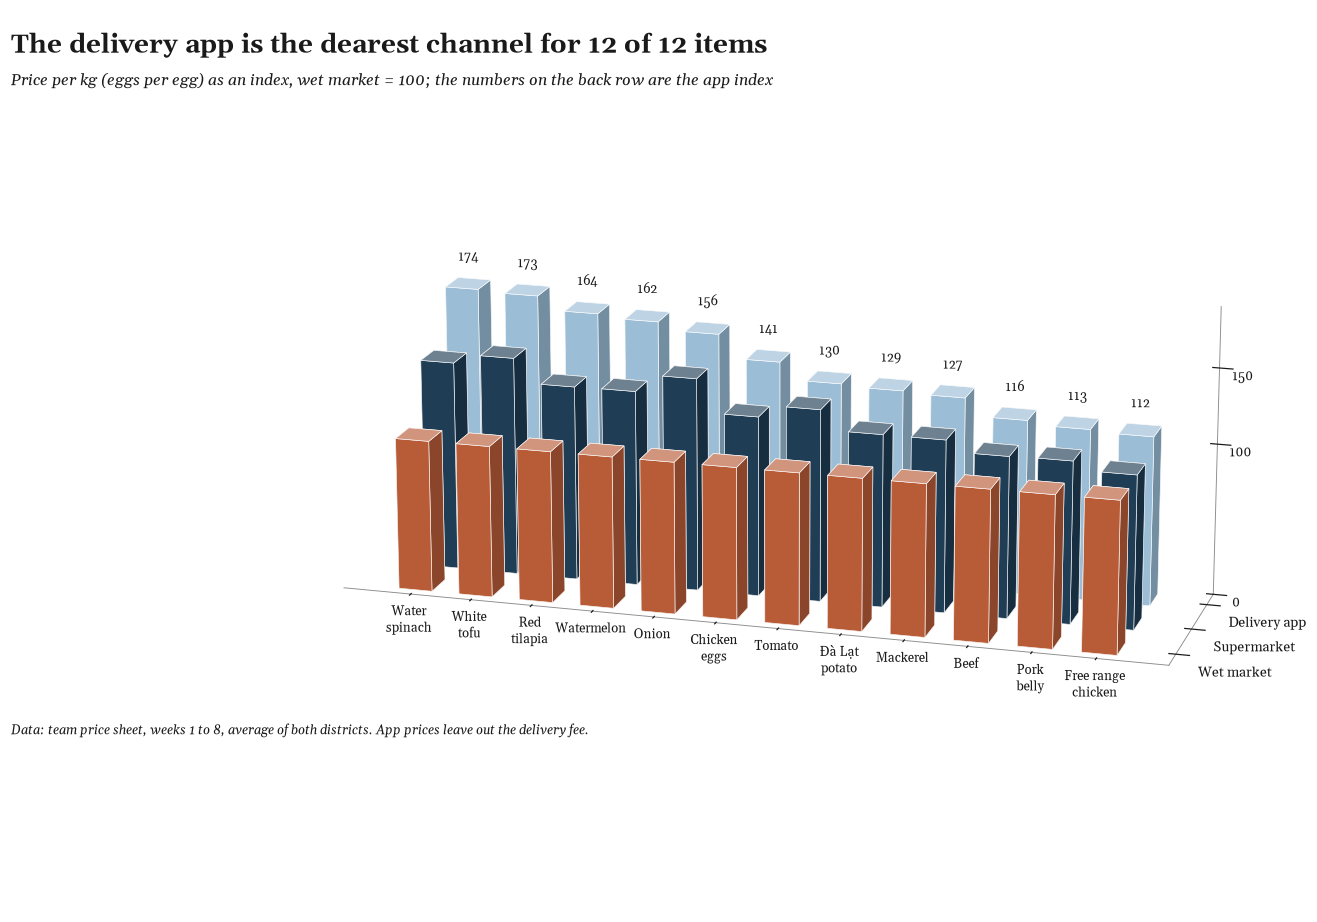

channel,Chợ,Siêu thị,App
item_code,,,
Water spinach,100.0,138.010563,174.005282
White tofu,100.0,144.303332,172.632292
Red tilapia,100.0,128.565878,163.803637
Watermelon,100.0,128.848485,161.527093
Onion,100.0,140.510173,156.417654
Chicken eggs,100.0,118.712329,141.123288
Tomato,100.0,126.814729,129.96503
Đà Lạt potato,100.0,113.869025,128.58211
Mackerel,100.0,113.764012,127.199326


In [25]:
# M4.1 Relative price of each item per channel, wet market = 100, average of all valid weeks and both districts
ITEM_EN = {"SP01": "Pork belly", "SP02": "Water spinach", "SP03": "Mackerel", "SP04": "Tomato", "SP05": "Beef",
           "SP06": "Free range chicken", "SP07": "Watermelon", "SP08": "Onion", "SP09": "Đà Lạt potato",
           "SP10": "White tofu", "SP11": "Chicken eggs", "SP12": "Red tilapia"}
SHORT = {"Red tilapia": "Red\ntilapia", "White tofu": "White\ntofu", "Water spinach": "Water\nspinach",
         "Chicken eggs": "Chicken\neggs", "Free range chicken": "Free range\nchicken", "Pork belly": "Pork\nbelly",
         "Đà Lạt potato": "Đà Lạt\npotato"}
rel = item_avg.div(item_avg["Chợ"], axis=0) * 100
rel = rel.rename(index=ITEM_EN).sort_values("App", ascending=False)
n_app_dearest = int((rel["App"] > rel[["Chợ", "Siêu thị"]].max(axis=1)).sum())
n_market_cheapest = int((rel["Chợ"] <= rel[["Siêu thị", "App"]].min(axis=1)).sum())
print(f"Delivery app dearest in {n_app_dearest} of 12 items; wet market cheapest in {n_market_cheapest} of 12 items")

fig = plt.figure(figsize=(14, 6.6))
ax = fig.add_axes([-0.1, -0.2, 1.2, 1.24], projection="3d")
xs, ys, hs, cs = [], [], [], []
for i, item in enumerate(rel.index):
    for j, ch in enumerate(CHANNEL_ORDER):
        xs.append(i); ys.append(j); hs.append(rel.loc[item, ch]); cs.append(CHANNEL[ch])
bars3d(ax, xs, ys, hs, cs, width=0.55, depth=0.5)
style3d(ax, elev=17, azim=-74, aspect=(6.5, 1.7, 2.3), zoom=1.0)
ax.set_xticks(range(len(rel)), [SHORT.get(n, n) for n in rel.index], fontsize=8.5, ha="center", va="top")
ax.set_yticks(range(3), [CHANNEL_EN[c] for c in CHANNEL_ORDER], fontsize=9, ha="left")
ax.set_zticks([0, 100, 150], ["0", "100", "150"]); ax.set_zlim(0, 190)
for i, item in enumerate(rel.index):
    label3d(ax, i, 2, rel.loc[item, "App"], f"{rel.loc[item, 'App']:.0f}", fontsize=8.5, color=INK)
figure_title(fig, f"The delivery app is the dearest channel for {n_app_dearest} of 12 items",
             "Price per kg (eggs per egg) as an index, wet market = 100; the numbers on the back row are the app index", y=0.97)
note(fig, f"Data: team price sheet, {PERIOD}, average of both districts. App prices leave out the delivery fee.", y=0.06)
save(fig, FIG / "m4_chart1_channel_prices.png")
plt.show()
display(rel.round(0))

#### M4.1b · The dot plot that the brief requires
The brief asks for a dot plot of the channel prices by item, so my group keeps it next to the 3D grid. It shows the same index. In the dot plot the reader compares positions on one line, which is more exact; in the 3D grid the reader sees the whole pattern at once. Module M8 will test which version readers use better.

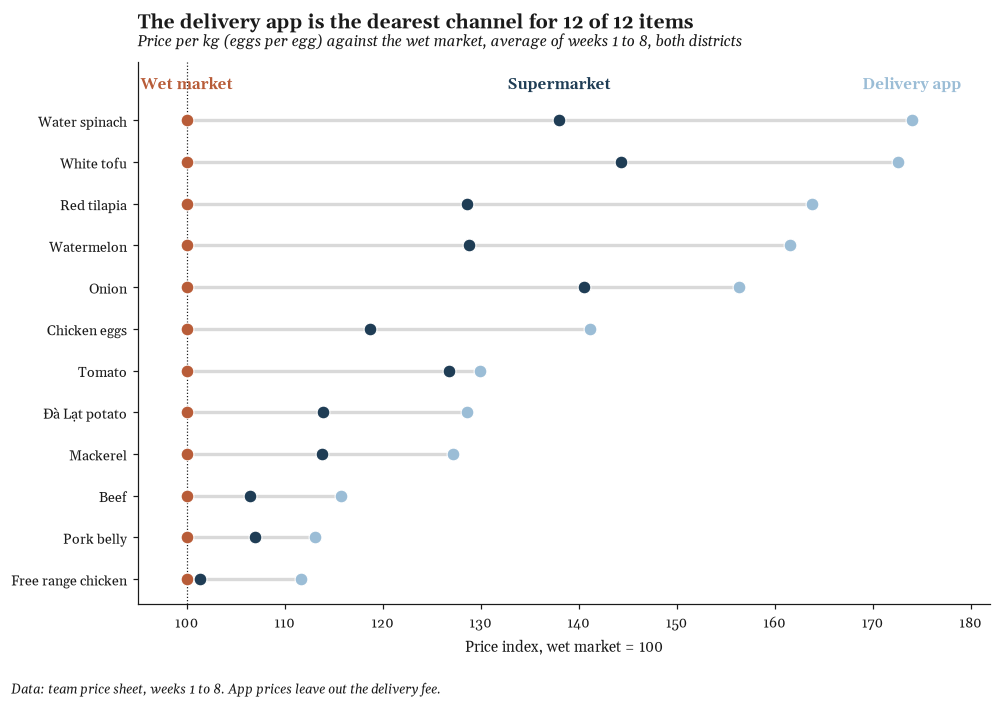

In [26]:
# M4.1b The dot plot that the brief requires: the same index as M4.1, items sorted by the app index
rel_dot = rel.sort_values("App")
fig, ax = plt.subplots(figsize=(10, 6.4))
for i, item in enumerate(rel_dot.index):
    row = rel_dot.loc[item]
    ax.plot([row.min(), row.max()], [i, i], color=LIGHT, lw=2.2, zorder=1)
    for ch in CHANNEL_ORDER:
        ax.scatter(row[ch], i, s=70, color=CHANNEL[ch], zorder=3, edgecolor="white", lw=0.7)
ax.axvline(100, color=INK, lw=0.8, ls=":")
top = len(rel_dot) - 1
for ch, dy in zip(CHANNEL_ORDER, [0.75, 0.75, 0.75]):
    ax.text(rel_dot.iloc[-1][ch], top + dy, CHANNEL_EN[ch], color=CHANNEL[ch], ha="center", fontsize=9.5, fontweight="bold")
ax.set_yticks(range(len(rel_dot)), rel_dot.index)
ax.set_ylim(-0.6, top + 1.4)
ax.set_xlim(rel_dot.min().min() - 5, rel_dot.max().max() + 8)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}")
ax.set_xlabel("Price index, wet market = 100")
title(ax, f"The delivery app is the dearest channel for {n_app_dearest} of 12 items",
      f"Price per kg (eggs per egg) against the wet market, average of {PERIOD}, both districts")
note(fig, f"Data: team price sheet, {PERIOD}. App prices leave out the delivery fee.", y=0.0)
save(fig, FIG / "m4_chart1b_dotplot.png")
plt.show()

### M4.2 · Chart 2: channel premium
*Task:* rank the channels by how much more they cost than the wet market.
*Why this chart:* Two 3D columns from zero show the size of each premium, and the printed values give the exact number.
*Action title:* printed by the code from the data.
*Check:* the cell under the chart repeats the comparison with matched pairs (the same item, district and week priced in both channels). The summary at the top of the notebook and Section M1.3 quote these ratios.

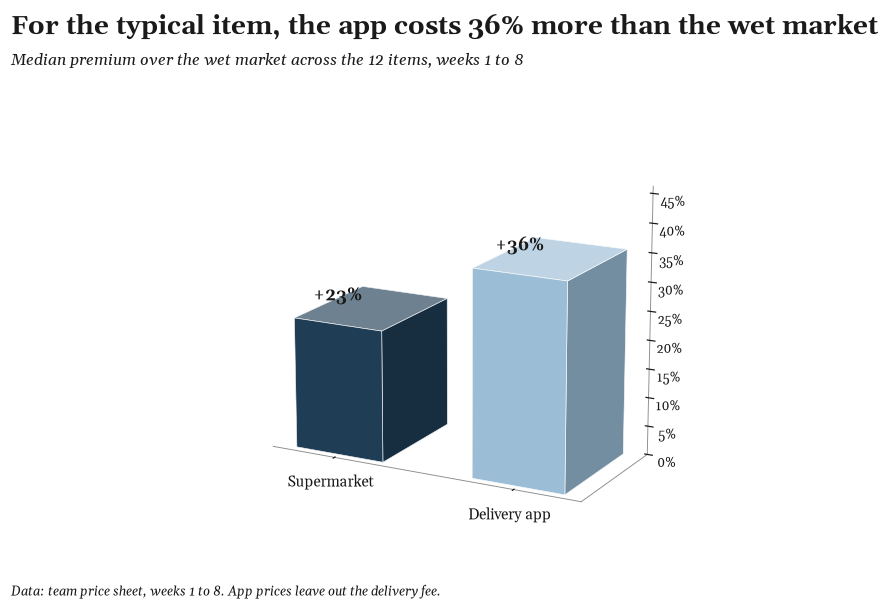

In [27]:
# M4.2 Median premium over the wet market across the 12 items, %
prem = (rel[["Siêu thị", "App"]] - 100).median()
fig = plt.figure(figsize=(8, 5.4))
ax = fig.add_subplot(projection="3d")
bars3d(ax, [0, 1], [0, 0], prem.values, [CHANNEL["Siêu thị"], CHANNEL["App"]], width=0.5, depth=0.5)
style3d(ax, elev=16, azim=-62, aspect=(2, 0.9, 1.6), zoom=1.0)
ax.set_xticks([0, 1], [CHANNEL_EN["Siêu thị"], CHANNEL_EN["App"]], fontsize=9.5)
ax.set_yticks([]); ax.set_zlim(0, prem.max() * 1.3); ax.zaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
for i, v in enumerate(prem.values):
    label3d(ax, i, -0.25, v, f"+{v:.0f}%", fontsize=11, fontweight="bold")
figure_title(fig, f"For the typical item, the app costs {prem['App']:.0f}% more than the wet market",
             f"Median premium over the wet market across the 12 items, {PERIOD}", y=0.97)
note(fig, f"Data: team price sheet, {PERIOD}. App prices leave out the delivery fee.", y=0.06)
save(fig, FIG / "m4_chart2_premium.png")
plt.show()

In [28]:
# M4.2 Check with matched pairs: the same item, district and week priced at the wet market and in the other channel
pairs = usable_prices.pivot_table(index=["item_code", "district", "week"], columns="channel", values="price_std")
for ch in ["Siêu thị", "App"]:
    pr = pairs[["Chợ", ch]].dropna()
    ratio = pr[ch] / pr["Chợ"]
    print(f"{CHANNEL_EN[ch]} against the wet market: median ratio {ratio.median():.2f} over {len(pr)} matched pairs; "
          f"dearer in {(ratio > 1).mean():.0%} of the pairs")

Supermarket against the wet market: median ratio 1.18 over 187 matched pairs; dearer in 89% of the pairs
Delivery app against the wet market: median ratio 1.34 over 180 matched pairs; dearer in 94% of the pairs


### M4.3 · Chart 3: basket cost per channel over the weeks
*Task:* track the cost of the same basket in each channel, week by week.
*Why this chart:* a line shows change over time, and three lines on one scale show whether the gap between channels stays the same. The brief names this idiom, so the chart stays flat.
*Choices:* the basket holds 1 kg of each item sold by weight and 10 eggs; each point is the mean of the two districts; a week enters only when all 12 items have a usable price in that channel; the app points say which app was used (G = Grab Mart, S = Shopee Mart); the value axis starts at zero so that the gap between lines reads in proportion.

In [29]:
# M4.3 Basket cost per channel and week (1 kg of each item sold by weight, 10 eggs), mean of the two districts
QTY_S = pd.Series(QTY)
wk_items = usable_prices.groupby(["week", "channel", "item_code"])["price_std"].mean().unstack("item_code")
complete = wk_items.notna().sum(axis=1) == len(QTY_S)
basket_wk = (wk_items[complete] * QTY_S).sum(axis=1).unstack("channel").reindex(index=WEEKS_DONE, columns=CHANNEL_ORDER)
gap_wk = basket_wk.div(basket_wk["Chợ"], axis=0) - 1
app_of_week = usable_prices[usable_prices["channel"] == "App"].groupby("week")["app_name"].first()
incomplete = [f"week {w}, {CHANNEL_EN[c]}" for (w, c) in wk_items[~complete].index]
missing_items = {f"week {w}, {CHANNEL_EN[c]}": list(wk_items.loc[(w, c)][wk_items.loc[(w, c)].isna()].index) for (w, c) in wk_items[~complete].index}
print("Incomplete baskets (an item has no usable price):", missing_items)
gmin, gmax = gap_wk["App"].min(), gap_wk["App"].max()
print(f"App over wet market: {gmin:.1%} to {gmax:.1%}; supermarket over wet market: {gap_wk['Siêu thị'].min():.1%} to {gap_wk['Siêu thị'].max():.1%}")
display((basket_wk / 1000).round(0).rename(columns=CHANNEL_EN))

Incomplete baskets (an item has no usable price): {'week 4, Delivery app': ['SP08'], 'week 4, Wet market': ['SP08'], 'week 6, Delivery app': ['SP10'], 'week 6, Wet market': ['SP10'], 'week 6, Supermarket': ['SP10']}
App over wet market: 22.2% to 29.3%; supermarket over wet market: 5.9% to 17.3%


channel,Wet market,Supermarket,Delivery app
week,,,
1,1072.0,1135.508286,1373.739643
2,1090.0,1201.7,1408.85
3,1002.333333,1155.033333,1242.811905
4,NaN,1079.4,NaN
5,1050.35,1231.582833,1343.745
6,NaN,NaN,NaN
7,1032.85,1194.6,1261.875
8,1054.75,1195.954545,1337.785714


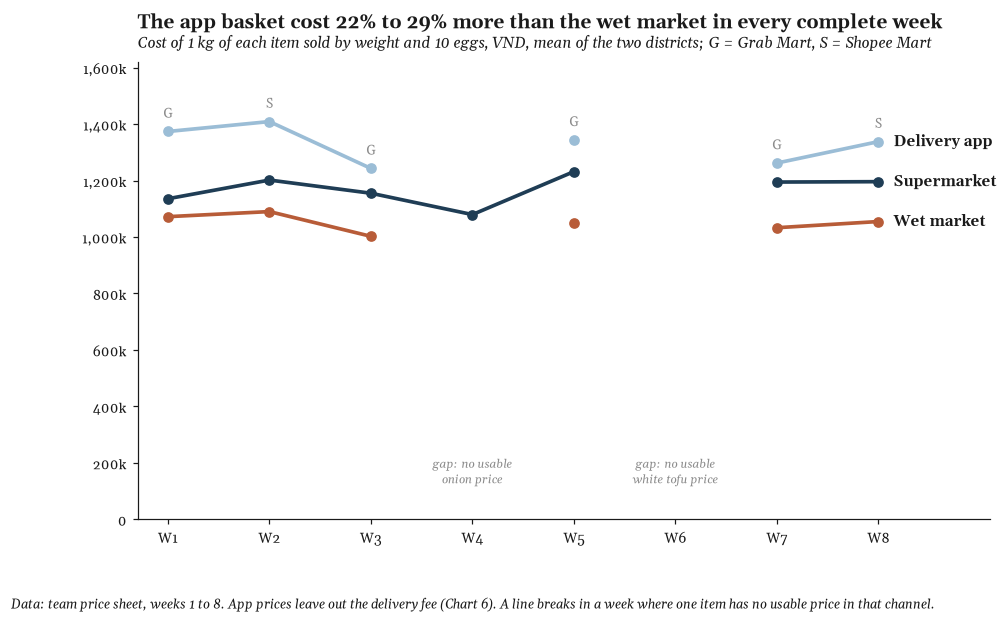

In [30]:
# M4.3 Chart 3: three lines on one scale, app points marked with the app of the week
fig, ax = plt.subplots(figsize=(10, 5.4))
for ch in CHANNEL_ORDER:
    s = basket_wk[ch]
    ax.plot(s.index, s.values, color=CHANNEL[ch], lw=2.4, marker="o", ms=6, zorder=3)
    last = s.dropna()
    ax.text(last.index[-1] + 0.15, last.iloc[-1], CHANNEL_EN[ch], va="center", fontsize=10, fontweight="bold")
for w, v in basket_wk["App"].dropna().items():
    ax.annotate("G" if "Grab" in app_of_week[w] else "S", (w, v), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=8.5, color=GREY)
gaps = {}                                              # one note per week: which item is missing
for (w, c) in wk_items[~complete].index:
    gaps.setdefault(w, set()).update(ITEM_EN[i].lower() for i in missing_items[f"week {w}, {CHANNEL_EN[c]}"])
for w, items in gaps.items():
    ax.text(w, basket_wk.max().max() * 0.08, "gap: no usable\n" + " or ".join(sorted(items)) + " price", ha="center", va="bottom",
            fontsize=8, style="italic", color=GREY)
ax.set_xticks(basket_wk.index, [f"W{w}" for w in basket_wk.index])
ax.set_xlim(basket_wk.index.min() - 0.3, basket_wk.index.max() + 1.1)
ax.set_ylim(0, basket_wk.max().max() * 1.15)
ax.yaxis.set_major_formatter(lambda v, _: fmt_vnd(v))
title(ax, f"The app basket cost {gmin:.0%} to {gmax:.0%} more than the wet market in every complete week",
      "Cost of 1 kg of each item sold by weight and 10 eggs, VND, mean of the two districts; G = Grab Mart, S = Shopee Mart")
note(fig, f"Data: team price sheet, {PERIOD}. App prices leave out the delivery fee (Chart 6). A line breaks in a week where one item has no usable price in that channel.", y=-0.02)
save(fig, FIG / "m4_chart3_basket_weeks.png")
plt.show()

### M4.4 · Chart 4: our basket index against the official CPI
*Task:* compare the price change that my group observed with the official CPI for food in Ho Chi Minh City.
*Why this chart:* two panels on one time axis let the reader compare the direction of both series without a dual axis, which the brief forbids. The brief names this idiom, so the chart stays flat.
*Choices:* the top panel is our basket index (week 1 = 100; the app is compared with the first week of the same app); the bottom panel is the NSO change against the previous month for the foodstuff group of Ho Chi Minh City; both panels share the calendar axis, so the reader sees that only October overlaps so far.

In [31]:
# M4.4 Basket index per channel (week 1 = 100, app against its own first week) and the NSO foodstuff CPI of HCMC
idx_wk = basket_wk.copy()
for ch in ["Chợ", "Siêu thị"]:
    idx_wk[ch] = basket_wk[ch] / basket_wk.loc[1, ch] * 100
idx_wk["App"] = [basket_wk.loc[w, "App"] / basket_wk.loc[1 if w % 2 else 2, "App"] * 100 for w in basket_wk.index]
mid_week = {w: WEEK1_START + pd.Timedelta(days=7 * (w - 1) + 3) for w in idx_wk.index}
cpi_m = (nso[(nso["area"] == "Ho Chi Minh City") & (nso["measure"] == "index_prev_month_100") & (nso["series"] == "foodstuff")]
         .set_index("year_month")["value"] - 100)
cpi_m.index = pd.to_datetime(cpi_m.index) + pd.Timedelta(days=14)
last_week = idx_wk.index.max()
chg_last = {ch: idx_wk[ch].dropna().iloc[-1] - 100 for ch in CHANNEL_ORDER}
cpi_oct = cpi_m[cpi_m.index.month == 10].iloc[0]
print("Index change to the last valid week:", {CHANNEL_EN[c]: round(v, 1) for c, v in chg_last.items()})
print(f"NSO foodstuff CPI of HCMC, October against September: {cpi_oct:+.2f}%")
display(idx_wk.round(1).rename(columns=CHANNEL_EN))

Index change to the last valid week: {'Wet market': -1.6, 'Supermarket': 5.3, 'Delivery app': np.float64(-5.0)}
NSO foodstuff CPI of HCMC, October against September: +0.62%


channel,Wet market,Supermarket,Delivery app
week,,,
1,100.0,100.0,100.0
2,101.679104,105.829259,100.0
3,93.501244,101.719498,90.5
4,NaN,95.058752,NaN
5,97.98041,108.460929,97.8
6,NaN,NaN,NaN
7,96.347948,105.203988,91.9
8,98.390858,105.323278,95.0


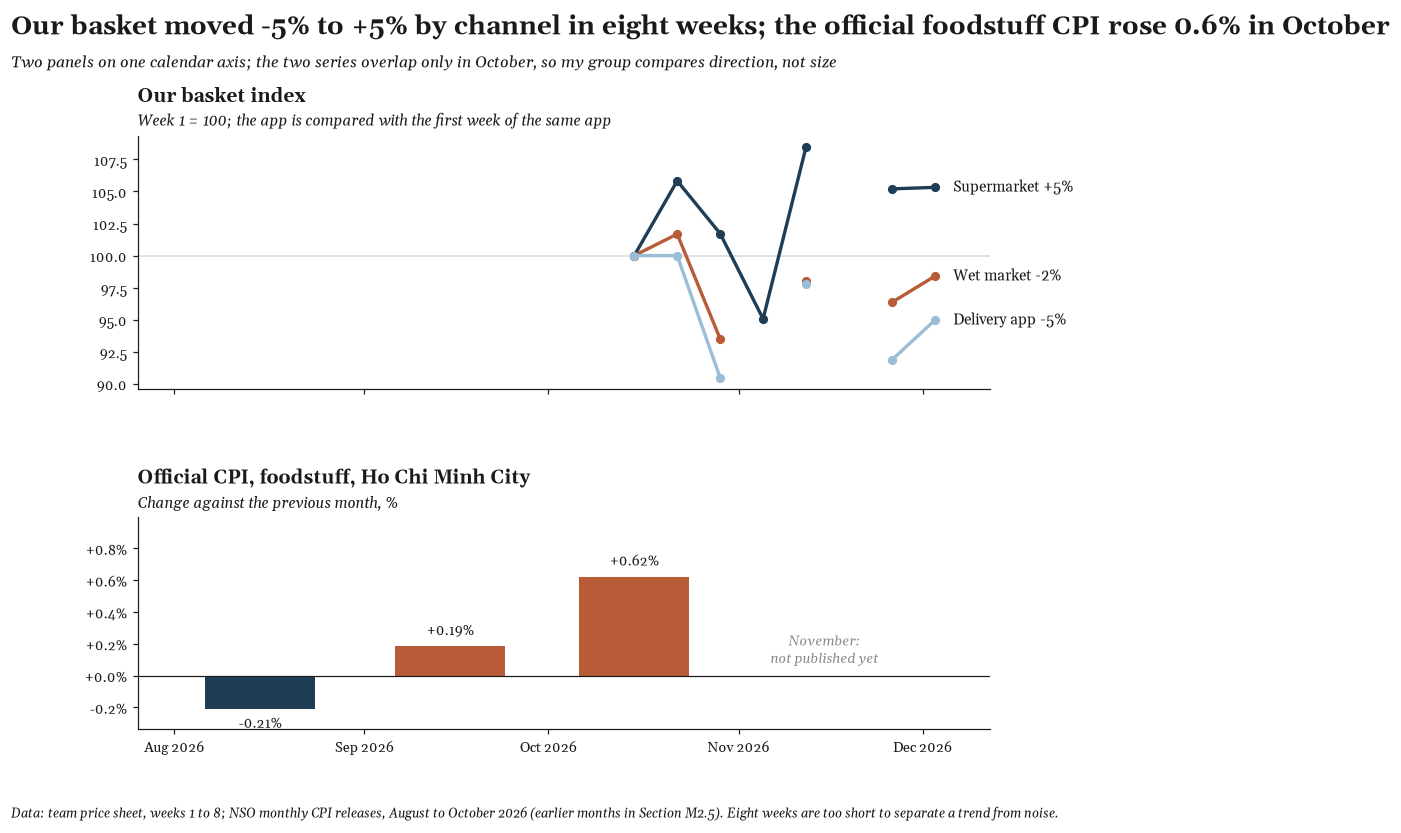

In [32]:
# M4.4 Chart 4: two panels on one calendar axis, no dual axis
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"hspace": 0.55, "height_ratios": [1.2, 1]})
a1.axhline(100, color=LIGHT, lw=1)
ends = {}
for ch in CHANNEL_ORDER:
    full = idx_wk[ch].reindex(WEEKS_DONE)                 # NaN breaks the line where a basket is incomplete
    a1.plot([mid_week[w] for w in full.index], full.values, color=CHANNEL[ch], lw=2.2, marker="o", ms=5)
    s = full.dropna()
    ends[ch] = s.iloc[-1]
ypos = dict(sorted(ends.items(), key=lambda kv: kv[1]))      # spread the end labels so that they never overlap
prev = None
for ch, v in ypos.items():
    y = v if prev is None else max(v, prev + 2.2)
    a1.text(mid_week[idx_wk[ch].dropna().index[-1]] + pd.Timedelta(days=3), y, f"{CHANNEL_EN[ch]} {v - 100:+.0f}%", va="center", fontsize=9.5)
    prev = y
title(a1, "Our basket index", "Week 1 = 100; the app is compared with the first week of the same app")
start = (min(mid_week.values()) - pd.DateOffset(months=2)).to_period("M").to_timestamp() - pd.Timedelta(days=6)   # two months of CPI before week 1
cpi_show = cpi_m[cpi_m.index > start]
colors = [HIGHLIGHT if v > 0 else CHANNEL["Siêu thị"] for v in cpi_show.values]
a2.bar(cpi_show.index, cpi_show.values, width=18, color=colors)
a2.axhline(0, color=INK, lw=0.8)
for d, v in cpi_show.items():
    a2.text(d, v + (0.04 if v >= 0 else -0.04), f"{v:+.2f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
nov = pd.Timestamp("2026-11-15")
a2.text(nov, 0.05, "November:\nnot published yet", ha="center", va="bottom", fontsize=9, style="italic", color=GREY)
a2.set_ylim(min(cpi_show.min() * 1.6, -0.3), max(cpi_show.max() * 1.6, 0.3))
a2.yaxis.set_major_locator(plt.MultipleLocator(0.2))
a2.yaxis.set_major_formatter(lambda v, _: f"{v:+.1f}%")
title(a2, "Official CPI, foodstuff, Ho Chi Minh City", "Change against the previous month, %")
a2.set_xlim(start, pd.Timestamp("2026-12-12"))
import matplotlib.dates as mdates
a2.xaxis.set_major_locator(mdates.MonthLocator()); a2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
lo, hi = min(chg_last.values()), max(chg_last.values())
figure_title(fig, f"Our basket moved {lo:+.0f}% to {hi:+.0f}% by channel in {NUM_WORD[len(WEEKS_DONE)]} weeks; the official foodstuff CPI rose {cpi_oct:.1f}% in October",
             "Two panels on one calendar axis; the two series overlap only in October, so my group compares direction, not size", y=1.0)
note(fig, f"Data: team price sheet, {PERIOD}; NSO monthly CPI releases, {cpi_show.index.min():%B} to {cpi_show.index.max():%B %Y} (earlier months in Section M2.5). Eight weeks are too short to separate a trend from noise.", y=0.01)
save(fig, FIG / "m4_chart4_index_vs_cpi.png")
plt.show()

### M4.5 · Chart 5: the two districts for each item
*Task:* compare the prices of Quận 10 and Quận 3 for each item.
*Why this chart:* a dumbbell puts the two districts of one item on one line, so the length of the bar is the gap. Districts never get a colour in the house style, so Quận 10 is a circle and Quận 3 a square.
*Choices:* only matched pairs enter (the same item, channel and week priced in both districts); each district is shown as an index of the item's mean (mean of both districts = 100); items run from the largest gap at the top to the smallest; the item with the largest gap is the one highlight.

In [33]:
# M4.5 Matched pairs of the two districts and the gap per item
pairs = usable_prices.pivot_table(index=["item_code", "channel", "week"], columns="district", values="price_std").dropna()
dist = pairs.groupby(level=0).mean()
dist["gap"] = dist["Quận 10"] / dist["Quận 3"] - 1
dist["pairs"] = pairs.groupby(level=0).size()
mean_both = dist[["Quận 10", "Quận 3"]].mean(axis=1)
d_idx = dist[["Quận 10", "Quận 3"]].div(mean_both, axis=0) * 100
order = dist["gap"].abs().sort_values().index
n_small = int((dist["gap"].abs() < 0.05).sum())
top_item = order[-1]
print(f"{n_small} of 12 items differ by less than 5% between the districts; largest gap: {ITEM_EN[top_item]} {dist.loc[top_item, 'gap']:+.1%} (Quận 10 against Quận 3)")
display(dist.assign(gap=(dist["gap"] * 100).round(1)).round(0).rename(index=ITEM_EN))

7 of 12 items differ by less than 5% between the districts; largest gap: Water spinach +10.4% (Quận 10 against Quận 3)


district,Quận 10,Quận 3,gap,pairs
item_code,,,,
Pork belly,175222.708333,172743.541667,1.4,24
Water spinach,34116.666667,30890.277778,10.4,24
Mackerel,281516.666667,280362.5,0.4,24
Tomato,33695.608696,35952.173913,-6.3,23
Beef,276038.913043,285782.391304,-3.4,23
Free range chicken,120145.833333,127875.0,-6.0,24
Watermelon,19389.565217,20444.927536,-5.2,23
Onion,29855.0,29955.0,-0.3,20
Đà Lạt potato,36643.478261,39507.826087,-7.3,23


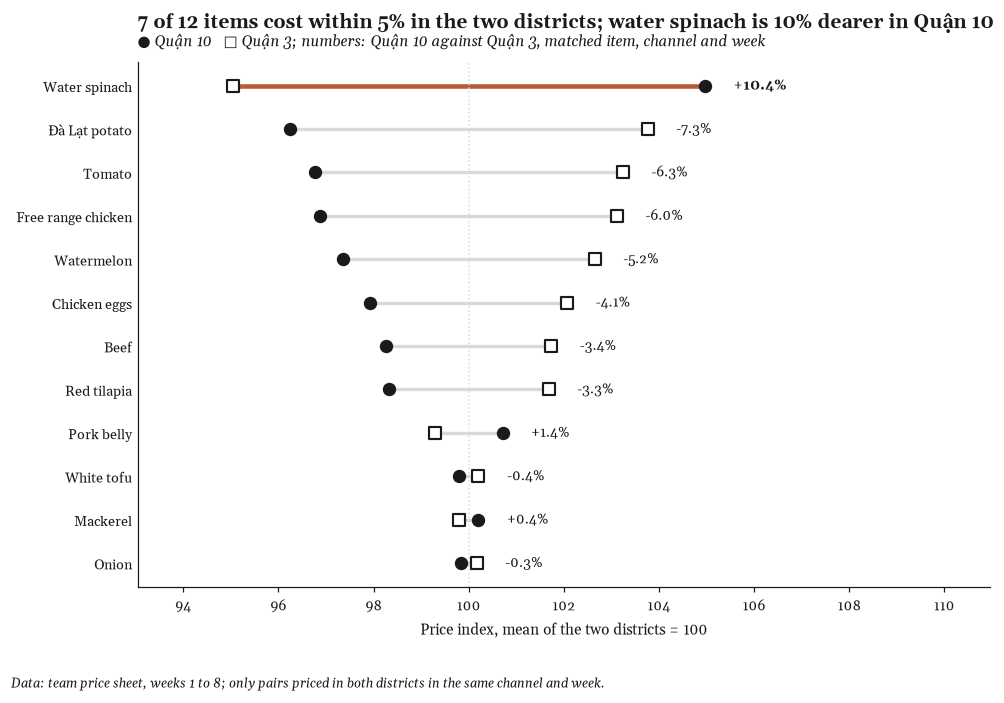

In [34]:
# M4.5 Chart 5: dumbbell, circle = Quận 10, square = Quận 3, the largest gap highlighted
fig, ax = plt.subplots(figsize=(10, 6.2))
for i, item in enumerate(order):
    x10, x3 = d_idx.loc[item, "Quận 10"], d_idx.loc[item, "Quận 3"]
    hl = item == top_item
    ax.plot([x10, x3], [i, i], color=HIGHLIGHT if hl else LIGHT, lw=3 if hl else 2.2, zorder=1, solid_capstyle="round")
    ax.scatter(x10, i, s=60, marker=DISTRICT_MARKER["Quận 10"], color=INK, zorder=3)
    ax.scatter(x3, i, s=60, marker=DISTRICT_MARKER["Quận 3"], facecolor=PAPER, edgecolor=INK, lw=1.4, zorder=3)
    ax.text(max(x10, x3) + 0.6, i, f"{dist.loc[item, 'gap']:+.1%}", va="center", fontsize=9,
            fontweight="bold" if hl else "normal")
ax.axvline(100, color=LIGHT, lw=1, ls=":")
ax.set_yticks(range(len(order)), [ITEM_EN[k] for k in order])
ax.set_xlim(d_idx.min().min() - 2, d_idx.max().max() + 6)
ax.set_xlabel("Price index, mean of the two districts = 100")
ax.tick_params(axis="y", length=0)
top_name = ITEM_EN[top_item].lower()
side = "cheaper" if dist.loc[top_item, "gap"] < 0 else "dearer"
title(ax, f"{n_small} of 12 items cost within 5% in the two districts; {top_name} is {abs(dist.loc[top_item, 'gap']):.0%} {side} in Quận 10",
      "● Quận 10   □ Quận 3; numbers: Quận 10 against Quận 3, matched item, channel and week")
note(fig, f"Data: team price sheet, {PERIOD}; only pairs priced in both districts in the same channel and week.", y=-0.02)
save(fig, FIG / "m4_chart5_districts.png")
plt.show()

### M4.6 · Chart 6: the basket with the delivery fee
*Task:* add the delivery fee to the app basket, so that the three channels compare at the price a student pays.
*Why this chart:* stacked 3D columns from zero show the basket and the fee as two parts of one total, the team style for a few magnitudes.
*Choices:* the basket is the mean of the complete weeks; the fee is one order per week (the median fee that the app showed in that week and district), averaged over the weeks; travel time to the market and the supermarket is not counted yet, because it comes from the student survey.

In [35]:
# M4.6 Mean basket per channel and the mean delivery fee of one app order
basket_mean = basket_wk.mean()
fee_order = (master[(master["channel"] == "App") & master["collected"]]
             .groupby(["week", "district"])["delivery_fee"].median().mean())
total = basket_mean.copy()
total["App"] = basket_mean["App"] + fee_order
gap_total = total["App"] / total["Chợ"] - 1
gap_basket = basket_mean["App"] / basket_mean["Chợ"] - 1
print(f"Mean basket: {basket_mean.round(-3).to_dict()}; one delivery fee: {fee_order:,.0f} VND")
print(f"App against wet market: {gap_basket:.1%} without the fee, {gap_total:.1%} with it")

Mean basket: {'Chợ': 1050000.0, 'Siêu thị': 1171000.0, 'App': 1328000.0}; one delivery fee: 23,297 VND
App against wet market: 26.4% without the fee, 28.7% with it


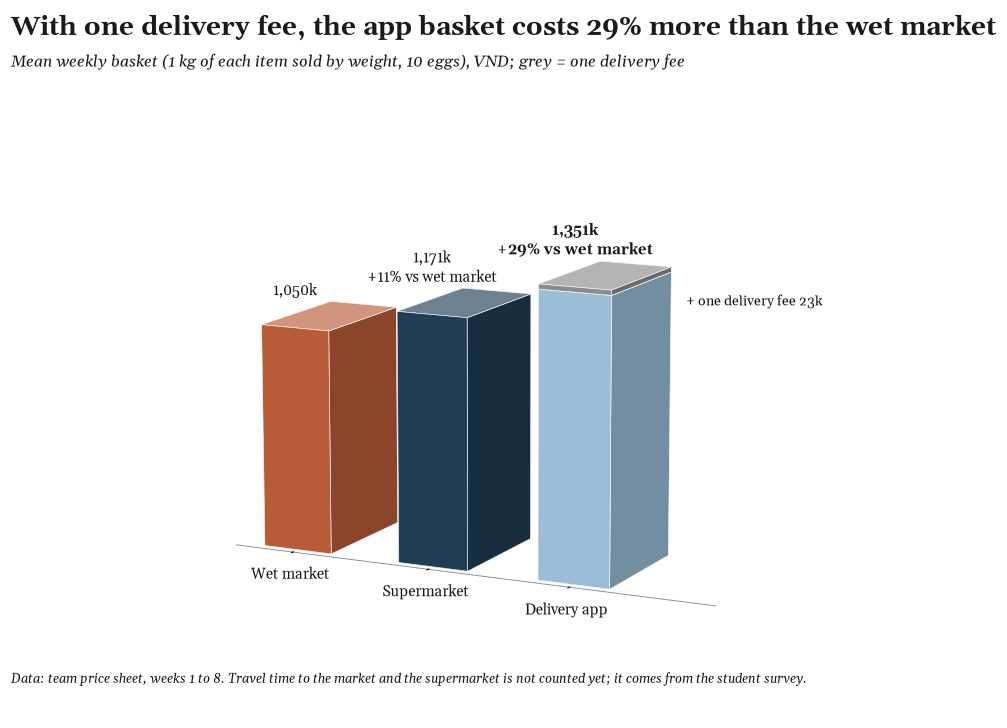

In [36]:
# M4.6 Chart 6: stacked 3D columns, basket at the base and the delivery fee on top of the app column
fig = plt.figure(figsize=(9, 6))
ax = fig.add_axes([0.0, -0.05, 1.0, 0.95], projection="3d")
XS = [0, 1.4, 2.8]
bars3d(ax, XS, [0] * 3, basket_mean.values, [CHANNEL[c] for c in CHANNEL_ORDER], width=0.7, depth=0.6)
bars3d(ax, [XS[2]], [0], [total["App"]], [GREY], width=0.7, depth=0.6, base=basket_mean["App"])
style3d(ax, elev=12, azim=-64, aspect=(3.2, 1, 2.0), zoom=1.0, zaxis=False, yaxis=False)
ax.set_zlim(0, total.max() * 1.12)
ax.set_xlim(-0.6, 4.2)
ax.set_xticks(XS, [CHANNEL_EN[c] for c in CHANNEL_ORDER], fontsize=9.5)
for x, c in zip(XS, CHANNEL_ORDER):
    txt = fmt_vnd(total[c]) + ("" if c == "Chợ" else f"\n{total[c] / total['Chợ'] - 1:+.0%} vs wet market")
    label3d(ax, x, -0.3, total[c], txt, dy=18, fontsize=10, fontweight="bold" if c == "App" else "normal")
label3d(ax, XS[2] + 0.62, -0.3, basket_mean["App"] + fee_order / 2, f"+ one delivery fee {fmt_vnd(fee_order)}", dx=30, dy=-4, ha="left", va="center", fontsize=9, color=INK)
figure_title(fig, f"With one delivery fee, the app basket costs {gap_total:.0%} more than the wet market",
             f"Mean weekly basket (1 kg of each item sold by weight, 10 eggs), VND; grey = one delivery fee", y=0.97)
note(fig, f"Data: team price sheet, {PERIOD}. Travel time to the market and the supermarket is not counted yet; it comes from the student survey.", y=0.02)
save(fig, FIG / "m4_chart6_basket_with_fee.png")
plt.show()

### M4.7 · Chart 7: the weekly basket of three student personas (waits for the survey)
*Task:* estimate the weekly basket of three student personas and the saving that each channel gives them.
*Status:* this chart needs the student survey of at least 60 students, which gives the personas, their baskets and their travel time. My group does not invent personas or quantities. When the survey file is in `data/raw/primary/`, this section draws a stacked bar per persona and channel: basket, delivery fee and the cost of travel time.

### M4.8 · AI audit (to do by a member, not by the notebook)
The brief asks a member to give one of our charts to an AI assistant with a short prompt and to audit the result. The audit must use a real run, so this page stays empty until a member does it.

1. Open ChatGPT or Claude in a new chat. Upload `data/clean/master_prices.csv`.
2. Type one short prompt and nothing else, for example: *"Draw a chart that compares the cost of a food basket in the three channels over the weeks."*
3. Save the prompt, the code and the chart exactly as the tool returned them in `evidence/ai_audit/`, with the date.
4. Below, list at least three problems, each with its evidence: the line of code or the number in the output, and what is wrong (wrong idiom, misleading scale, wrong aggregation, invented numbers, poor colour, a column misread). Errors that this dataset invites: adding prices per gram to prices per kg, adding the price of one egg as if it were a kilogram, averaging all rows instead of each item, keeping flagged or future rows, a dual axis.
5. Put Chart 3 above next to the AI chart as the corrected version.

| # | Problem in the AI output | Evidence | How Chart 3 fixes it |
|---|---|---|---|
| 1 | *(fill in)* | *(fill in)* | *(fill in)* |
| 2 | *(fill in)* | *(fill in)* | *(fill in)* |
| 3 | *(fill in)* | *(fill in)* | *(fill in)* |

---
# M5 · Dashboard and a second tool
**What the brief asks.** A one page dashboard in matplotlib with `subplot_mosaic` and the house style, saved as PDF and PNG (dpi 200 or more). The same dashboard, or at least two of its views, rebuilt in a second tool (Tableau Public, Looker Studio, Excel or Power BI). A comparison of 300 words: what was easier, what the second tool could not do, and which one my group would give to the client. For this project the dashboard is "This week's basket".

**What my group built.** The matplotlib dashboard is a function, `draw_dashboard(week)`, so the team redraws it every Sunday with one call. The second tool is Excel: the cell below writes `report/m5_dashboard_excel.xlsx` with native Excel charts and a district filter, which a member opens in Excel, checks and screenshots.

| Panel | Content | Idiom |
|---|---|---|
| A | Basket cost of the week per channel and the change since the last comparable week | Big numbers |
| B | Price of the 12 items in the three channels in that week (wet market = 100) | Dot plot |
| C | Basket cost per channel over the weeks | Line |
| D | Median premium over the wet market in that week | Bar |
| E | Official foodstuff CPI of Ho Chi Minh City | Bar |

The dashboard panels stay flat: a page with five small panels has no room for 3D views, and each panel repeats an idiom of M4.

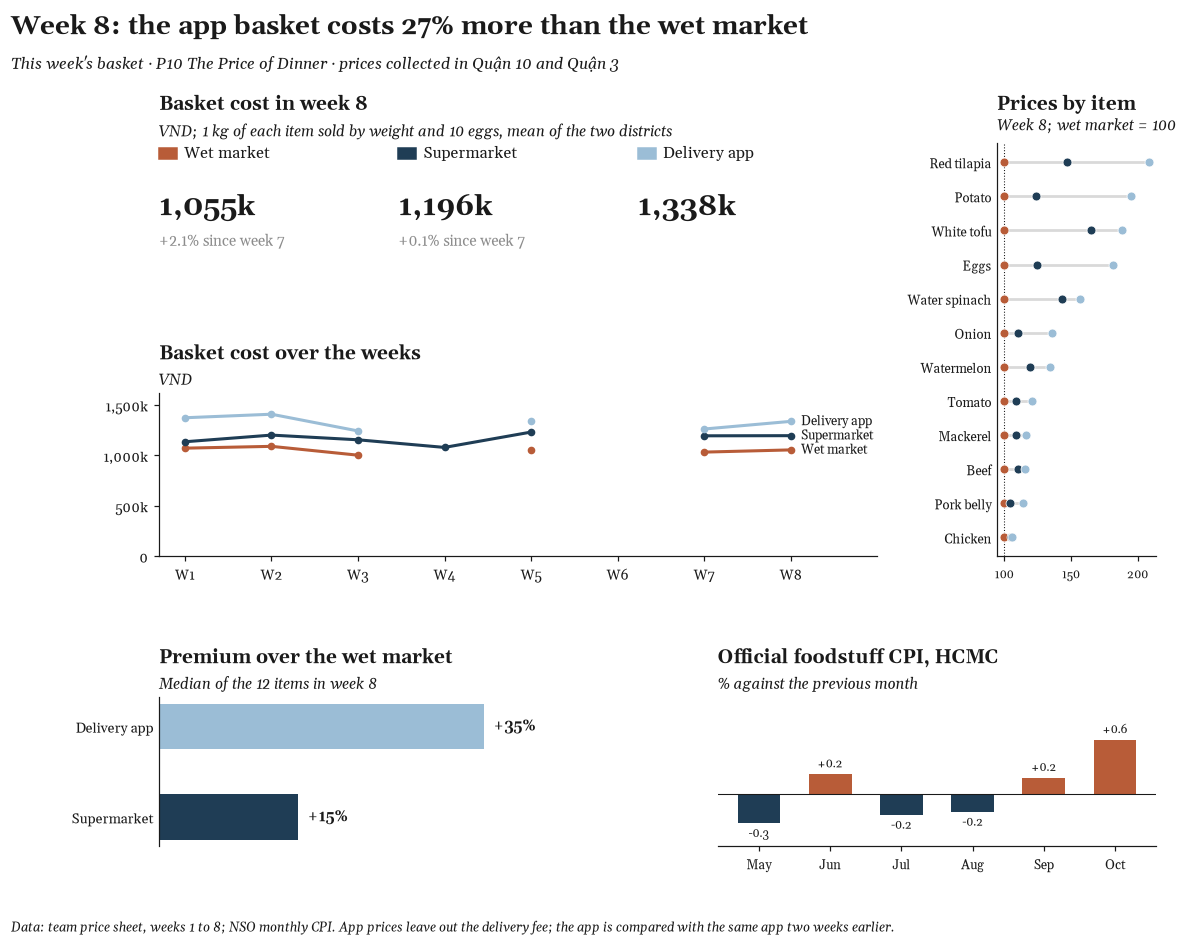

Dashboard drawn for week 8


In [37]:
# M5.1 Dashboard "This week's basket" on one A4 page with subplot_mosaic
def draw_dashboard(week):
    # Draw the dashboard for one week; the comparison week is the previous week (two weeks earlier for the app).
    bw = basket_wk.loc[:week]
    fig, axd = plt.subplot_mosaic("AAAB;CCCB;DDEE", figsize=(11.7, 8.3),
                                  gridspec_kw={"hspace": 1.0, "wspace": 0.75, "height_ratios": [0.8, 1.2, 1.1]})
    # A: big numbers
    ax = axd["A"]; ax.axis("off")
    for k, ch in enumerate(CHANNEL_ORDER):
        x0 = k / 3
        v = bw[ch].get(week, np.nan)
        prev_w = week - (2 if ch == "App" else 1)
        prev = bw[ch].get(prev_w, np.nan)
        ax.add_patch(plt.Rectangle((x0, 0.86), 0.025, 0.1, color=CHANNEL[ch], transform=ax.transAxes, clip_on=False))
        ax.text(x0 + 0.035, 0.91, CHANNEL_EN[ch], transform=ax.transAxes, fontsize=10.5, va="center")
        ax.text(x0, 0.42, fmt_vnd(v) if pd.notna(v) else "no complete basket", transform=ax.transAxes,
                fontsize=19 if pd.notna(v) else 12, fontweight="bold", va="center")
        if pd.notna(v) and pd.notna(prev):
            ax.text(x0, 0.06, f"{v / prev - 1:+.1%} since week {prev_w}", transform=ax.transAxes, fontsize=9.5, color=GREY)
    title(ax, f"Basket cost in week {week}", "VND; 1 kg of each item sold by weight and 10 eggs, mean of the two districts")
    # B: dot plot of the week, wet market = 100
    wi = wk_items.loc[week].T.reindex(columns=CHANNEL_ORDER)
    short = {**ITEM_EN, "SP06": "Chicken", "SP09": "Potato", "SP02": "Water spinach", "SP11": "Eggs"}
    rel_w = (wi.div(wi["Chợ"], axis=0) * 100).dropna().rename(index=short).sort_values("App")
    ax = axd["B"]
    for j, item in enumerate(rel_w.index):
        row = rel_w.loc[item]
        ax.plot([row.min(), row.max()], [j, j], color=LIGHT, lw=1.8, zorder=1)
        for ch in CHANNEL_ORDER:
            ax.scatter(row[ch], j, s=34, color=CHANNEL[ch], edgecolor="white", lw=0.5, zorder=3)
    ax.axvline(100, color=INK, lw=0.7, ls=":")
    ax.set_yticks(range(len(rel_w)), rel_w.index, fontsize=8.5); ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", labelsize=8)
    title(ax, "Prices by item", f"Week {week}; wet market = 100")
    # C: basket over the weeks
    ax = axd["C"]
    ends = {}
    for ch in CHANNEL_ORDER:
        s = bw[ch]
        ax.plot(s.index, s.values, color=CHANNEL[ch], lw=2, marker="o", ms=4)
        ls = s.dropna()
        ends[ch] = (ls.index[-1], ls.iloc[-1])
    gap, prev = bw.max().max() * 0.09, None                   # spread the end labels so that they never touch
    for ch, (w_, v) in sorted(ends.items(), key=lambda kv: kv[1][1]):
        y = v if prev is None else max(v, prev + gap)
        ax.text(w_ + 0.12, y, CHANNEL_EN[ch], va="center", fontsize=8.5)
        prev = y
    ax.set_xticks(bw.index, [f"W{w}" for w in bw.index]); ax.set_ylim(0, bw.max().max() * 1.15)
    ax.set_xlim(bw.index.min() - 0.3, bw.index.max() + 1.0)
    ax.yaxis.set_major_formatter(lambda v, _: fmt_vnd(v))
    title(ax, "Basket cost over the weeks", "VND")
    # D: premium of the week
    ax = axd["D"]
    pw = (rel_w[["Siêu thị", "App"]] - 100).median()
    ax.barh([CHANNEL_EN[c] for c in pw.index], pw.values, color=[CHANNEL[c] for c in pw.index], height=0.5)
    for j, v in enumerate(pw.values):
        ax.text(v + 1, j, f"+{v:.0f}%", va="center", fontsize=9.5, fontweight="bold")
    ax.set_xlim(0, max(pw.max() * 1.35, 10)); ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0)
    title(ax, "Premium over the wet market", f"Median of the 12 items in week {week}")
    # E: official CPI
    ax = axd["E"]
    cm = cpi_m.copy()
    ax.bar(cm.index.strftime("%b"), cm.values, color=[HIGHLIGHT if v > 0 else CHANNEL["Siêu thị"] for v in cm.values], width=0.6)
    ax.axhline(0, color=INK, lw=0.7)
    for j, v in enumerate(cm.values):
        ax.text(j, v + (0.03 if v >= 0 else -0.03), f"{v:+.1f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
    ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.tick_params(axis="x", labelsize=8.5)
    ax.set_ylim(min(cm.min() * 1.8, -0.3), max(cm.max() * 1.8, 0.3))
    title(ax, "Official foodstuff CPI, HCMC", "% against the previous month")
    g = bw.loc[week, "App"] / bw.loc[week, "Chợ"] - 1 if pd.notna(bw.loc[week, "Chợ"]) else np.nan
    head = (f"Week {week}: the app basket costs {g:.0%} more than the wet market" if pd.notna(g)
            else f"Week {week}: no complete wet market basket this week")
    figure_title(fig, head, f"This week's basket · P10 The Price of Dinner · prices collected in Quận 10 and Quận 3", y=0.99)
    note(fig, f"Data: team price sheet, {PERIOD}; NSO monthly CPI. App prices leave out the delivery fee; the app is compared with the same app two weeks earlier.", y=0.03)
    return fig

DASH_WEEK = int(basket_wk.dropna().index.max())      # the latest week with a complete basket in every channel
fig = draw_dashboard(DASH_WEEK)
save(fig, FIG / "m5_dashboard_v1.png", pdf=True)
plt.show()
print("Dashboard drawn for week", DASH_WEEK)

In [38]:
# M5.2 The second tool: an Excel workbook with native Excel charts and a district filter
from openpyxl import Workbook
from openpyxl.chart import LineChart, BarChart, Reference
from openpyxl.worksheet.datavalidation import DataValidation
from openpyxl.styles import Font, PatternFill

# Basket per week, channel and district (complete baskets only); "Both districts" = mean of the two
rows = []
for dname, part in [("Quận 10", usable_prices[usable_prices["district"] == "Quận 10"]),
                    ("Quận 3", usable_prices[usable_prices["district"] == "Quận 3"]),
                    ("Both districts", usable_prices)]:
    wi_d = part.groupby(["week", "channel", "item_code"])["price_std"].mean().unstack("item_code")
    ok = wi_d.notna().sum(axis=1) == len(QTY_S)
    bd = (wi_d[ok] * QTY_S).sum(axis=1)
    for (w, ch), v in bd.items():
        rows.append({"week": int(w), "channel": CHANNEL_EN[ch], "district": dname, "basket_vnd": round(float(v))})
excel_data = pd.DataFrame(rows)

wb = Workbook()
ws = wb.active; ws.title = "Dashboard"
wd = wb.create_sheet("Data")
wd.append(["week", "channel", "district", "basket_vnd"])
for r in excel_data.itertuples(index=False):
    wd.append(list(r))
n = len(excel_data) + 1

ws["A1"] = "This week's basket"; ws["A1"].font = Font(bold=True, size=16)
ws["A2"] = "District"; ws["B2"] = "Both districts"
ws["B2"].fill = PatternFill("solid", fgColor="F2F5F8"); ws["C2"] = "← choose Quận 10, Quận 3 or Both districts"
dv = DataValidation(type="list", formula1='"Both districts,Quận 10,Quận 3"', allow_blank=False)
ws.add_data_validation(dv); dv.add("B2")
names = [CHANNEL_EN[c] for c in CHANNEL_ORDER]
ws.append([])
ws["A4"] = "Week"
for j, nm in enumerate(names):
    ws.cell(row=4, column=2 + j, value=nm)
weeks_x = sorted(excel_data["week"].unique())
for i_w, w in enumerate(weeks_x):
    r = 5 + i_w
    ws.cell(row=r, column=1, value=f"W{w}")
    for j in range(3):
        col = chr(ord("B") + j)
        ws.cell(row=r, column=2 + j,
                value=f'=IFERROR(AVERAGEIFS(Data!$D$2:$D${n},Data!$A$2:$A${n},{w},Data!$B$2:$B${n},{col}$4,Data!$C$2:$C${n},$B$2),NA())')
last = 4 + len(weeks_x)
sr = last + 2
ws.cell(row=sr, column=1, value="Mean basket")
for j in range(3):
    col = chr(ord("B") + j)
    ws.cell(row=sr - 1, column=2 + j, value=names[j])
    ws.cell(row=sr, column=2 + j, value=f'=AVERAGEIFS(Data!$D$2:$D${n},Data!$B$2:$B${n},{col}${sr - 1},Data!$C$2:$C${n},$B$2)')

HEX = {nm: CHANNEL[c].lstrip("#") for nm, c in zip(names, CHANNEL_ORDER)}
lc = LineChart(); lc.title = "Basket cost per channel over the weeks"; lc.y_axis.title = "VND"; lc.height, lc.width = 8, 16
lc.add_data(Reference(ws, min_col=2, max_col=4, min_row=4, max_row=last), titles_from_data=True)
lc.set_categories(Reference(ws, min_col=1, min_row=5, max_row=last))
for s, nm in zip(lc.series, names):
    s.graphicalProperties.line.solidFill = HEX[nm]; s.graphicalProperties.line.width = 28000; s.smooth = False
ws.add_chart(lc, "F2")
bc = BarChart(); bc.type = "bar"; bc.title = "Mean basket per channel"; bc.height, bc.width = 7, 16; bc.legend = None
bc.add_data(Reference(ws, min_col=2, max_col=4, min_row=sr, max_row=sr), from_rows=True)
bc.set_categories(Reference(ws, min_col=2, max_col=4, min_row=sr - 1, max_row=sr - 1))
from openpyxl.chart.series import DataPoint
for j, nm in enumerate(names):
    pt = DataPoint(idx=j); pt.graphicalProperties.solidFill = HEX[nm]; bc.series[0].dPt.append(pt)
ws.add_chart(bc, "F19")
ws.column_dimensions["A"].width = 14
for c in "BCD":
    ws.column_dimensions[c].width = 15
wb.calculation.fullCalcOnLoad = True
XLSX = ROOT / "report" / "m5_dashboard_excel.xlsx"
wb.save(XLSX)
print("Saved", XLSX.relative_to(ROOT), "| rows in Data:", len(excel_data))
display(excel_data.pivot_table(index="week", columns=["district", "channel"], values="basket_vnd").round(-3).head())

Saved report\m5_dashboard_excel.xlsx | rows in Data: 51


district Both districts                             Quận 10              \
channel    Delivery app Supermarket Wet market Delivery app Supermarket   
week                                                                      
1             1374000.0   1136000.0  1072000.0          NaN   1157000.0   
2             1409000.0   1202000.0  1090000.0    1446000.0   1212000.0   
3             1243000.0   1155000.0  1002000.0          NaN   1136000.0   
4                   NaN   1079000.0        NaN          NaN   1076000.0   
5             1344000.0   1232000.0  1050000.0    1324000.0   1233000.0   

district                  Quận 3                         
channel  Wet market Delivery app Supermarket Wet market  
week                                                     
1         1024000.0          NaN   1115000.0  1120000.0  
2         1084000.0    1372000.0   1191000.0  1096000.0  
3          967000.0          NaN   1174000.0  1038000.0  
4               NaN          NaN   1082000.0        NaN  
5         1037000.0    1363000.0   1230000.0  1064000.0

**Comparison of the two tools (300 words, draft).** *The M5 lead rewrites this draft in their own words after opening the Excel file, because the brief does not allow text written by AI as the team's own.*

> *(Draft.)* My group built the dashboard twice. In matplotlib, the whole page is one function, `draw_dashboard(week)`, so a new week costs one line of code, and every colour, font and title follows `house_style.py`. Matplotlib also allows the idioms that M4 needs, such as the dot plot and the two panel CPI chart. The cost is time: the first version took the longest of all tasks so far, and the page has no interaction; a reader cannot filter a district or hover over a value.
>
> In Excel, my group rebuilt two views: the basket line and the mean basket per channel. A district filter in one cell changes both charts at once, and a client can open the file without Python. Excel made some things hard or impossible. It has no dot plot, so the item view could not be rebuilt. Its charts keep default fonts and spacing unless every element is set by hand, and the title of an Excel chart cannot state a finding that updates with the filter. A formula error also shows only as an empty point, so a missing week is easy to miss.
>
> *(fill in: how long each tool took, what surprised the team, which tool my group would hand to Consumer Lab and why.)*

---
# M6 · Hidden structure: PCA and clustering
**What the brief asks.** Define the items and the features, standardise them, run PCA (scree plot, biplot with the loadings explained), k means (elbow and silhouette, two random seeds to check stability) and hierarchical clustering (dendrogram, with the choice of linkage explained). Name and profile the clusters with charts, and write what the clusters do not mean. For this project the items are the 12 foods and the features are the price levels and the weekly changes per channel. The brief calls this part `03_structure.ipynb` and asks for one page of segment profiles.

**Question of this module.** Which foods behave alike across the three channels? A student can use the answer as a rule of thumb: for one group of foods the channel matters a lot, for another it hardly matters.

| Step | Section | Output |
|---|---|---|
| Items and features: 12 foods × 6 features | M6.1 | `data/clean/m6_features.csv` |
| PCA: scree plot and biplot | M6.2 | `m6_pca.png` |
| K means: elbow, silhouette, two seeds, and the groups when one week, one food or one district is left out | M6.3 | `m6_kmeans_choice.png` |
| Hierarchical clustering: Ward and average linkage | M6.4 | `m6_dendrograms.png`, `data/clean/m6_leaf_order.csv` |
| Cluster names and profiles | M6.5 | `m6_segment_profiles.png`, `data/clean/m6_clusters.csv` |
| What the clusters do not mean | M6.6 | text |

All charts of this module stay flat: a scree plot, a biplot and a dendrogram are idioms of their own, and the house style keeps the 3D columns for comparisons of a few magnitudes.

### M6.1 · Items and features
*Items:* the 12 foods. *Features:* the two measures that the brief names, for each of the three channels, six in total.

| Feature | Meaning | How my group computes it |
|---|---|---|
| Price level · channel | How dear the channel is for this food, compared with the food's own mean | log of (mean price in the channel ÷ mean of the three channel means); 0 = the food's mean |
| Weekly change · channel | How fast the price moved from week to week | mean of the week on week % change; the app compares weeks of the same app (two weeks apart) and converts the change to one week |

Every price is the mean of the two districts in that week, and only usable prices enter (Section M2.3). Prices differ by a factor of one hundred between foods (an egg against a kilogram of beef), so the features use relative prices and changes, never the price itself. Without this, PCA would only separate dear foods from cheap foods. The table below shows the price level as a real percentage (for example, −30% means the channel is 30% below the food's mean over the three channels).

The three price levels of one food add up to almost zero, because each is measured against the same mean. One of them therefore carries almost no new information, and the last component of the PCA explains close to 0% (Section M6.2). My group keeps all three, because each reads as a plain statement about one channel.

My group also computed a third measure, the volatility of the weekly changes. Section M6.3 shows that adding it weakens the clusters, because each food has only four to seven weekly changes per channel, so the volatility is mostly noise. The main analysis therefore uses the six features of the brief.

In [39]:
# M6.1 Feature matrix: 12 foods × 6 features (price level and weekly change in each channel)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

SHORT_CH = {"Chợ": "market", "Siêu thị": "super", "App": "app"}
KIND = {"level": "Price level", "change": "Weekly change", "vol": "Volatility"}
FEAT_LABEL = {f"{k}_{SHORT_CH[c]}": f"{KIND[k]} · {CHANNEL_EN[c]}" for k in KIND for c in CHANNEL_ORDER}
FEAT_CH = {f"{k}_{SHORT_CH[c]}": c for k in KIND for c in CHANNEL_ORDER}
FEAT_PHRASE = {f"{k}_{SHORT_CH[c]}": f"{CHANNEL_EN[c].lower()} {KIND[k].lower()}" for k in KIND for c in CHANNEL_ORDER}

def weekly_changes(row, lag):
    # % change against the week `lag` weeks earlier, converted to one week
    vals = row.dropna()
    out = [(vals[w] / vals[w - lag]) ** (1 / lag) - 1 for w in vals.index if (w - lag) in vals.index]
    return pd.Series(out, dtype=float)

def make_features(prices):
    # price level, weekly change and volatility per food and channel, from the usable prices given (mean of the districts)
    icw = prices.groupby(["item_code", "channel", "week"])["price_std"].mean().unstack("week").astype(float)
    level_raw = icw.mean(axis=1).unstack("channel")[CHANNEL_ORDER]
    level = np.log(level_raw.div(level_raw.mean(axis=1), axis=0))
    chg, vol, n = {}, {}, {}
    for (item, ch), row in icw.iterrows():
        s = weekly_changes(row, 2 if ch == "App" else 1)
        chg[(item, ch)], vol[(item, ch)], n[(item, ch)] = s.mean(), s.std(ddof=1), len(s)
    out = pd.concat({"level": level, "change": pd.Series(chg).unstack()[CHANNEL_ORDER],
                     "vol": pd.Series(vol).unstack()[CHANNEL_ORDER]}, axis=1)
    out.columns = [f"{k}_{SHORT_CH[c]}" for k, c in out.columns]
    return out, n

feat_all, n_chg = make_features(usable_prices)
feat = feat_all.filter(regex="^(level|change)_")
assert not feat.isna().any().any(), "a feature is missing; check the weeks of that food and channel"
feat_all.round(4).rename(index=ITEM_EN).to_csv(CLEAN / "m6_features.csv")
Z = StandardScaler().fit_transform(feat)
LEVELS = [c for c in feat.columns if c.startswith("level")]

def as_pct(df):
    # price levels as a real % against the food's mean, weekly changes as % per week
    out = df.copy()
    out[[c for c in LEVELS if c in out]] = np.expm1(out[[c for c in LEVELS if c in out]])
    return out * 100

print(f"Weekly changes per food and channel: {min(n_chg.values())} to {max(n_chg.values())}")
print("Sum of the three price levels per food (log):", feat[LEVELS].sum(axis=1).round(3).min(), "to", feat[LEVELS].sum(axis=1).round(3).max())
print("Price level: % against the food's mean over the three channels. Weekly change: % per week.")
display(as_pct(feat).round(1).rename(index=ITEM_EN, columns=FEAT_LABEL))

Weekly changes per food and channel: 4 to 7
Sum of the three price levels per food (log): -0.076 to -0.004
Price level: % against the food's mean over the three channels. Weekly change: % per week.


,Price level · Wet market,Price level · Supermarket,Price level · Delivery app,Weekly change · Wet market,Weekly change · Supermarket,Weekly change · Delivery app
Pork belly,-6.3,0.2,6.0,1.5,1.9,2.4
Water spinach,-27.2,0.5,26.7,2.9,3.6,1.7
Mackerel,-12.0,0.1,11.9,0.7,3.8,0.1
Tomato,-16.9,5.3,11.6,9.6,3.6,-4.6
Beef,-6.9,-0.8,7.7,1.4,2.3,-0.6
Free range chicken,-4.2,-2.8,7.0,-2.0,3.1,-1.9
Watermelon,-23.2,-1.0,24.1,5.9,-0.7,-1.4
Onion,-26.1,3.8,22.3,-12.7,-0.2,-4.2
Đà Lạt potato,-11.6,0.7,10.9,1.3,2.3,6.6
White tofu,-28.0,3.8,24.2,0.8,-0.8,5.4


### M6.2 · PCA
*Task:* find the few directions along which the foods differ most.
*Why this chart:* the scree plot shows how much each component explains; the biplot places each food by its first two scores and draws each feature as an arrow (its loading), so the reader sees which features pull foods apart.
*Choices:* loadings are scaled as correlations between a feature and a component; arrows take the colour of their channel (house style), and their label names the measure; foods are grey points with their names.

In [40]:
# M6.2 PCA on the six standardised features: explained variance, loadings and scores
pca = PCA().fit(Z)
evr = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i + 1}" for i in range(len(pca.explained_variance_ratio_))])
n_items = len(feat)
eig = pca.explained_variance_ * (n_items - 1) / n_items     # eigenvalues of the correlation matrix (StandardScaler divides by n)
loadings = pd.DataFrame(pca.components_[:2].T * np.sqrt(eig[:2]), index=feat.columns, columns=["PC1", "PC2"])   # = correlation of feature and component
scores = pd.DataFrame(pca.transform(Z)[:, :2], index=feat.index, columns=["PC1", "PC2"])
pc1_pos, pc1_neg = loadings["PC1"].idxmax(), loadings["PC1"].idxmin()
pc2_pos, pc2_neg = loadings["PC2"].idxmax(), loadings["PC2"].idxmin()
print("Explained variance (%):", (evr * 100).round(1).to_dict())
print(f"PC1: {FEAT_LABEL[pc1_pos]} ({loadings.loc[pc1_pos, 'PC1']:+.2f}) against {FEAT_LABEL[pc1_neg]} ({loadings.loc[pc1_neg, 'PC1']:+.2f})")
print(f"PC2: {FEAT_LABEL[pc2_pos]} ({loadings.loc[pc2_pos, 'PC2']:+.2f}) against {FEAT_LABEL[pc2_neg]} ({loadings.loc[pc2_neg, 'PC2']:+.2f})")
assert loadings.abs().max().max() <= 1 + 1e-9
display(loadings.round(2).rename(index=FEAT_LABEL))

Explained variance (%): {'PC1': 37.7, 'PC2': 24.1, 'PC3': 16.9, 'PC4': 13.7, 'PC5': 7.7, 'PC6': 0.0}
PC1: Price level · Wet market (+0.95) against Price level · Delivery app (-0.86)
PC2: Weekly change · Supermarket (+0.74) against Weekly change · Delivery app (-0.61)


,PC1,PC2
Price level · Wet market,0.95,-0.25
Price level · Supermarket,-0.58,-0.39
Price level · Delivery app,-0.86,0.40
Weekly change · Wet market,0.23,0.39
Weekly change · Supermarket,0.45,0.74
Weekly change · Delivery app,0.12,-0.61


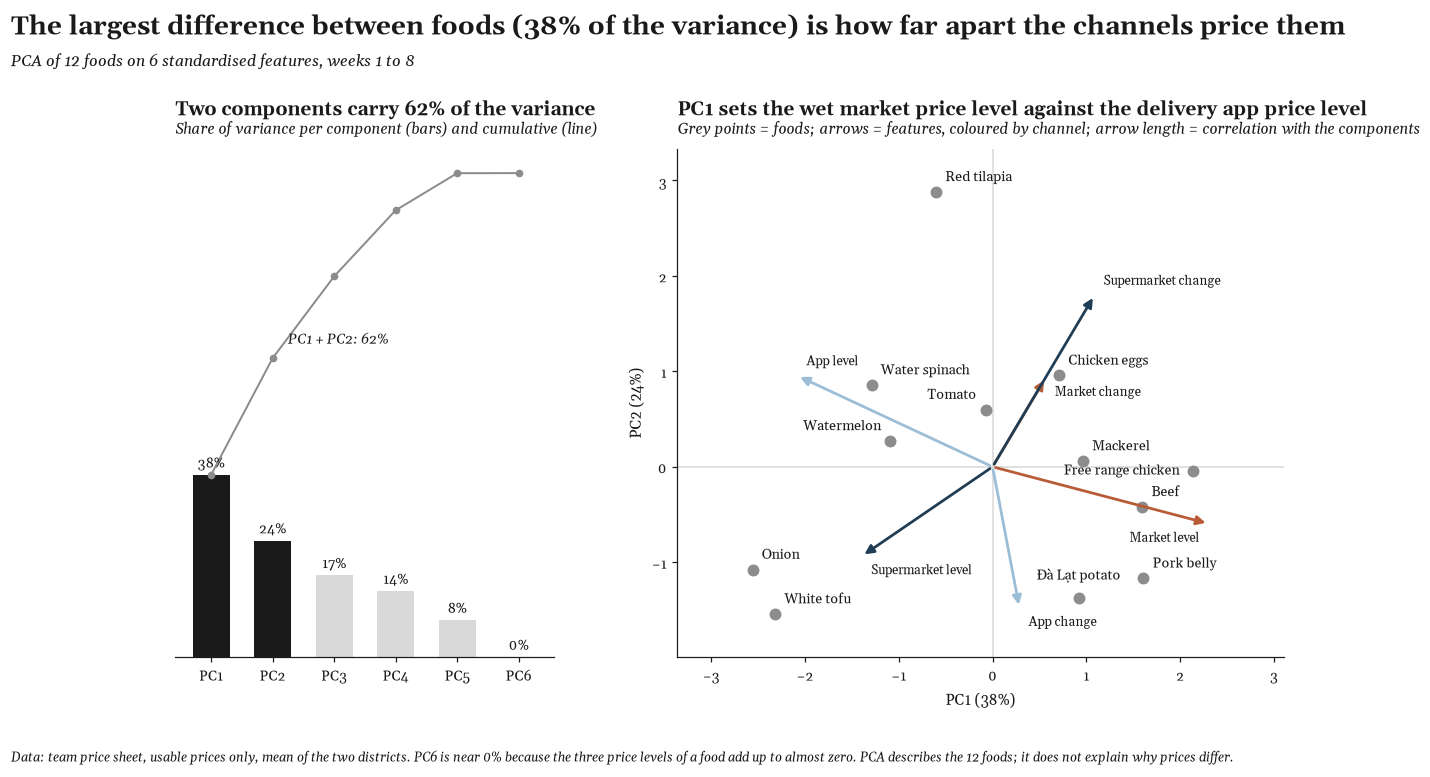

In [41]:
# M6.2 Scree plot and biplot
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1.6], "wspace": 0.25})
x = np.arange(1, len(evr) + 1)
a1.bar(x, evr.values * 100, color=[INK, INK] + [LIGHT] * (len(evr) - 2), width=0.6)
a1.plot(x, evr.cumsum().values * 100, color=GREY, marker="o", ms=4, lw=1.3)
for xi, v, cv in zip(x, evr.values * 100, evr.cumsum().values * 100):
    a1.text(xi, v + 1.5, f"{v:.0f}%", ha="center", fontsize=9)
a1.text(x[1] + 0.25, evr.cumsum().iloc[1] * 100 + 3, f"PC1 + PC2: {evr.iloc[:2].sum():.0%}", fontsize=9, style="italic")
a1.set_xticks(x, [f"PC{i}" for i in x]); a1.set_ylim(0, 105); a1.set_yticks([])
a1.spines["left"].set_visible(False)
title(a1, f"Two components carry {evr.iloc[:2].sum():.0%} of the variance", "Share of variance per component (bars) and cumulative (line)")

a2.axhline(0, color=LIGHT, lw=1); a2.axvline(0, color=LIGHT, lw=1)
def place_labels(ax, xy, names, avoid=(), lines=(), fontsize=9, obstacles=()):
    # write each point label at the first of eight spots that touches no other label, no point, no arrow and stays inside the panel
    ax.figure.canvas.draw()
    r = ax.figure.canvas.get_renderer()
    taken = [t.get_window_extent(r) for t in avoid]
    to_px = ax.transData.transform
    dots = [to_px(p) for p in list(xy) + list(obstacles)]
    segs = [to_px((x0 + s * (x1 - x0), y0 + s * (y1 - y0))) for x0, y0, x1, y1 in lines for s in np.linspace(0, 1, 40)]
    box = ax.get_window_extent(r)
    spots = [(6, 4, "left", "bottom"), (6, -4, "left", "top"), (-6, 4, "right", "bottom"), (-6, -4, "right", "top"),
             (0, 9, "center", "bottom"), (0, -9, "center", "top"), (9, 0, "left", "center"), (-9, 0, "right", "center")]
    placed = []
    for (x, y), name in zip(xy, names):
        best = None
        for dx, dy, ha, va in spots:
            t = ax.annotate(name, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va, fontsize=fontsize, color=INK)
            bb = t.get_window_extent(r).expanded(1.04, 1.12)
            cost = (10 * sum(bb.overlaps(o) for o in taken) + sum(bb.contains(*p) for p in dots) + sum(bb.contains(*p) for p in segs)
                    + 5 * (bb.x0 < box.x0 or bb.x1 > box.x1 or bb.y0 < box.y0 or bb.y1 > box.y1))
            if best is None or cost < best[0]:
                if best is not None:
                    best[1].remove()
                best = (cost, t)
            else:
                t.remove()
            if cost == 0:
                break
        taken.append(best[1].get_window_extent(r))
        placed.append(best[1])
    return placed

scale = np.abs(scores.values).max() / np.abs(loadings.values).max() * 0.8
tips = loadings * scale
a2.scatter(scores["PC1"], scores["PC2"], s=46, color=GREY, zorder=3)
for f_, (t1, t2) in tips.iterrows():
    a2.annotate("", xy=(t1, t2), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=CHANNEL[FEAT_CH[f_]], lw=1.8, mutation_scale=12))
arrow_names = [{"Chợ": "Market", "Siêu thị": "Supermarket", "App": "App"}[FEAT_CH[f_]] + " " + f_.split("_")[0] for f_ in tips.index]
xs = np.r_[scores["PC1"], tips["PC1"]]; ys = np.r_[scores["PC2"], tips["PC2"]]
a2.set_xlim(xs.min() - 0.8, xs.max() + 0.8); a2.set_ylim(ys.min() - 0.45, ys.max() + 0.45)
arrows = [(0, 0, t1, t2) for t1, t2 in tips.values]
arrow_text = place_labels(a2, tips.values, arrow_names, lines=arrows, fontsize=8.5, obstacles=scores[["PC1", "PC2"]].values)
place_labels(a2, scores[["PC1", "PC2"]].values, [ITEM_EN[c] for c in scores.index], avoid=arrow_text, lines=arrows)
a2.set_xlabel(f"PC1 ({evr.iloc[0]:.0%})"); a2.set_ylabel(f"PC2 ({evr.iloc[1]:.0%})")
title(a2, f"PC1 sets the {FEAT_PHRASE[pc1_pos]} against the {FEAT_PHRASE[pc1_neg]}",
      "Grey points = foods; arrows = features, coloured by channel; arrow length = correlation with the components")
pc1_is_levels = pc1_pos.startswith("level") and pc1_neg.startswith("level")
figure_title(fig, f"The largest difference between foods ({evr.iloc[0]:.0%} of the variance) is how far apart the channels price them" if pc1_is_levels
             else f"The first component ({evr.iloc[0]:.0%}) sets {FEAT_PHRASE[pc1_pos]} against {FEAT_PHRASE[pc1_neg]}",
             f"PCA of 12 foods on 6 standardised features, {PERIOD}", y=1.04)
note(fig, f"Data: team price sheet, usable prices only, mean of the two districts. PC{len(evr)} is near 0% because the three price levels of a food add up to almost zero. "
          "PCA describes the 12 foods; it does not explain why prices differ.", y=-0.03)
save(fig, FIG / "m6_pca.png")
plt.show()

**How to read the loadings.** A loading is the correlation between a feature and a component, so it lies between −1 and +1. A loading near +1 or −1 means the feature moves with that component; a loading near 0 means the component says little about it. The printed lines under the table name the features that pull hardest on PC1 and PC2.

On PC1, the wet market price level and the app price level point in opposite directions, and the supermarket price level follows the app. A food with a high PC1 score sits close to its mean at the wet market and is not much dearer on the app, so the channel matters little. A food with a low score is far cheaper at the wet market and far dearer on the app. PC2 is about the weekly changes: it sets the weekly change of supermarket prices against the weekly change of app prices. A food high on PC2 got dearer at the supermarket during the eight weeks, while its app price stayed flat or fell. The changes rest on four to seven values per food and channel, so PC2 is less reliable than PC1.

### M6.3 · K means: choosing k and checking stability
*Task:* split the foods into groups that behave alike, and check that the split is not an accident of the starting points or of one week of data.
*Why this chart:* the elbow (inertia) and the silhouette are read together: inertia always falls as k grows, so the useful k is where the fall slows and the silhouette stays high. The third panel shows how much the groups change when one week of data is left out.
*Choices:* k from 2 to 5; each k runs with two seeds (0 and 42) and 50 starts; the silhouette (from −1 to 1) says how much closer each food sits to its own group than to the next group; the adjusted Rand index (ARI) compares two sets of groups (1 = the same groups, 0 = no better than chance). Four stability tests: the two seeds; a single start per seed (a harder test); the features rebuilt without one week, once for each week; and the features rebuilt from one district at a time. A last check leaves out one food at a time.

**Rule for k.** My group first keeps only the values of k for which the two seeds give the same groups, because the brief uses the seeds as the stability check. Among them, it takes the k whose silhouette is within 0.01 of the best and whose groups change least when one week is left out. The rule changed twice as the data grew. With five weeks, the silhouette alone pointed to three groups, but the week test showed that they changed whenever one week was left out. With eight weeks, three and four groups have a slightly higher silhouette, but the two seeds split the foods differently, so they fail the check of the brief. The inertia falls almost evenly from k = 2 to k = 5, so the elbow does not point to one k on its own.

In [42]:
# M6.3 K means for k = 2 to 5: inertia, silhouette, two seeds, and the groups when one week, one district or one food is left out
SEEDS = (0, 42)
KS = range(2, 6)
Z_all = StandardScaler().fit_transform(feat_all)
ward_link = linkage(Z, method="ward")

def kmeans_labels(F, k, seed=SEEDS[0]):
    return KMeans(n_clusters=k, n_init=50, random_state=seed).fit(StandardScaler().fit_transform(F)).labels_

def features_from(mask):
    # the six features from a part of the usable prices; a change that cannot be computed gets the mean of the other foods
    f = make_features(usable_prices[mask])[0].reindex(index=feat.index, columns=feat.columns)
    return f.fillna(f.mean()), int(f.isna().sum().sum())

drop_week = {w: features_from(usable_prices["week"] != w) for w in WEEKS_DONE}
one_district = {d: features_from(usable_prices["district"] == d) for d in DISTRICT_ORDER}
print("Features filled with the mean when one week is left out:", {f"week {w}": n for w, (_, n) in drop_week.items()})

rows, labels_k, week_ari = [], {}, {}
for k in KS:
    fits = {s: KMeans(n_clusters=k, n_init=50, random_state=s).fit(Z) for s in SEEDS}
    single = {s: KMeans(n_clusters=k, n_init=1, random_state=s).fit(Z).labels_ for s in SEEDS}
    lab = fits[SEEDS[0]].labels_
    labels_k[k] = lab
    week_ari[k] = [adjusted_rand_score(lab, kmeans_labels(f, k)) for f, _ in drop_week.values()]
    food_ari = [adjusted_rand_score(lab[feat.index != it], kmeans_labels(feat[feat.index != it], k)) for it in feat.index]
    rows.append({"k": k, "inertia": fits[SEEDS[0]].inertia_, "silhouette": silhouette_score(Z, lab),
                 "ari_two_seeds": adjusted_rand_score(fits[SEEDS[0]].labels_, fits[SEEDS[1]].labels_),
                 "ari_single_start": adjusted_rand_score(single[SEEDS[0]], single[SEEDS[1]]),
                 "ari_drop_week_mean": np.mean(week_ari[k]), "ari_drop_week_min": np.min(week_ari[k]),
                 "ari_one_district_min": min(adjusted_rand_score(lab, kmeans_labels(f, k)) for f, _ in one_district.values()),
                 "ari_drop_food_mean": np.mean(food_ari),
                 "ari_with_ward": adjusted_rand_score(lab, fcluster(ward_link, k, criterion="maxclust")),
                 "silhouette_with_volatility": silhouette_score(Z_all, KMeans(n_clusters=k, n_init=50, random_state=0).fit(Z_all).labels_)})
ksum = pd.DataFrame(rows).set_index("k")

# Rule: keep the k whose two seeds give the same groups (the stability check of the brief); among them, the k whose
# silhouette is within 0.01 of the best and whose groups change least when one week is left out
stable = ksum[ksum["ari_two_seeds"] > 0.999]
pool = stable if len(stable) else ksum
cand = pool[pool["silhouette"] >= pool["silhouette"].max() - 0.01]
K = int(cand["ari_drop_week_mean"].idxmax())
print(f"k with the same groups for both seeds: {list(stable.index)}; candidates (silhouette within 0.01 of the best of them): {list(cand.index)}; chosen k = {K}")
display(ksum.round(3))

def moved_foods(lab_new, idx):
    # the foods whose group differs from the groups of all weeks (each new group is matched to the old group it overlaps most)
    new, old = pd.Series(lab_new, index=idx), pd.Series(labels_k[K], index=feat.index).loc[idx]
    match = {g: old[new == g].mode()[0] for g in new.unique()}
    return [ITEM_EN[i] for i in idx if match[new[i]] != old[i]]

print(f"k = {K}, foods that change group when one week is left out:",
      {f"week {w}": moved_foods(kmeans_labels(f, K), feat.index) for w, (f, _) in drop_week.items()})
print(f"k = {K}, foods that change group when only one district is used:",
      {d: moved_foods(kmeans_labels(f, K), feat.index) for d, (f, _) in one_district.items()})
print(f"k = {K}, foods that change group when one food is left out:",
      {ITEM_EN[it]: mv for it in feat.index if (mv := moved_foods(kmeans_labels(feat[feat.index != it], K), feat.index[feat.index != it]))})

Features filled with the mean when one week is left out: {'week 1': 0, 'week 2': 0, 'week 3': 0, 'week 4': 0, 'week 5': 0, 'week 6': 0, 'week 7': 0, 'week 8': 0}


k with the same groups for both seeds: [2, 5]; candidates (silhouette within 0.01 of the best of them): [2]; chosen k = 2


,inertia,silhouette,ari_two_seeds,ari_single_start,ari_drop_week_mean,ari_drop_week_min,ari_one_district_min,ari_drop_food_mean,ari_with_ward,silhouette_with_volatility
k,,,,,,,,,,
2,48.788,0.261,1.000,0.396,0.698,0.195,0.195,0.878,0.665,0.207
3,34.785,0.269,0.703,0.308,0.621,0.329,0.330,0.832,0.541,0.205
4,25.376,0.279,0.695,0.441,0.620,0.313,0.778,0.880,0.573,0.206
5,17.149,0.251,1.000,0.465,0.432,0.164,0.622,0.897,1.000,0.200


k = 2, foods that change group when one week is left out: {'week 1': ['Tomato', 'Onion', 'White tofu'], 'week 2': [], 'week 3': ['Tomato', 'Red tilapia'], 'week 4': [], 'week 5': [], 'week 6': ['Chicken eggs'], 'week 7': ['Tomato'], 'week 8': ['Tomato']}


k = 2, foods that change group when only one district is used: {'Quận 10': ['Tomato', 'Watermelon', 'Red tilapia'], 'Quận 3': ['Tomato']}


k = 2, foods that change group when one food is left out: {'Pork belly': ['Tomato'], 'Beef': ['Tomato'], 'Free range chicken': ['Tomato'], 'Red tilapia': ['Tomato']}


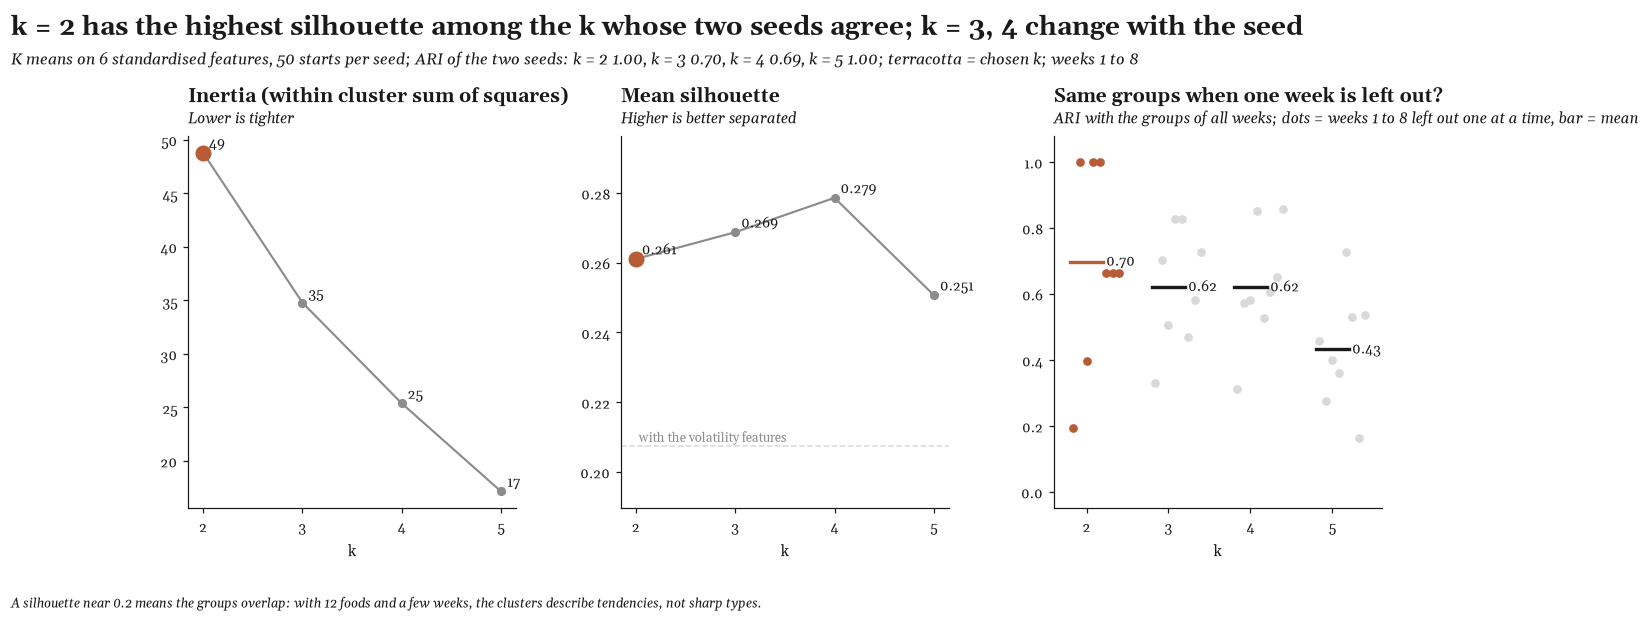

In [43]:
# M6.3 Elbow, silhouette and the week test side by side, the chosen k highlighted
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"wspace": 0.32})
for ax, col, lab in [(a1, "inertia", "Inertia (within cluster sum of squares)"), (a2, "silhouette", "Mean silhouette")]:
    ax.plot(ksum.index, ksum[col], color=GREY, marker="o", ms=5, lw=1.4)
    ax.scatter([K], [ksum.loc[K, col]], s=90, color=HIGHLIGHT, zorder=3)
    for k_, v in ksum[col].items():
        ax.text(k_, v, f"  {v:.3f}" if col == "silhouette" else f"  {v:.0f}", fontsize=9, va="bottom")
    ax.set_xticks(list(KS)); ax.set_xlabel("k")
    title(ax, lab, "Lower is tighter" if col == "inertia" else "Higher is better separated")
a2.axhline(ksum.loc[K, "silhouette_with_volatility"], color=LIGHT, lw=1, ls="--")
a2.text(KS[0], ksum.loc[K, "silhouette_with_volatility"], " with the volatility features", fontsize=8.5, va="bottom", color=GREY)
a2.margins(y=0.25)
for k_ in KS:
    a3.scatter([k_ - 0.16 + 0.08 * j for j in range(len(week_ari[k_]))], week_ari[k_], s=22, color=LIGHT if k_ != K else HIGHLIGHT, zorder=2)
    a3.plot([k_ - 0.2, k_ + 0.2], [ksum.loc[k_, "ari_drop_week_mean"]] * 2, color=HIGHLIGHT if k_ == K else INK, lw=2.2, zorder=3)
    a3.text(k_ + 0.24, ksum.loc[k_, "ari_drop_week_mean"], f"{ksum.loc[k_, 'ari_drop_week_mean']:.2f}", fontsize=9, va="center")
a3.set_xticks(list(KS)); a3.set_xlabel("k"); a3.set_ylim(-0.05, 1.08); a3.set_xlim(KS[0] - 0.4, KS[-1] + 0.6)
title(a3, "Same groups when one week is left out?", f"ARI with the groups of all weeks; dots = weeks {WEEKS_DONE[0]} to {WEEKS_DONE[-1]} left out one at a time, bar = mean")
seeds_all = bool((ksum["ari_two_seeds"] > 0.999).all())
unstable = [k_ for k_ in KS if ksum.loc[k_, "ari_two_seeds"] <= 0.999]
if K == ksum["silhouette"].idxmax():
    k_head = f"k = {K} has the highest silhouette, and its groups change least when one week is left out"
elif unstable:
    k_head = f"k = {K} has the highest silhouette among the k whose two seeds agree; k = {', '.join(map(str, unstable))} change{'s' if len(unstable) == 1 else ''} with the seed"
else:
    k_head = f"k = {K} has a silhouette within {ksum['silhouette'].max() - ksum.loc[K, 'silhouette']:.3f} of the best, and its groups change least when one week is left out"
# Build the seed comparison text separately for Python 3.11 compatibility
seed_scores = ", ".join(
    "k = {} {:.2f}".format(k_, ksum.loc[k_, "ari_two_seeds"])
    for k_ in KS
)

seed_note = (
    "two seeds give the same groups for every k"
    if seeds_all
    else "ARI of the two seeds: " + seed_scores
)

figure_title(
    fig,
    k_head,
    f"K means on 6 standardised features, 50 starts per seed; "
    f"{seed_note}; terracotta = chosen k; {PERIOD}",
    y=1.07
)
note(fig, "A silhouette near 0.2 means the groups overlap: with 12 foods and a few weeks, the clusters describe tendencies, not sharp types.", y=-0.07)
save(fig, FIG / "m6_kmeans_choice.png")
plt.show()

### M6.4 · Hierarchical clustering: Ward or average linkage
*Task:* check the k means groups with a method that does not need starting points, and keep an order of the foods for the heatmap of M7.
*Why this chart:* a dendrogram shows at which distance each food joins a group, so the reader sees which groups are tight and which merge late.
*Choices:* both linkages run on the same six standardised features; the dashed line cuts each tree into k groups; the cophenetic correlation says how well each tree keeps the original distances; the leaf order of the chosen tree is saved for M7.

Cophenetic correlation: {'ward': np.float64(0.642), 'average': np.float64(0.822)}
Agreement with k means at k = 2 (ARI): {'ward': 0.66, 'average': 0.0}
Group sizes with average linkage: [1, 11]
Foods alone in a group with average linkage: ['Onion']


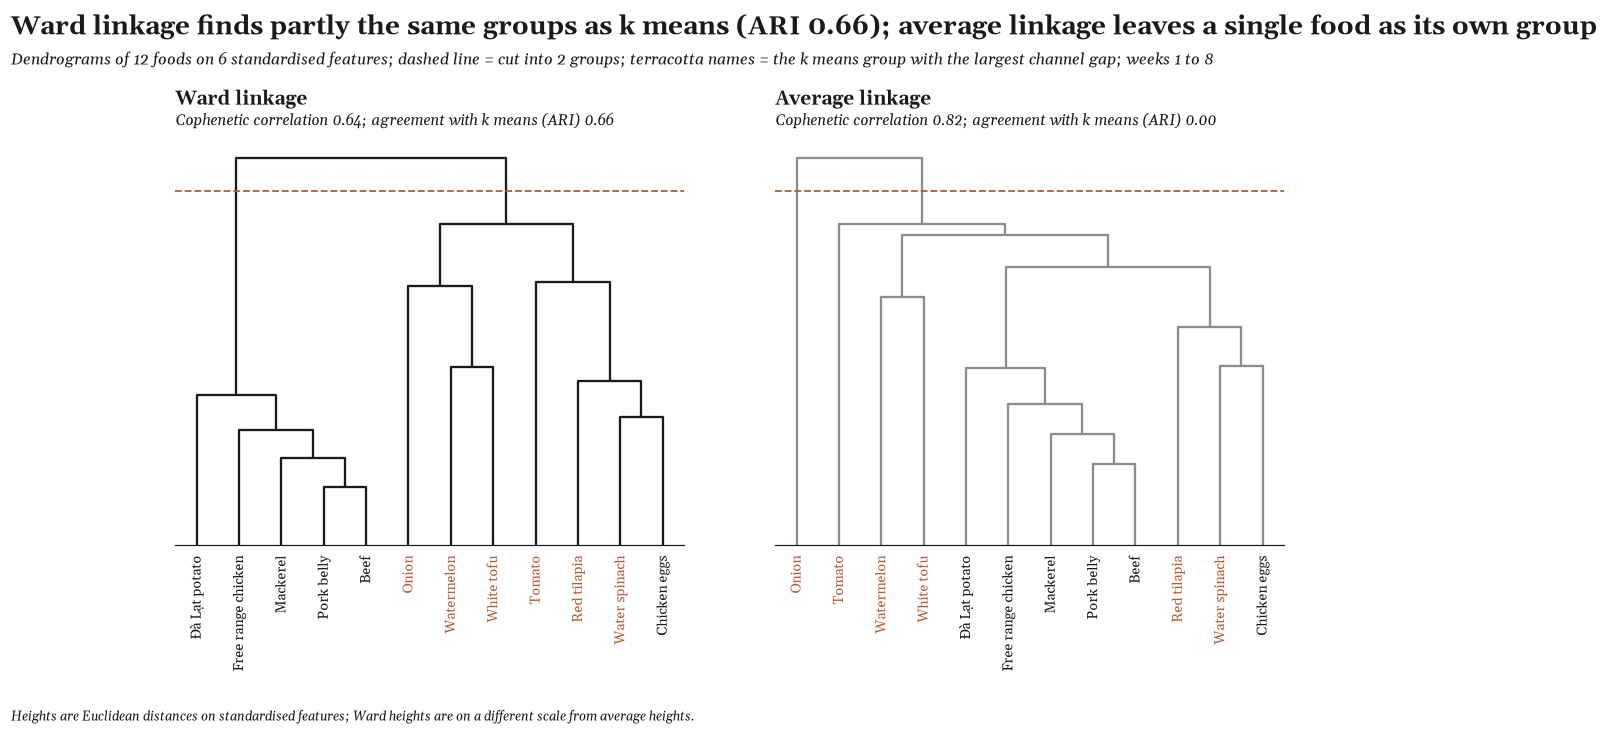

Leaf order saved for M7: ['Đà Lạt potato', 'Free range chicken', 'Mackerel', 'Pork belly', 'Beef', 'Onion', 'Watermelon', 'White tofu', 'Tomato', 'Red tilapia', 'Water spinach', 'Chicken eggs']


In [44]:
# M6.4 Ward and average linkage: cophenetic correlation, agreement with k means, dendrograms
D = pdist(Z)
links = {"ward": ward_link, "average": linkage(Z, method="average")}
coph = {m: cophenet(lk, D)[0] for m, lk in links.items()}
agree = {m: adjusted_rand_score(labels_k[K], fcluster(lk, K, criterion="maxclust")) for m, lk in links.items()}
print("Cophenetic correlation:", {m: round(v, 3) for m, v in coph.items()})
print(f"Agreement with k means at k = {K} (ARI):", {m: round(v, 2) for m, v in agree.items()})

# the k means group with the largest gap between app and wet market is the highlight in every chart that follows
labels = pd.Series(labels_k[K], index=feat.index)
gap_by_cluster = (feat["level_app"] - feat["level_market"]).groupby(labels).mean().sort_values(ascending=False)
LEAF_COLOR = {it: HIGHLIGHT if labels[it] == gap_by_cluster.index[0] else INK for it in feat.index}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"wspace": 0.18})
leaf_orders = {}
for ax, (m, lk) in zip(axes, links.items()):
    cut = (lk[-K, 2] + lk[-K + 1, 2]) / 2      # a height between the merges that leave K groups
    dn = dendrogram(lk, ax=ax, labels=[ITEM_EN[c] for c in feat.index], leaf_rotation=90, leaf_font_size=9,
                    color_threshold=0, above_threshold_color=INK if m == "ward" else GREY)
    leaf_orders[m] = [feat.index[i] for i in dn["leaves"]]
    for tick, it in zip(ax.get_xticklabels(), leaf_orders[m]):
        tick.set_color(LEAF_COLOR[it])
    ax.axhline(cut, color=HIGHLIGHT, lw=1.2, ls="--")
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    title(ax, f"{m.capitalize()} linkage", f"Cophenetic correlation {coph[m]:.2f}; agreement with k means (ARI) {agree[m]:.2f}")
sizes_avg = pd.Series(fcluster(links["average"], K, criterion="maxclust")).value_counts()
ward_word = ("the same groups as" if agree["ward"] > 0.999 else "nearly the same groups as" if agree["ward"] >= 0.75
             else "partly the same groups as" if agree["ward"] >= 0.5 else "other groups than")
n_single = int((sizes_avg == 1).sum())
avg_part = ("average linkage leaves single foods as groups of their own" if n_single > 1 else "average linkage leaves a single food as its own group") if n_single else f"average linkage agrees less (ARI {agree['average']:.2f})"
print("Group sizes with average linkage:", sorted(sizes_avg.tolist()))
avg_lab = pd.Series(fcluster(links["average"], K, criterion="maxclust"), index=feat.index)
print("Foods alone in a group with average linkage:", [ITEM_EN[i] for i in feat.index if (avg_lab == avg_lab[i]).sum() == 1])
figure_title(fig, f"Ward linkage finds {ward_word} k means (ARI {agree['ward']:.2f}); {avg_part}",
             f"Dendrograms of 12 foods on 6 standardised features; dashed line = cut into {K} groups; terracotta names = the k means group with the largest channel gap; {PERIOD}", y=1.06)
note(fig, "Heights are Euclidean distances on standardised features; Ward heights are on a different scale from average heights.", y=-0.2)
save(fig, FIG / "m6_dendrograms.png")
plt.show()
LINK = "ward"
pd.Series(leaf_orders[LINK], name="item_code").to_csv(CLEAN / "m6_leaf_order.csv", index=False)
print("Leaf order saved for M7:", [ITEM_EN[c] for c in leaf_orders[LINK]])

**Why Ward linkage.** Average linkage keeps the original distances better (higher cophenetic correlation), but it does so by leaving one food on its own until the last step: cut into two groups, it puts onion alone and the other eleven foods together. A group of one food tells a student nothing. Ward linkage joins the groups that add the least spread, the same goal as k means, and it agrees with k means much better than average linkage does (the ARI above). The two methods differ in one food: Ward puts chicken eggs with the large gap group. My group therefore uses Ward linkage for the leaf order of M7 and k means for the final groups. The names of the foods are coloured by their k means group, so the reader can see where the two methods agree.

### M6.5 · Cluster names and segment profiles
*Task:* describe each group of foods so that a student can act on it.
*Why this chart:* the dot plot on the left shows, food by food, how much dearer the supermarket and the app are than the wet market, which is the gap that names the groups; the heatmap shows the mean of the six features per group, with real values printed; the PCA map shows where the groups sit; the cards sum up each group.
*Choices:* the names describe price behaviour, not the kind of food; a name describes the median app gap of its group, and the code prints the foods that sit at the border between the groups; the group with the largest gap is the one highlight; the heatmap uses the diverging map of the house style, centred at 0.

In [45]:
# M6.5 Final clusters (k means, chosen k), named by the gap between the app and the wet market, and checked food by food
NAMES_BY_RANK = {2: ["Large channel gap", "Small channel gap"],
                 3: ["Large channel gap", "Middle channel gap", "Small channel gap"],
                 4: ["Large channel gap", "Middle channel gap", "Small channel gap", "Smallest channel gap"],
                 5: ["Largest channel gap", "Large channel gap", "Middle channel gap", "Small channel gap", "Smallest channel gap"]}[K]
cname = {c: NAMES_BY_RANK[r] for r, c in enumerate(gap_by_cluster.index)}
group = labels.map(cname)
over_market = pd.DataFrame({"super": np.expm1(feat["level_super"] - feat["level_market"]),
                            "app": np.expm1(feat["level_app"] - feat["level_market"])})        # % above the wet market price
app_range = over_market.groupby(group)["app"].agg(["min", "max"]).reindex(NAMES_BY_RANK)
super_range = over_market.groupby(group)["super"].agg(["min", "max"]).reindex(NAMES_BY_RANK)
app_median = over_market.groupby(group)["app"].median().reindex(NAMES_BY_RANK)
border = []                                   # foods whose own app gap lies inside the range of the next group
for r in range(K - 1):
    hi_g, lo_g = NAMES_BY_RANK[r], NAMES_BY_RANK[r + 1]
    border += [it for it in feat.index if group[it] == hi_g and over_market.loc[it, "app"] <= app_range.loc[lo_g, "max"]]
    border += [it for it in feat.index if group[it] == lo_g and over_market.loc[it, "app"] >= app_range.loc[hi_g, "min"]]
NAMES_FIT = not border
print("Median app gap per group:", {nm: f"{v:+.0%}" for nm, v in app_median.items()})
print("Foods at the border between groups:", {ITEM_EN[it]: f"{group[it]}, app {over_market.loc[it, 'app']:+.0%}, wet market change {feat.loc[it, 'change_market']:+.1%} per week" for it in border} or "none")

clusters = pd.DataFrame({"item_name": [ITEM_EN[c] for c in feat.index], "cluster": group,
                         "ward_cluster": fcluster(ward_link, K, criterion="maxclust"),
                         "super_over_market": over_market["super"].round(3), "app_over_market": over_market["app"].round(3),
                         "PC1": scores["PC1"].round(3), "PC2": scores["PC2"].round(3)}, index=feat.index)
clusters.to_csv(CLEAN / "m6_clusters.csv")
prof_raw_pct = as_pct(feat.groupby(group).mean().reindex(NAMES_BY_RANK)) / 100
prof_z = pd.DataFrame(Z, index=feat.index, columns=feat.columns).groupby(group).mean().reindex(NAMES_BY_RANK)
members = clusters.groupby("cluster")["item_name"].apply(list).reindex(NAMES_BY_RANK)
for nm in NAMES_BY_RANK:
    print(f"{nm}: {', '.join(members[nm])} | app over wet market {app_range.loc[nm, 'min']:+.0%} to {app_range.loc[nm, 'max']:+.0%}, "
          f"supermarket {super_range.loc[nm, 'min']:+.0%} to {super_range.loc[nm, 'max']:+.0%}")
display((prof_raw_pct * 100).round(1).rename(columns=FEAT_LABEL))
display((over_market * 100).round(0).rename(index=ITEM_EN).assign(group=group.rename(index=ITEM_EN)).sort_values("app", ascending=False))

Median app gap per group: {'Large channel gap': '+67%', 'Small channel gap': '+21%'}
Foods at the border between groups: {'Tomato': 'Large channel gap, app +34%, wet market change +9.6% per week', 'Chicken eggs': 'Small channel gap, app +41%, wet market change +1.3% per week'}
Large channel gap: Water spinach, Tomato, Watermelon, Onion, White tofu, Red tilapia | app over wet market +34% to +74%, supermarket +27% to +44%
Small channel gap: Pork belly, Mackerel, Beef, Free range chicken, Đà Lạt potato, Chicken eggs | app over wet market +12% to +41%, supermarket +1% to +19%


,Price level · Wet market,Price level · Supermarket,Price level · Delivery app,Weekly change · Wet market,Weekly change · Supermarket,Weekly change · Delivery app
Large channel gap,-24.5,1.8,22.5,1.6,1.9,-1.5
Small channel gap,-9.7,-0.6,10.1,0.7,3.2,1.4


,super,app,group
Water spinach,38.0,74.0,Large channel gap
White tofu,44.0,73.0,Large channel gap
Red tilapia,31.0,70.0,Large channel gap
Onion,41.0,65.0,Large channel gap
Watermelon,29.0,62.0,Large channel gap
Chicken eggs,19.0,41.0,Small channel gap
Tomato,27.0,34.0,Large channel gap
Mackerel,14.0,27.0,Small channel gap
Đà Lạt potato,14.0,25.0,Small channel gap
Beef,6.0,16.0,Small channel gap


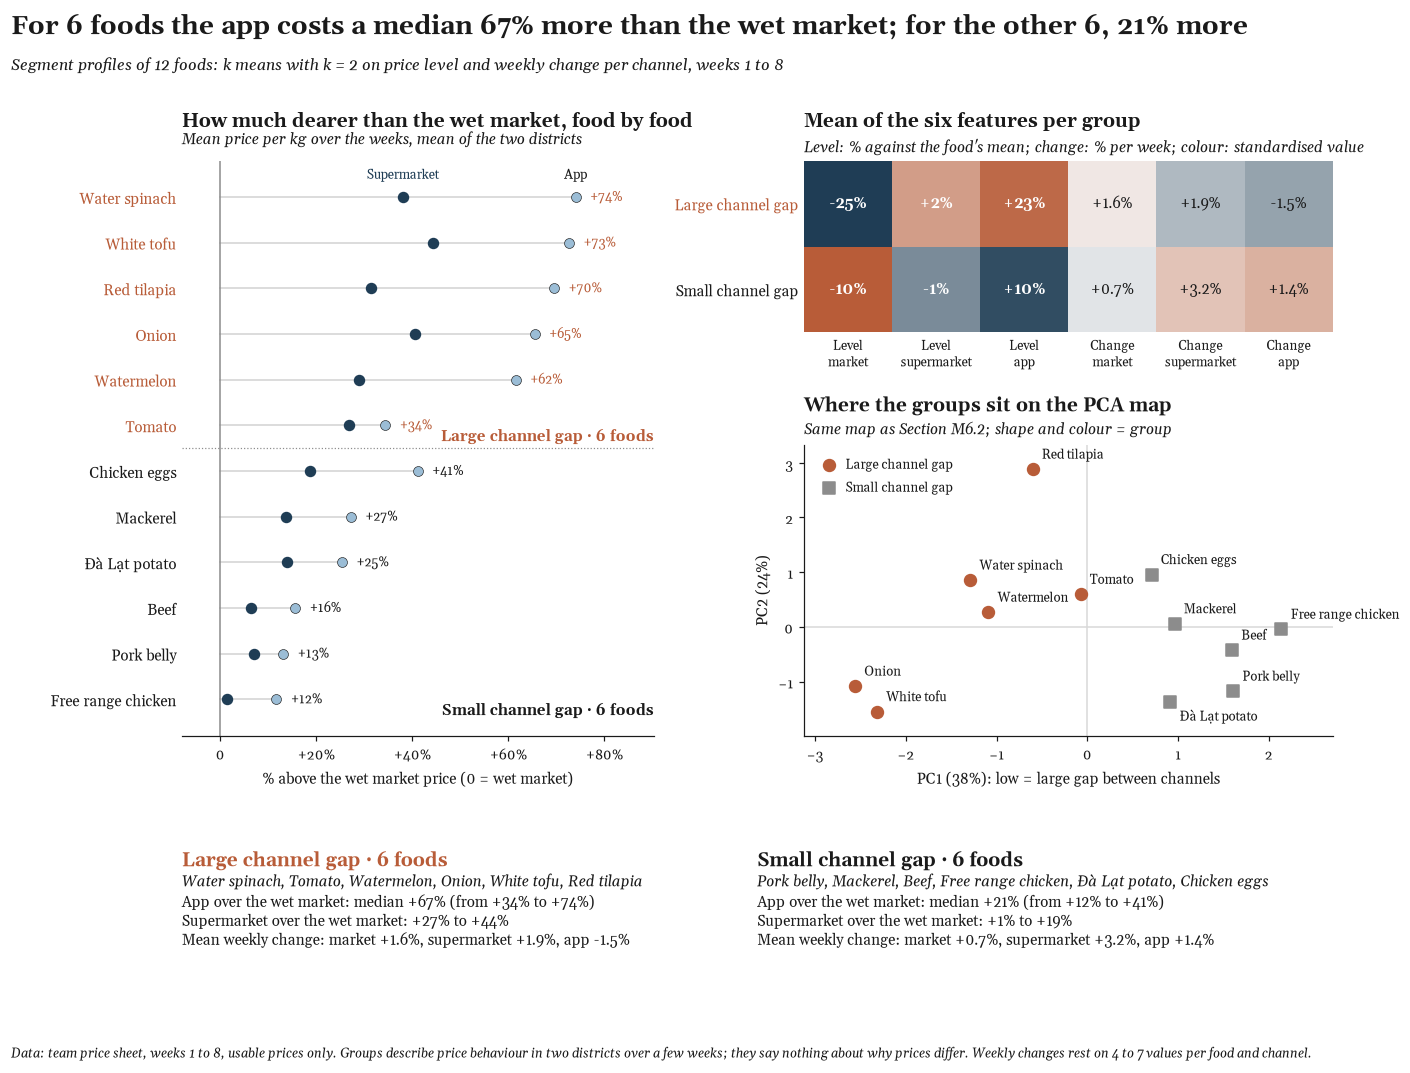

In [46]:
# M6.5 One page of segment profiles: the gap food by food, the group means, the PCA map and one card per group
import textwrap
GROUP_COLOR = {nm: HIGHLIGHT if r == 0 else (INK if r == K - 1 else GREY) for r, nm in enumerate(NAMES_BY_RANK)}
MARK = dict(zip(NAMES_BY_RANK, ["o", "s", "^", "D", "v"]))
fig = plt.figure(figsize=(13.5, 9.3))
gs = fig.add_gridspec(3, 2, height_ratios=[0.62, 1.05, 0.36], width_ratios=[1, 1.12], hspace=0.6, wspace=0.3)

# A. the gap food by food
ax = fig.add_subplot(gs[0:2, 0])
order = over_market.assign(g=group.map({nm: r for r, nm in enumerate(NAMES_BY_RANK)})).sort_values(["g", "app"], ascending=[False, True]).index
ypos = {it: y for y, it in enumerate(order)}
ax.axvline(0, color=GREY, lw=1)
for it in order:
    y = ypos[it]
    ax.plot([0, over_market.loc[it, "app"] * 100], [y, y], color=LIGHT, lw=1.2, zorder=1)
    ax.scatter(over_market.loc[it, "super"] * 100, y, s=42, color=CHANNEL["Siêu thị"], zorder=3)
    ax.scatter(over_market.loc[it, "app"] * 100, y, s=42, color=CHANNEL["App"], edgecolor=INK, lw=0.4, zorder=3)
    ax.text(over_market.loc[it, "app"] * 100 + 3, y, f"{over_market.loc[it, 'app']:+.0%}", va="center", fontsize=8.5,
            color=HIGHLIGHT if group[it] == NAMES_BY_RANK[0] else INK)
ax.set_yticks(range(len(order)), [ITEM_EN[it] for it in order], fontsize=9.5)
for tick, it in zip(ax.get_yticklabels(), order):
    tick.set_color(HIGHLIGHT if group[it] == NAMES_BY_RANK[0] else INK)
for r in range(1, K):                                   # a thin line between the groups, and the group names on the right
    ax.axhline(sum((group == nm).sum() for nm in NAMES_BY_RANK[K - r:]) - 0.5, color=GREY, lw=0.8, ls=":")
xmax = over_market["app"].max() * 100 * 1.22
for nm in NAMES_BY_RANK:                                # the group name sits under the group's last row, at the right
    ys = [ypos[it] for it in order if group[it] == nm]
    ax.text(xmax, min(ys) - 0.45, f"{nm} · {len(ys)} foods", ha="right", va="bottom", fontsize=9.5, fontweight="bold", color=GROUP_COLOR[nm])
top = order[-1]
ax.annotate("Supermarket", (over_market.loc[top, "super"] * 100, ypos[top]), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=8.5, color=CHANNEL["Siêu thị"])
ax.annotate("App", (over_market.loc[top, "app"] * 100, ypos[top]), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=8.5, color=INK)
ax.set_xlim(min(0, over_market.values.min() * 100) - 8, xmax); ax.set_ylim(-0.8, len(order) - 0.2)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%" if v else "0")
ax.set_xlabel("% above the wet market price (0 = wet market)")
ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
title(ax, "How much dearer than the wet market, food by food", "Mean price per kg over the weeks, mean of the two districts")

# B. the mean features of each group
ax = fig.add_subplot(gs[0, 1])
lim = np.abs(prof_z.values).max()
ax.imshow(prof_z.values, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
for r in range(prof_z.shape[0]):
    for c in range(prof_z.shape[1]):
        v, z = prof_raw_pct.iloc[r, c] * 100, prof_z.iloc[r, c]
        txt = (f"{v:+.0f}%" if abs(v) >= 0.5 else "0%") if prof_z.columns[c].startswith("level") else (f"{v:+.1f}%" if abs(v) >= 0.05 else "0%")
        ax.text(c, r, txt, ha="center", va="center", fontsize=10,
                color="white" if abs(z) > lim * 0.55 else INK, fontweight="bold" if abs(z) > lim * 0.55 else "normal")
ax.set_xticks(range(prof_z.shape[1]), [("Level" if c.startswith("level") else "Change") + "\n" + {"Chợ": "market", "Siêu thị": "supermarket", "App": "app"}[FEAT_CH[c]]
                                         for c in prof_z.columns], fontsize=8.5)
ax.set_yticks(range(prof_z.shape[0]), prof_z.index, fontsize=9.5)
for tick, nm in zip(ax.get_yticklabels(), prof_z.index):
    tick.set_color(GROUP_COLOR[nm])
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
title(ax, "Mean of the six features per group", "Level: % against the food's mean; change: % per week; colour: standardised value")

# C. the PCA map
ax = fig.add_subplot(gs[1, 1])
ax.axhline(0, color=LIGHT, lw=1); ax.axvline(0, color=LIGHT, lw=1)
for nm in NAMES_BY_RANK:
    pts = clusters[clusters["cluster"] == nm]
    ax.scatter(pts["PC1"], pts["PC2"], s=60, marker=MARK[nm], color=GROUP_COLOR[nm] if GROUP_COLOR[nm] != INK else GREY, zorder=3, label=nm)
ax.margins(x=0.12, y=0.1)
ax.set_xlabel(f"PC1 ({evr.iloc[0]:.0%}): low = large gap between channels"); ax.set_ylabel(f"PC2 ({evr.iloc[1]:.0%})")
ax.legend(loc="upper left", fontsize=8.5, frameon=False, handletextpad=0.3)
title(ax, "Where the groups sit on the PCA map", "Same map as Section M6.2; shape and colour = group")
place_labels(ax, clusters[["PC1", "PC2"]].values, clusters["item_name"].tolist(), avoid=[ax.get_legend()], fontsize=8.5)

# D. one card per group
ax = fig.add_subplot(gs[2, :]); ax.axis("off")
w = 1 / K
for j, nm in enumerate(NAMES_BY_RANK):
    p = prof_raw_pct.loc[nm] * 100
    x0 = j * w
    ax.text(x0, 1.0, f"{nm} · {len(members[nm])} foods", fontsize=12.5, fontweight="bold", color=GROUP_COLOR[nm], transform=ax.transAxes, va="top")
    names_txt = textwrap.fill(", ".join(members[nm]), 88)
    ax.text(x0, 0.80, names_txt, fontsize=9.5, style="italic", transform=ax.transAxes, va="top", linespacing=1.4)
    first = 0.80 - 0.19 * (names_txt.count("\n") + 1) - 0.06
    lines = [f"App over the wet market: median {app_median[nm]:+.0%} (from {app_range.loc[nm, 'min']:+.0%} to {app_range.loc[nm, 'max']:+.0%})",
             f"Supermarket over the wet market: {super_range.loc[nm, 'min']:+.0%} to {super_range.loc[nm, 'max']:+.0%}",
             f"Mean weekly change: market {p['change_market']:+.1f}%, supermarket {p['change_super']:+.1f}%, app {p['change_app']:+.1f}%"]
    for k_, ln in enumerate(lines):
        ax.text(x0, first - k_ * 0.19, ln, fontsize=9.5, transform=ax.transAxes, va="top")

big, small = NAMES_BY_RANK[0], NAMES_BY_RANK[-1]
tail = (f"for the other {len(members[small])}, {app_median[small]:.0%} more" if K == 2
        else f"for the {len(members[small])} foods with the smallest gap, {app_median[small]:.0%} more")
figure_title(fig, f"For {len(members[big])} foods the app costs a median {app_median[big]:.0%} more than the wet market; {tail}",
             f"Segment profiles of 12 foods: k means with k = {K} on price level and weekly change per channel, {PERIOD}", y=0.995)
note(fig, f"Data: team price sheet, {PERIOD}, usable prices only. Groups describe price behaviour in two districts over a few weeks; they say nothing about why prices differ. "
          f"Weekly changes rest on {min(n_chg.values())} to {max(n_chg.values())} values per food and channel.", y=0.015)
save(fig, FIG / "m6_segment_profiles.png")
plt.show()

### M6.6 · What the clusters do not mean
1. **They are not types of food.** The groups come from price behaviour, not from the kind of food. The large gap group holds vegetables, a fruit, tofu and a fish, while potato and mackerel sit in the small gap group; a vegetable or a fish does not always behave like the others.
2. **They do not explain why.** PCA loadings and clusters describe patterns in our 12 foods. They do not say that the wet market is cheaper *because* of freshness, supply or rent.
3. **They are coarse, and two foods sit at the border.** The silhouette is low (about 0.26), so the groups overlap. Tomato joins the large gap group although its app costs only 34% more than the wet market, because its wet market price rose fastest (about 10% per week); chicken eggs stay in the small gap group although their app costs 41% more. Tomato is also the food that moves most often in the tests of Section M6.3: it changes group in four of the eight week tests, in both district tests, and in every food test where a food moves. Finer splits, such as three or four groups, change with the random seed, so my group does not name them.
4. **They depend on choices.** Another way to scale the features, adding the volatility, or a different set of weeks can move a food from one group to another. The weekly changes rest on four to seven values per food and channel, so they add more noise than the price levels.
5. **One part rests on doubtful prices.** In week 4, free range chicken cost about 90,000 VND per kg in all three channels, against 110,000 to 167,000 VND in the other weeks, and the six tofu prices of week 6 are flagged as outliers (Section M2.9). If these prices are wrong, the weekly changes of chicken and tofu are wrong too. The team checks the photos.
6. **They cover two districts and eight weeks.** They describe Quận 10 and Quận 3 in autumn 2026, not the whole city or the whole year.

**What a student can take from it.** For the foods in the large gap group, the channel decides a large part of the price, so these are the foods to buy at the wet market. For the foods in the small gap group, the app still costs more, but a student loses less by buying where it is most convenient.

---
# M7 · Many dimensions

**What the brief asks.** A heatmap of item × week of the price index, a treemap of the basket cost (group, then item), and parallel coordinates of the items across channels and districts. Notes on axis order, scaling, colour map and seriation. For CP2: three finished charts with action titles, the master table done, at least half of the field data, and the team log up to date. The sealed twist arrives at CP2.

**Plan and choices.** Section M7.1 draws the price index of each food in each week as a heatmap. Its colour map is the diverging map of the house style, centred at 100, and its rows follow the Ward leaf order of M6.4, so foods with a similar path sit next to each other. Section M7.2 splits the basket cost into food groups and foods as a treemap, and Section M7.2b shows the same split as stacked bars with beef taken out. Section M7.3 draws parallel coordinates of the 12 foods: one panel per M6 group and district, three channel axes in the house order (wet market, supermarket, delivery app), and an index that sets the mean of the six prices of each food to 100.

**Status on 18 November 2026.** The four charts use all eight weeks. Trần Nhã Đoan drew M7.1 and M7.2, and Trần Nguyễn Thanh Thảo drew M7.2b and M7.3. Nguyễn Hoàng Minh checked them against the brief and fixed the numbers, labels and colours (see the AI log). The sealed twist arrives at CP2.

### M7.1 · Heatmap: price index by food and week

*Task:* see which foods became cheaper or dearer than in week 1, and in which weeks.

*Why this chart:* a heatmap shows 12 foods in 8 weeks, 96 values, on one page. The colour shows the direction of the change and the printed number shows its size.

*Choices:* each cell is the median price index of a food in one week over the three channels and the two districts (week 1 = 100). The colour map is the diverging map of the house style, centred at 100, from 50 to 150. The rows follow the Ward leaf order of M6.4 (seriation), so foods with a similar path sit next to each other; the columns follow the weeks. A hatched cell has no usable price, and an asterisk marks a cell that rests on two prices or fewer.

Usable prices without an index: 8
Cells with a price: 95 of 96; empty cells: 1
Cells that rest on 2 prices or fewer: [('Onion', 4, 2)]
                    weeks below 100  weeks above 100
Onion                             7                0
Free range chicken                5                1
Watermelon                        5                1
Mackerel                          3                4
White tofu                        3                1
Đà Lạt potato                     2                3
Pork belly                        2                4
Water spinach                     2                4
Beef                              1                6
Red tilapia                       1                5
Chicken eggs                      1                6
Tomato                            0                5
Title: Onion stays below its week 1 price in all 7 later weeks; beef and chicken eggs stay above in 6 of 7


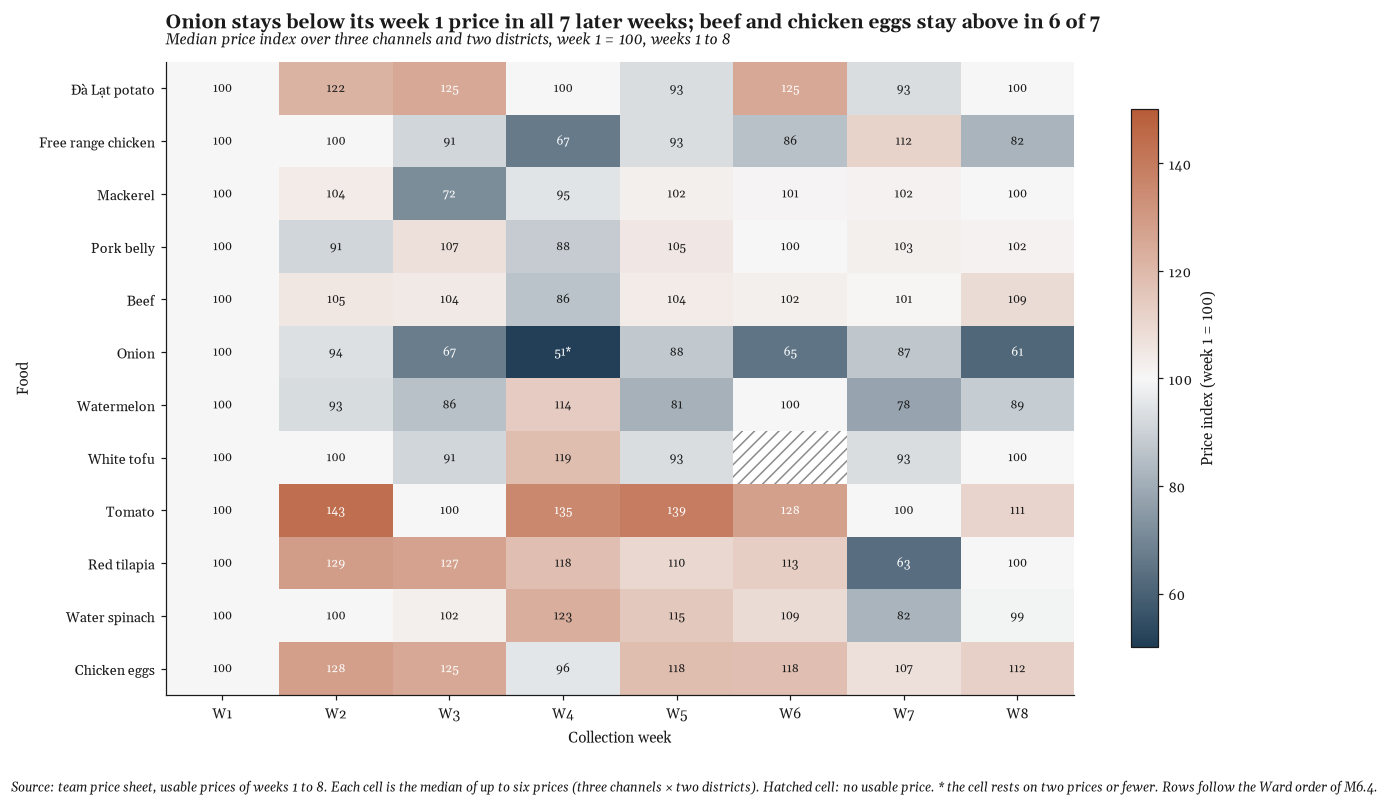

In [47]:
# M7.1 Heatmap: median price index of each food in each week, rows in the Ward order of M6.4
from matplotlib.patches import Rectangle

heat_data = master[master["usable"]].copy()
heat_data["index_w1"] = pd.to_numeric(heat_data["index_w1"], errors="coerce")
print("Usable prices without an index:", int(heat_data["index_w1"].isna().sum()))

# Median over the three channels and two districts, and the number of prices behind each cell
heat = (heat_data.pivot_table(index="item_code", columns="week", values="index_w1", aggfunc="median")
        .reindex(index=leaf_orders["ward"], columns=WEEKS_DONE).astype(float))
heat_n = (heat_data.pivot_table(index="item_code", columns="week", values="index_w1", aggfunc="count")
          .reindex(index=heat.index, columns=WEEKS_DONE).fillna(0).astype(int))
heat.index = [ITEM_EN[c] for c in heat.index]
heat_n.index = heat.index
THIN = 2                                             # a cell with this many prices or fewer gets an asterisk

# The numbers behind the title: in how many of the later weeks each food sits below or above week 1
later = heat.drop(columns=WEEKS_DONE[0])
n_later = later.shape[1]
below, above = (later < 100).sum(axis=1), (later > 100).sum(axis=1)
print(f"Cells with a price: {int(heat.notna().sum().sum())} of {heat.size}; empty cells: {int(heat.isna().sum().sum())}")
print(f"Cells that rest on {THIN} prices or fewer:",
      [(f, w, int(heat_n.loc[f, w])) for f in heat.index for w in heat.columns if 0 < heat_n.loc[f, w] <= THIN])
print(pd.DataFrame({"weeks below 100": below, "weeks above 100": above}).sort_values("weeks below 100", ascending=False).to_string())


def food_list(names):
    """['Beef', 'Chicken eggs'] -> 'beef and chicken eggs' (place names keep their capitals)."""
    names = [n if n.startswith("Đà Lạt") else n[0].lower() + n[1:] for n in names]
    return names[0] if len(names) == 1 else ", ".join(names[:-1]) + " and " + names[-1]


low_foods = list(below[below == below.max()].index)
high_foods = list(above[above == above.max()].index)
low_txt, high_txt = food_list(low_foods), food_list(high_foods)
when_low = f"in all {n_later} later weeks" if below.max() == n_later else f"in {below.max()} of {n_later} later weeks"
heat_head = (f"{low_txt[0].upper() + low_txt[1:]} {'stays' if len(low_foods) == 1 else 'stay'} below "
             f"{'its' if len(low_foods) == 1 else 'their'} week 1 price {when_low}; "
             f"{high_txt} {'stays' if len(high_foods) == 1 else 'stay'} above in {above.max()} of {n_later}")
print("Title:", heat_head)

fig, ax = plt.subplots(figsize=(12, 7))
cmap = DIV.copy()
cmap.set_bad(PAPER)
im = ax.imshow(heat.values, aspect="auto", cmap=cmap, norm=div_norm(center=100, spread=50))
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels([f"W{w}" for w in heat.columns])
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
ax.set_xlabel("Collection week")
ax.set_ylabel("Food")

for i, food in enumerate(heat.index):
    for j, week in enumerate(heat.columns):
        value = heat.loc[food, week]
        if pd.isna(value):                           # no usable price: a hatched cell, not a colour
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=PAPER, edgecolor=GREY, hatch="///", lw=0))
            continue
        star = "*" if heat_n.loc[food, week] <= THIN else ""
        ax.text(j, i, f"{value:.0f}{star}", ha="center", va="center", fontsize=8,
                color=PAPER if (value >= 125 or value <= 75) else INK)

cbar = fig.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label("Price index (week 1 = 100)")
title(ax, heat_head, f"Median price index over three channels and two districts, week 1 = 100, {PERIOD}")
note(fig, f"Source: team price sheet, usable prices of {PERIOD}. Each cell is the median of up to six prices "
          "(three channels × two districts). Hatched cell: no usable price. * the cell rests on two prices or fewer. "
          "Rows follow the Ward order of M6.4.")
fig.tight_layout()
save(fig, FIG / "m7_heatmap.png")
plt.show()

### M7.2 · Treemap: basket cost by food group and food

*Task:* show which food groups and which foods make up the cost of the basket in each channel.

*Why this chart:* a treemap shows a whole and its parts on two levels at once. The width of a column is the share of a food group, and the height of a box is the share of one food inside its group.

*Choices:* the basket holds 1 kg of each food sold by weight and 10 eggs. Prices are the means of the weeks in which all three channels have a complete basket, over both districts. Inside each group the foods go from the dearest at the bottom to the cheapest at the top. The largest food carries the finding and gets the highlight colour; the other protein foods are grey and the vegetables and fruit light grey. Every box names its food and its cost.

Weeks with a complete basket in all three channels: [1, 2, 3, 5, 7, 8]
Largest food in each channel: {'Wet market': 'Beef', 'Supermarket': 'Beef', 'Delivery app': 'Beef'}


,Basket (VND),Beef (VND),Beef share (%)
channel,,,
Wet market,1050381.0,265667.0,25.3
Supermarket,1185730.0,284941.0,24.0
Delivery app,1328135.0,314550.0,23.7


Title: Beef is the largest of the 12 foods in every channel, 24% to 25% of the basket cost


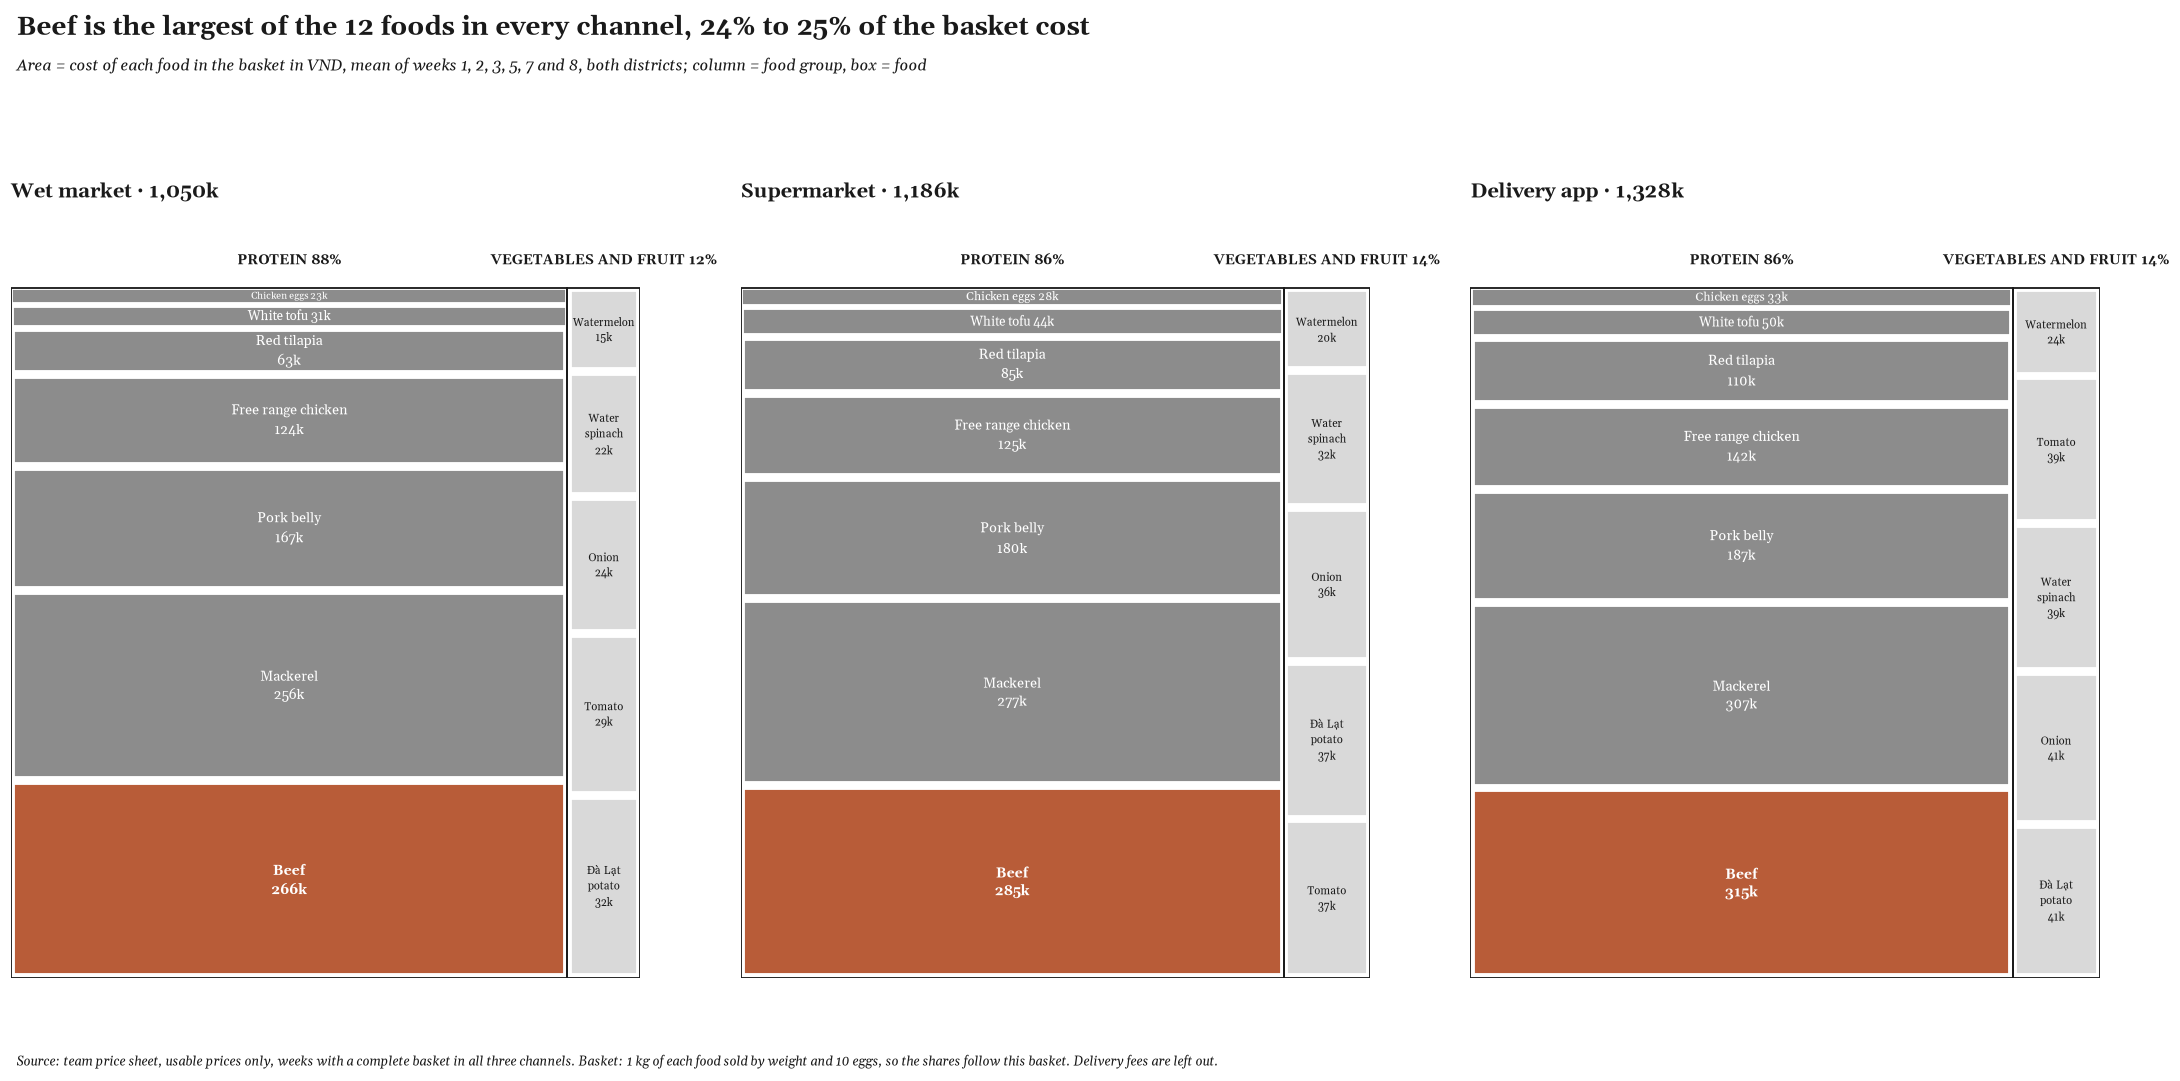

In [48]:
# M7.2 Treemap of the basket cost: food group, then food, one panel per channel

# 1. The weeks in which all three channels have a complete basket
complete_by_week = complete.unstack("channel").reindex(columns=CHANNEL_ORDER)
common_weeks = complete_by_week.index[complete_by_week.all(axis=1)].tolist()
if not common_weeks:
    raise ValueError("No week has a complete basket in all three channels.")
weeks_txt = ", ".join(map(str, common_weeks[:-1])) + " and " + str(common_weeks[-1])
print("Weeks with a complete basket in all three channels:", common_weeks)

# 2. Mean price of each food over those weeks, times the basket quantity
in_common = wk_items.index.get_level_values("week").isin(common_weeks)
mean_item_prices = wk_items.loc[in_common].groupby(level="channel").mean().reindex(CHANNEL_ORDER).astype(float)
basket_item_cost = mean_item_prices.mul(QTY_S.astype(float), axis=1)
group_map = item_spec.set_index("item_code")["item_group"]
GROUP_EN = {"Đạm": "Protein", "Rau củ quả": "Vegetables and fruit"}
GROUP_FILL = {"Đạm": GREY, "Rau củ quả": LIGHT}      # context in grey; the largest food gets HIGHLIGHT

# 3. The numbers behind the title: the share of each food in each basket
share = basket_item_cost.div(basket_item_cost.sum(axis=1), axis=0)
top_by_channel = share.idxmax(axis=1)
top_item = top_by_channel.loc[CHANNEL_ORDER[0]]
print("Largest food in each channel:", {CHANNEL_EN[ch]: ITEM_EN[it] for ch, it in top_by_channel.items()})
display(pd.DataFrame({"Basket (VND)": basket_item_cost.sum(axis=1).round(0),
                      f"{ITEM_EN[top_item]} (VND)": basket_item_cost[top_item].round(0),
                      f"{ITEM_EN[top_item]} share (%)": (share[top_item] * 100).round(1)}).rename(index=CHANNEL_EN))
lo, hi = round(share[top_item].min() * 100), round(share[top_item].max() * 100)
share_txt = f"{lo}%" if lo == hi else f"{lo}% to {hi}%"
if (top_by_channel == top_item).all():
    tree_head = f"{ITEM_EN[top_item]} is the largest of the 12 foods in every channel, {share_txt} of the basket cost"
else:
    tree_head = f"{ITEM_EN[top_item]} is the largest food at the wet market, {share_txt} of the basket cost"
print("Title:", tree_head)

# 4. Slice and dice layout: one column per food group, one box per food
fig, axes = plt.subplots(1, 3, figsize=(20, 9))
boxes = []                                           # labelled after the layout is fixed
for ax, ch in zip(axes, CHANNEL_ORDER):
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 110)
    ax.axis("off")
    data = pd.DataFrame({"item_code": basket_item_cost.columns, "cost": basket_item_cost.loc[ch].values})
    data["item_group"] = data["item_code"].map(group_map)
    data = data[data["cost"].gt(0) & data["item_group"].notna()]
    group_totals = data.groupby("item_group")["cost"].sum().sort_values(ascending=False)
    total = group_totals.sum()
    x0 = 0
    for grp, grp_total in group_totals.items():
        width = grp_total / total * 100
        ax.text(x0 + width / 2, 104, f"{GROUP_EN[grp].upper()} {grp_total / total:.0%}", ha="center", va="center",
                fontsize=9, fontweight="bold", color=INK)
        y0 = 0
        for _, item in data[data["item_group"] == grp].sort_values("cost", ascending=False).iterrows():
            height = item["cost"] / grp_total * 100
            gap = min(0.5, height * 0.08)            # thin boxes keep most of their height for the label
            fill = HIGHLIGHT if item["item_code"] == top_item else GROUP_FILL[grp]
            ax.add_patch(Rectangle((x0 + gap, y0 + gap), max(width - 2 * gap, 0), max(height - 2 * gap, 0),
                                   facecolor=fill, edgecolor=PAPER, linewidth=1.2))
            boxes.append((ax, x0, y0, width, height, ITEM_EN[item["item_code"]], item["cost"], fill))
            y0 += height
        ax.add_patch(Rectangle((x0, 0), width, 100, fill=False, edgecolor=INK, linewidth=1.2))
        x0 += width
    ax.set_title(f"{CHANNEL_EN[ch]} · {fmt_vnd(total)}", fontsize=13, fontweight="bold", pad=14)

figure_title(fig, tree_head,
             f"Area = cost of each food in the basket in VND, mean of weeks {weeks_txt}, both districts; column = food group, box = food")
note(fig, "Source: team price sheet, usable prices only, weeks with a complete basket in all three channels. "
          "Basket: 1 kg of each food sold by weight and 10 eggs, so the shares follow this basket. Delivery fees are left out.")
fig.tight_layout(rect=[0, 0.04, 1, 0.88])

# 5. Labels: two lines in a tall box, one line in a flat box, one word per line in a narrow column
fig.canvas.draw()
for ax, x0, y0, width, height, name, cost, fill in boxes:
    (xa, ya), (xb, yb) = ax.transData.transform([(x0, y0), (x0 + width, y0 + height)])
    w_pt, h_pt = (xb - xa) * 72 / fig.dpi, (yb - ya) * 72 / fig.dpi
    ink = PAPER if fill in (HIGHLIGHT, GREY) else INK
    if w_pt < 120:
        text, size = name.replace("Đà Lạt", "Đà\u00a0Lạt").replace(" ", "\n").replace("\u00a0", " ") + "\n" + fmt_vnd(cost), 7.5
    elif h_pt >= 30:
        text, size = f"{name}\n{fmt_vnd(cost)}", 9
    else:
        text, size = f"{name} {fmt_vnd(cost)}", max(6.0, min(8.5, 0.62 * h_pt))
    ax.text(x0 + width / 2, y0 + height / 2, text, ha="center", va="center", fontsize=size, color=ink,
            fontweight="bold" if fill == HIGHLIGHT else "normal", linespacing=1.1)

save(fig, FIG / "m7_treemap.png")
plt.show()

### M7.2b · Stacked bars: basket cost by food group, with beef taken out

*Task:* compare the cost of the food groups across the three channels and show how much of it is beef.

*Why this chart:* stacked bars on one axis that starts at zero compare the three totals by length and show the parts of each total. The treemap of M7.2 shows shares, and these bars show the amounts in VND. The bars stay flat because their job is the split of each total into parts.

*Choices:* the same basket and the same weeks as M7.2. The left panel splits each basket into protein and vegetables and fruit; the right panel takes beef, the largest food, out of the protein part. Beef gets the highlight colour and the other parts are grey. Each part carries its cost and its share of the basket, and each total carries the premium over the wet market.

,Beef (VND),Other protein (VND),Vegetables and fruit (VND),Basket (VND),Beef share (%),Protein share (%),Premium over the wet market (%)
Wet market,265667.0,663167.0,121547.0,1050381.0,25.3,88.4,0.0
Supermarket,284941.0,738147.0,162642.0,1185730.0,24.0,86.3,12.9
Delivery app,314550.0,829601.0,183984.0,1328135.0,23.7,86.1,26.4


Protein foods: 7 | vegetables and fruit: 5
Title: Protein foods are 86% to 88% of the basket cost in every channel, beef alone 24% to 25%


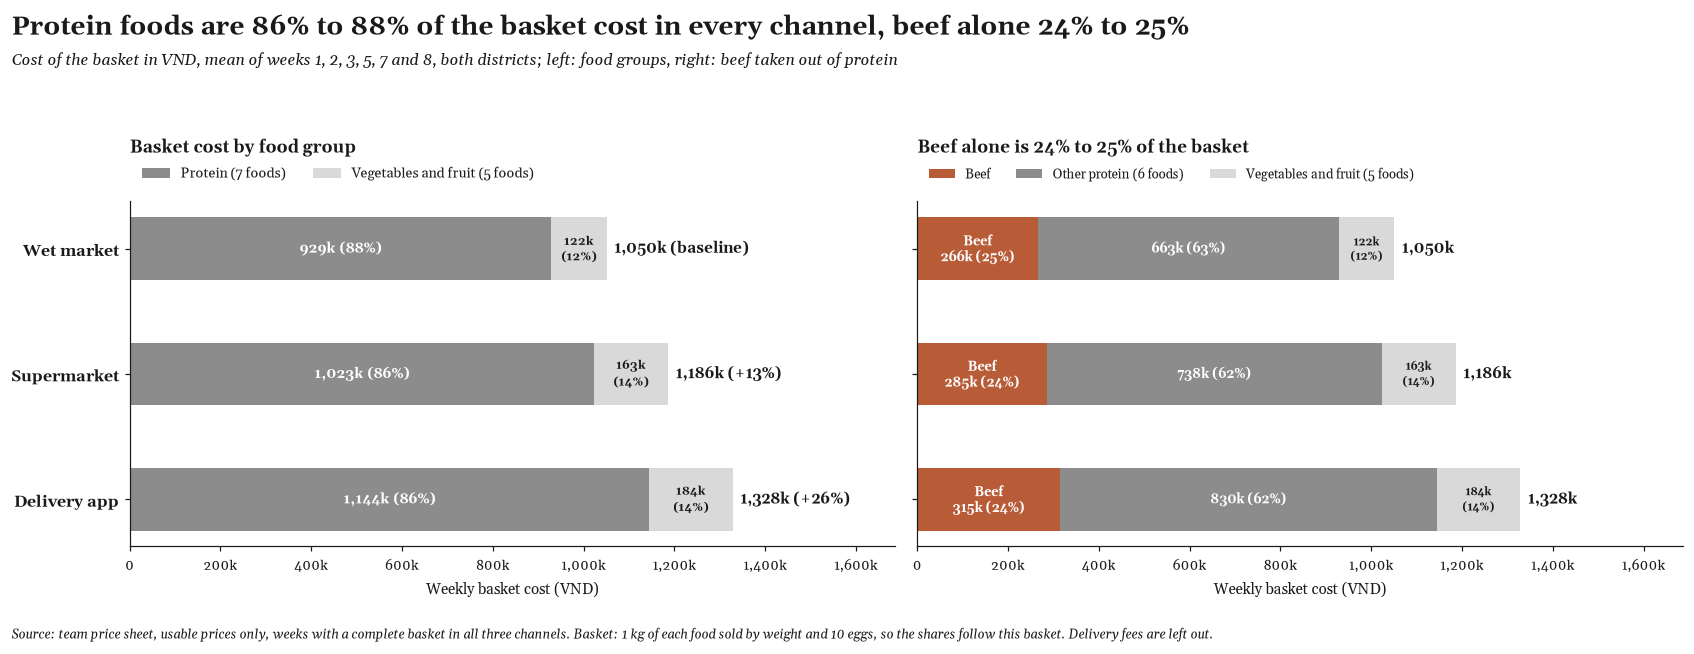

In [49]:
# M7.2b Stacked bars of the basket cost by food group, with the largest food (beef) taken out of protein
# Uses common_weeks, weeks_txt, basket_item_cost, group_map and top_item from M7.2
protein_codes = [c for c in basket_item_cost.columns if group_map[c] == "Đạm"]
veg_codes = [c for c in basket_item_cost.columns if group_map[c] == "Rau củ quả"]
top_name = ITEM_EN[top_item]

protein_costs = basket_item_cost[protein_codes].sum(axis=1).reindex(CHANNEL_ORDER).to_numpy(float)
veg_costs = basket_item_cost[veg_codes].sum(axis=1).reindex(CHANNEL_ORDER).to_numpy(float)
total_costs = protein_costs + veg_costs
beef_costs = basket_item_cost[top_item].reindex(CHANNEL_ORDER).to_numpy(float)
other_protein_costs = protein_costs - beef_costs

# The numbers behind the title and the labels
basket_summary = pd.DataFrame({
    f"{top_name} (VND)": beef_costs.round(0),
    "Other protein (VND)": other_protein_costs.round(0),
    "Vegetables and fruit (VND)": veg_costs.round(0),
    "Basket (VND)": total_costs.round(0),
    f"{top_name} share (%)": (beef_costs / total_costs * 100).round(1),
    "Protein share (%)": (protein_costs / total_costs * 100).round(1),
    "Premium over the wet market (%)": ((total_costs / total_costs[0] - 1) * 100).round(1),
}, index=[CHANNEL_EN[ch] for ch in CHANNEL_ORDER])
display(basket_summary)
p_lo, p_hi = round((protein_costs / total_costs).min() * 100), round((protein_costs / total_costs).max() * 100)
b_lo, b_hi = round((beef_costs / total_costs).min() * 100), round((beef_costs / total_costs).max() * 100)
p_txt = f"{p_lo}%" if p_lo == p_hi else f"{p_lo}% to {p_hi}%"
b_txt = f"{b_lo}%" if b_lo == b_hi else f"{b_lo}% to {b_hi}%"
stack_head = f"Protein foods are {p_txt} of the basket cost in every channel, {top_name.lower()} alone {b_txt}"
print("Protein foods:", len(protein_codes), "| vegetables and fruit:", len(veg_codes))
print("Title:", stack_head)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.0), sharey=True)
y_pos = np.arange(len(CHANNEL_ORDER))
bar_h = 0.50
XMAX = total_costs.max() * 1.27


def part_label(ax, left, width, y, text, fill, size=9):
    """Write a label inside its bar part; a narrow part gets the share on a second line."""
    narrow = width < 0.11 * XMAX
    ax.text(left + width / 2, y, text.replace(" (", "\n(") if narrow else text, ha="center", va="center",
            color=PAPER if fill in (GREY, HIGHLIGHT) else INK, fontsize=size - 1 if narrow else size,
            fontweight="bold", linespacing=1.05)


# Panel 1: food group totals
ax1.barh(y_pos, protein_costs, height=bar_h, color=GREY, label=f"Protein ({len(protein_codes)} foods)")
ax1.barh(y_pos, veg_costs, height=bar_h, left=protein_costs, color=LIGHT, label=f"Vegetables and fruit ({len(veg_codes)} foods)")
for i, (tot, p_val, v_val) in enumerate(zip(total_costs, protein_costs, veg_costs)):
    part_label(ax1, 0, p_val, i, f"{fmt_vnd(p_val)} ({p_val / tot:.0%})", GREY)
    part_label(ax1, p_val, v_val, i, f"{fmt_vnd(v_val)} ({v_val / tot:.0%})", LIGHT)
    prem = f" ({tot / total_costs[0] - 1:+.0%})" if i > 0 else " (baseline)"
    ax1.text(tot + 0.01 * XMAX, i, f"{fmt_vnd(tot)}{prem}", ha="left", va="center", color=INK, fontsize=9.5, fontweight="bold")
ax1.set_yticks(y_pos)
ax1.set_yticklabels([CHANNEL_EN[ch] for ch in CHANNEL_ORDER], fontsize=10.5, fontweight="bold")
ax1.set_xlim(0, XMAX)
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: fmt_vnd(x)))
ax1.set_xlabel("Weekly basket cost (VND)", fontsize=9.5)
ax1.set_title("Basket cost by food group", fontsize=11, fontweight="bold", loc="left", pad=32)
ax1.invert_yaxis()
ax1.legend(loc="lower left", bbox_to_anchor=(0.0, 1.02), ncol=2, frameon=False, fontsize=9)

# Panel 2: the largest food taken out of protein
ax2.barh(y_pos, beef_costs, height=bar_h, color=HIGHLIGHT, label=top_name)
ax2.barh(y_pos, other_protein_costs, height=bar_h, left=beef_costs, color=GREY, label=f"Other protein ({len(protein_codes) - 1} foods)")
ax2.barh(y_pos, veg_costs, height=bar_h, left=protein_costs, color=LIGHT, label=f"Vegetables and fruit ({len(veg_codes)} foods)")
for i, (tot, b_val, op_val, v_val) in enumerate(zip(total_costs, beef_costs, other_protein_costs, veg_costs)):
    part_label(ax2, 0, b_val, i, f"{top_name}\n{fmt_vnd(b_val)} ({b_val / tot:.0%})", HIGHLIGHT, 8.5)
    part_label(ax2, b_val, op_val, i, f"{fmt_vnd(op_val)} ({op_val / tot:.0%})", GREY, 8.5)
    part_label(ax2, b_val + op_val, v_val, i, f"{fmt_vnd(v_val)} ({v_val / tot:.0%})", LIGHT, 8.5)
    ax2.text(tot + 0.01 * XMAX, i, fmt_vnd(tot), ha="left", va="center", color=INK, fontsize=9.5, fontweight="bold")
ax2.set_xlim(0, XMAX)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: fmt_vnd(x)))
ax2.set_xlabel("Weekly basket cost (VND)", fontsize=9.5)
ax2.set_title(f"{top_name} alone is {b_txt} of the basket", fontsize=11, fontweight="bold", loc="left", pad=32)
ax2.legend(loc="lower left", bbox_to_anchor=(0.0, 1.02), ncol=3, frameon=False, fontsize=8.5)

figure_title(fig, stack_head,
             f"Cost of the basket in VND, mean of weeks {weeks_txt}, both districts; left: food groups, right: {top_name.lower()} taken out of protein",
             y=1.04)
note(fig, "Source: team price sheet, usable prices only, weeks with a complete basket in all three channels. "
          "Basket: 1 kg of each food sold by weight and 10 eggs, so the shares follow this basket. Delivery fees are left out.")
fig.tight_layout(rect=[0, 0, 1, 0.90])
save(fig, FIG / "m7_stacked_basket.png")
plt.show()

### M7.3 · Parallel coordinates: the 12 foods across channels and districts

*Task:* follow each food from the wet market to the supermarket and the app in each district, and check whether the two M6 groups behave differently.

*Why this chart:* parallel coordinates draw each food as one line across several axes. The slope between two axes shows the gap between two channels, and lines that run together show foods that behave alike.

*Choices:* the rows are the two M6 groups and the columns the two districts. Each panel has three axes in the house order: wet market, supermarket, delivery app. The value on every axis is an index: the median price of the food in that channel and district, divided by the mean of its six medians, times 100. The index puts foods sold per kg and eggs sold per piece on one scale. The lines take the M6 group colours (large gap in terracotta, small gap in black), and faint grey lines show the other group. Labels name each food at the right of both districts, and one box per panel names the food with the steepest or the flattest climb.


,food,group,"Wet market, Quận 10","Supermarket, Quận 10","Delivery app, Quận 10","Wet market, Quận 3","Supermarket, Quận 3","Delivery app, Quận 3"
item_code,,,,,,,,
SP08,Onion,Large channel gap,62.6,118.6,112.6,64.1,117.0,125.1
SP12,Red tilapia,Large channel gap,76.8,92.1,130.5,75.7,93.2,131.6
SP04,Tomato,Large channel gap,79.1,110.2,110.1,86.3,113.5,100.7
SP02,Water spinach,Large channel gap,77.0,105.5,129.8,70.5,98.6,118.6
SP07,Watermelon,Large channel gap,78.1,95.7,117.3,70.5,95.7,142.7
SP10,White tofu,Large channel gap,69.9,104.8,124.8,74.5,104.8,121.1
SP05,Beef,Small channel gap,92.2,97.5,104.2,95.4,100.6,110.2
SP11,Chicken eggs,Small channel gap,78.2,97.6,115.3,83.8,102.4,122.7
SP06,Free range chicken,Small channel gap,97.1,97.9,98.9,98.7,97.9,109.4


Median climb from the wet market to the app, index points:


,Quận 10,Quận 3
cluster,,
Large channel gap,51.5,52.0
Small channel gap,20.5,18.0


Title: In both districts, large gap foods climb 51 to 52 points from wet market to app, small gap foods 18 to 21


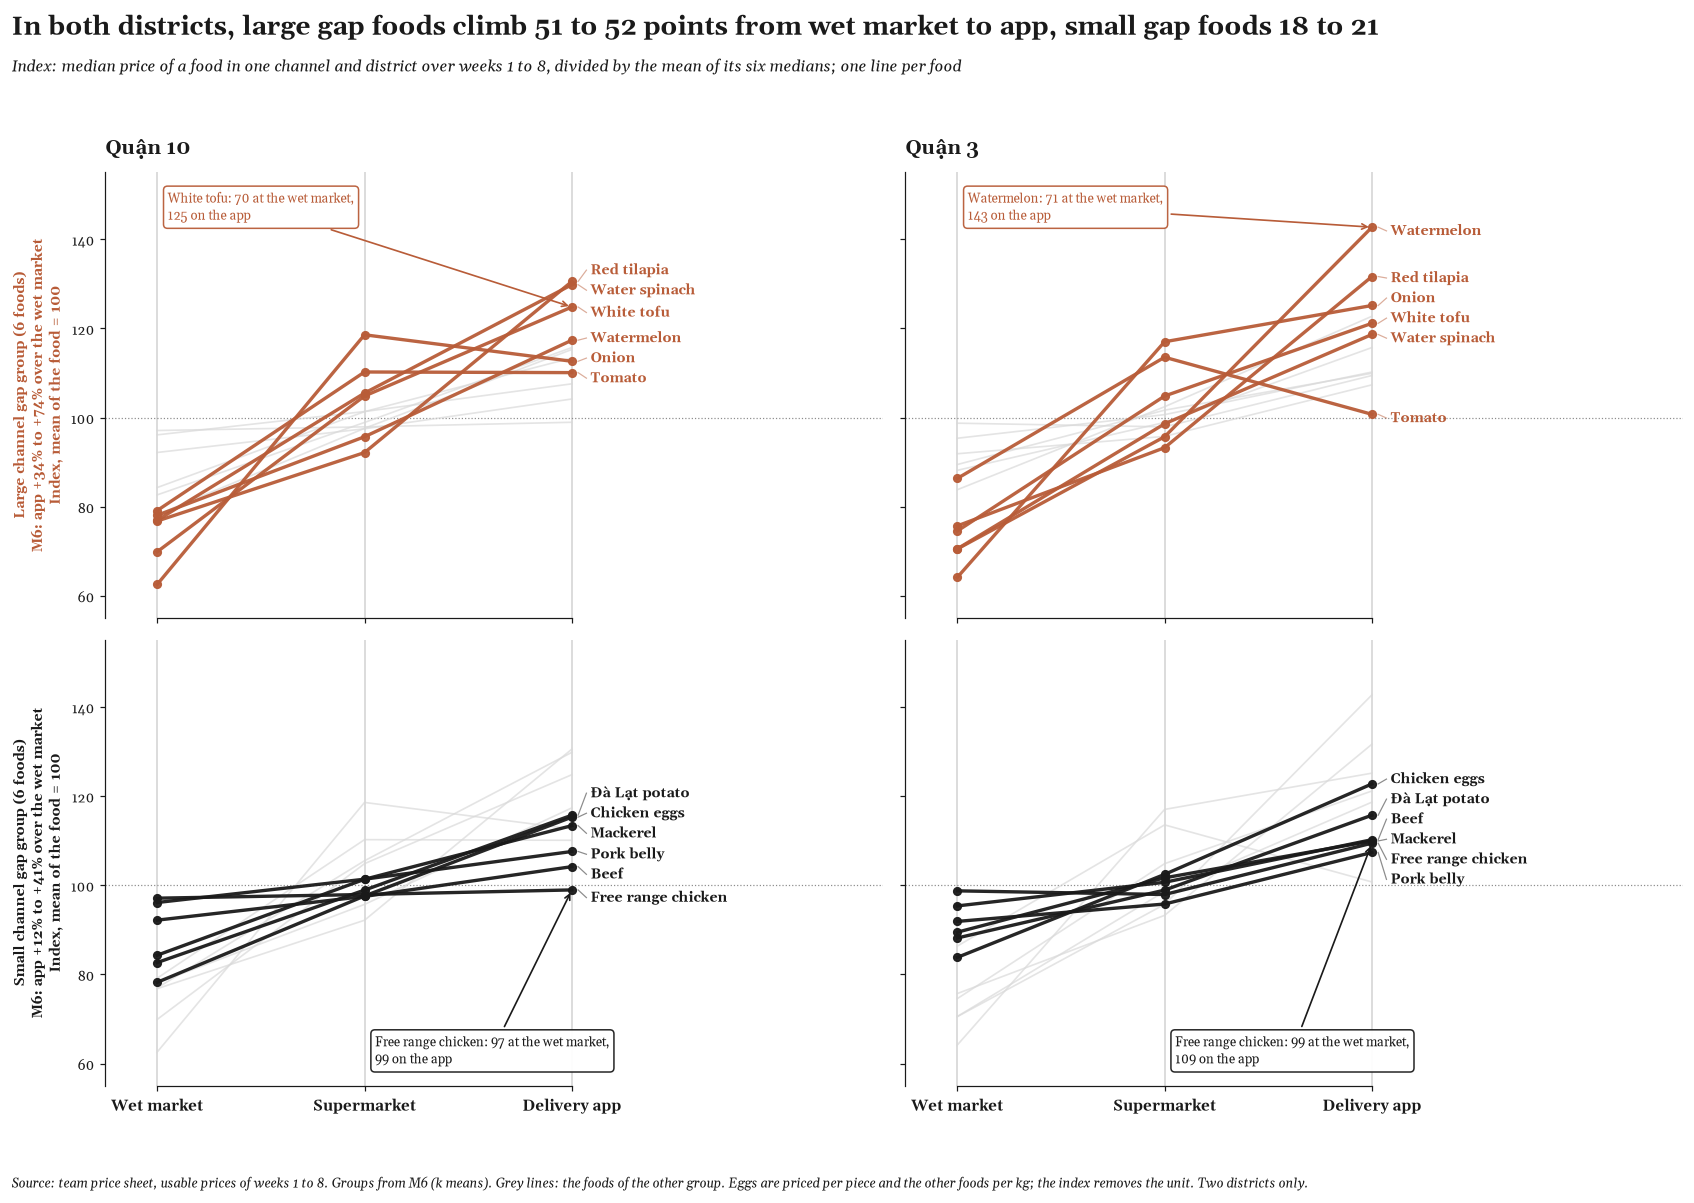

In [50]:
# M7.3 Parallel coordinates of the 12 foods: one panel per M6 group and district, three channel axes
# 1. Median price of each food per district and channel over the usable prices of all weeks
piv = usable_prices.pivot_table(index="item_code", columns=["district", "channel"], values="price_std", aggfunc="median").astype(float)

# 2. Index: the mean of the six medians of a food = 100, so foods sold per kg and eggs sold per piece share one scale
pc_index = piv.div(piv.mean(axis=1), axis=0) * 100
pc_group = clusters["cluster"].reindex(pc_index.index)
groups = [g for g in NAMES_BY_RANK if (pc_group == g).any()]

# 3. The numbers behind the title: the climb in index points from the wet market to the app
climb = pd.DataFrame({d: pc_index[(d, "App")] - pc_index[(d, "Chợ")] for d in DISTRICT_ORDER})
climb_med = climb.groupby(pc_group).median().reindex(groups)
table = pc_index[[(d, ch) for d in DISTRICT_ORDER for ch in CHANNEL_ORDER]].round(1)
table.columns = [f"{CHANNEL_EN[c]}, {d}" for d, c in table.columns]
table.insert(0, "group", pc_group)
table.insert(0, "food", [ITEM_EN[c] for c in table.index])
display(table.sort_values(["group", "food"]))
print("Median climb from the wet market to the app, index points:")
display(climb_med.round(1))


def points_txt(values):
    lo, hi = (int(np.floor(v + 0.5)) for v in (min(values), max(values)))     # round half up, as in the printed table
    return f"{lo}" if lo == hi else f"{lo} to {hi}"


g_top, g_rest = groups[0], groups[-1]
short = {g: g.replace(" channel", "").lower() for g in groups}                # "Large channel gap" -> "large gap"
pc_head = (f"In both districts, {short[g_top]} foods climb {points_txt(climb_med.loc[g_top])} points "
           f"from wet market to app, {short[g_rest]} foods {points_txt(climb_med.loc[g_rest])}")
print("Title:", pc_head)


def spread_labels(ys, min_gap, lo, hi):
    """Move label heights apart by at least min_gap, keep their mean, and keep them between lo and hi."""
    ys = np.asarray(ys, dtype=float)
    order = np.argsort(ys)
    out = ys[order].copy()
    for i in range(1, len(out)):
        out[i] = max(out[i], out[i - 1] + min_gap)
    out += ys.mean() - out.mean()
    out -= max(0.0, out[-1] - hi)
    out += max(0.0, lo - out[0])
    res = np.empty_like(out)
    res[order] = out
    return res


# 4. Two rows (M6 groups) by two columns (districts)
x_vals = np.arange(len(CHANNEL_ORDER))
y_lo = np.floor(pc_index.min().min() / 10) * 10 - 5
y_hi = np.ceil(pc_index.max().max() / 10) * 10 + 5
fig, axes = plt.subplots(2, 2, figsize=(15.5, 9.8), sharex=True, sharey=True)
for r, g in enumerate(groups):
    colour = GROUP_COLOR[g]
    foods = pc_group.index[pc_group == g]
    others = pc_group.index[pc_group != g]
    for c, d in enumerate(DISTRICT_ORDER):
        ax = axes[r, c]
        vals = pc_index[d][CHANNEL_ORDER]
        for xv in x_vals:
            ax.axvline(xv, color=LIGHT, linewidth=1.2, zorder=1)
        ax.axhline(100, color=GREY, linewidth=0.8, linestyle=":", zorder=1)
        for it in others:                            # the other group as faint context
            ax.plot(x_vals, vals.loc[it].values, color=LIGHT, linewidth=1.1, alpha=0.7, zorder=1)
        for it in foods:
            ax.plot(x_vals, vals.loc[it].values, color=colour, linewidth=2.2, marker="o", markersize=5, zorder=3, alpha=0.95)

        # One box per panel: the steepest climb in the first group, the flattest in the other
        pick = climb.loc[foods, d].idxmax() if r == 0 else climb.loc[foods, d].idxmin()
        ax.annotate(f"{ITEM_EN[pick]}: {vals.loc[pick, 'Chợ']:.0f} at the wet market,\n{vals.loc[pick, 'App']:.0f} on the app",
                    xy=(x_vals[-1], vals.loc[pick, "App"]), xytext=(0.05, y_hi - 4) if r == 0 else (1.05, y_lo + 4),
                    ha="left", va="top" if r == 0 else "bottom",
                    fontsize=8.8, color=colour, arrowprops=dict(arrowstyle="->", color=colour, lw=1.1),
                    bbox=dict(boxstyle="round,pad=0.3", facecolor=PAPER, edgecolor=colour, alpha=0.95))

        # Food names at the right of both districts
        ends = vals.loc[foods, "App"]
        label_y = spread_labels(ends.values, (y_hi - y_lo) * 0.045, y_lo, y_hi)
        for it, y_end, y_lab in zip(ends.index, ends.values, label_y):
            if abs(y_lab - y_end) > 0.3:
                ax.plot([x_vals[-1] + 0.03, x_vals[-1] + 0.07], [y_end, y_lab], color=colour, alpha=0.5, linewidth=0.8)
            ax.text(x_vals[-1] + 0.09, y_lab, ITEM_EN[it], va="center", ha="left", fontsize=9.2, fontweight="bold", color=colour)
        if r == 0:
            ax.set_title(d, fontsize=13, fontweight="bold", pad=12)
        if c == 0:
            lo, hi = app_range.loc[g, "min"], app_range.loc[g, "max"]
            ax.set_ylabel(f"{g} group ({len(foods)} foods)\nM6: app {lo:+.0%} to {hi:+.0%} over the wet market\nIndex, mean of the food = 100",
                          fontsize=9.2, fontweight="bold", color=colour)
        ax.set_ylim(y_lo, y_hi)
        ax.set_xlim(-0.25, len(CHANNEL_ORDER) - 0.75 + 1.25)
        ax.spines["bottom"].set_bounds(0, 2)

for ax in axes[1]:
    ax.set_xticks(x_vals)
    ax.set_xticklabels([CHANNEL_EN[ch] for ch in CHANNEL_ORDER], fontsize=10, fontweight="bold")

figure_title(fig, pc_head,
             f"Index: median price of a food in one channel and district over {PERIOD}, divided by the mean of its six medians; one line per food",
             y=1.03)
note(fig, f"Source: team price sheet, usable prices of {PERIOD}. Groups from M6 (k means). Grey lines: the foods of the other group. "
          "Eggs are priced per piece and the other foods per kg; the index removes the unit. Two districts only.",
     y=-0.02)
fig.tight_layout(rect=[0, 0.02, 1, 0.96])
save(fig, FIG / "m7_parallel_coords.png")
plt.show()


---
# M8 · Beyond the flat screen

**What the brief asks.** One 3D, spatial or XR view and its best 2D alternative, and a small experiment: at least five people outside the team answer the same three questions with both versions, in random order. My group records accuracy and time and reports the result honestly, even if 3D loses. For this project: a 3D block of item × week × channel against small multiples.

**Plan.** The 3D view reuses the bar style of the M2 status figure: items on one axis, weeks on the other, one block per channel, height or colour for the price index. The 2D alternative is three heatmaps side by side with one colour scale. My group writes the three questions and their answers before the test, and half of the people see 3D first.

**Status.** Not started. The experiment also tests the 3D column style of the team: if readers answer worse with 3D, my group says so and changes the style.

---
# M9 · Interaction, animation and story

**What the brief asks.** An explorer (ipywidgets or plotly) with at least three controls that answers a real question of the client, one animation that shows change better than a static chart (or evidence that small multiples work better), a hand drawn storyboard of 5 to 8 frames, and Big Idea v1. For this project: a "build your basket" explorer and an animation of the basket cost by week. A plotly HTML copy of the explorer must run without a kernel.

**Status.** Not started. The explorer needs `plotly` and `ipywidgets` from `requirements.txt`.

---
# M10 · Evaluation and improvement

**What the brief asks.** A user test with at least five people outside the team (ideally students who cook): tasks, success, time, think aloud notes, and a five second test of the main chart. A peer review with another team using the course checklist (CP4). An improvement log from v1 to v2 with at least eight changes, each with its evidence.

**Plan.** `improvement_log.csv` with the columns id, version, change, evidence, who and date. Sources of changes: the user test, the peer review, the AI audit of M4, the 2D and 3D experiment of M8 and feedback from the client.

**Status.** Not started.

---
# Appendix · AI log
My group records every use of an AI tool here and in `report/ai_log.md`. No AI tool created price data or survey answers for the analysis. The synthetic survey preview of 17/11/2026 stays outside the repository and outside the analysis.

| Date | Member | Tool | What the tool did | How my group checked it |
|---|---|---|---|---|
| 26/10/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Opus 5.5) | Wrote the download script, `house_style.py`, the code of M2, M3 and M4 in this notebook, the M2 status figure, and first drafts of the M1 text and the data cards, based on the interview transcript and the team price sheet | *(fill in)* |
| 26/10/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Opus 5.5) | Redrew the M3 and M4 charts as 3D columns, added the 3D helpers to the house style, filled the M2 gaps, wrote `CHANGELOG.md`, and built and deployed the Vietnamese website | *(fill in)* |
| 26/10/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Opus 5.5) | Reran M2, M3 and M4 on the complete snapshot of weeks 1 and 2 (144 prices), updated every number in the text, and redeployed the website | *(fill in)* |
| 14/11/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Opus 5.5) | Loaded the export of 14 November, added the rule that leaves out prices dated after the export, wrote the code and text of M4 charts 3 to 6, the M5 dashboard and Excel workbook (the 300 word comparison is only a draft), and all of M6 (features, PCA, k means, dendrograms, cluster profiles); updated the numbers in M1 to M3, the data cards, `AGENTS.md` and the website, and redeployed the site | *(fill in: who compared the M4 to M6 numbers with the sheet, who reviewed the cluster names, who checked the dates of weeks 6 to 8)* |
| 14/11/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Opus 5.5) | Reviewed M6 against the brief: added stability tests (one week, one district, one food left out), changed the rule for k (now k = 2), fixed the loadings, checked that each group name fits every food, and redrew the four M6 charts and the website section | *(fill in: who checked the stability table and the group of each food against the sheet)* |
| 15/11/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Opus 5.5) | Checked the text of M1 to M6 in the notebook, the reports and the website against the outputs, replaced numbers left from the two week snapshot, added a printed check of the channel ratios (M4.2), made four charts easier to read, and redeployed the site | *(fill in: who read the updated sections and compared them with the outputs)* |
| 15/11/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Opus 5.5) | Downloaded the export of 15 November, kept weeks 6 to 8 in the analysis after the team lead confirmed the sheet is complete (flag kept for a date check), adapted the status figure, the line charts and the M6 rule for k to eight weeks, updated every number in the notebook, reports, data cards and website, and redeployed the site | *(fill in: who compared the new numbers with the sheet and who checks the dates of weeks 6 to 8)* |
| 15/11/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Sonnet 5.5) | Checked the raw and clean data files (personal data, row counts, keys, flags, data dictionary), wrote the data section of the README, ran the notebook from a fresh clone, and prepared the commit, the push to `hwinh` and the pull request into `dev` | *(fill in: who read the pull request before the merge)* |
| 18/11/2026 | Trần Nhã Đoan | ChatGPT (GPT-4o) | Wrote M7.1 heatmap with Ward leaf ordering and M7.2 hierarchical treemap of weekly basket cost | Reviewed outputs and verified figures |
| 18/11/2026 | Trần Nguyễn Thanh Thảo | Antigravity | Refactored M7.1 text contrast; expanded M7.2 into two-panel stacked bar chart spotlighting Beef with top legends; restructured M7.3 into 2x2 parallel coordinates grid by cluster and district with callout annotations and collision-free labels | Verified cell executions in notebook, checked printed summary tables, and confirmed zero glyph errors in serif rendering |
| 17/11/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Opus 5.5) | Made a SYNTHETIC survey preview outside git: 71 fake answers, seven cleaning rules that keep 63, five preview charts marked SYNTHETIC PREVIEW, and a proposal of 27 questions for the real form. No number from it enters the notebook, the report or the website | *(fill in: who read the proposed questions and decided on the real form)* |
| 18/11/2026 | Nguyễn Hoàng Minh | Claude Code (Claude Opus 5.5) | Merged the M7 work of Trần Nhã Đoan and Trần Nguyễn Thanh Thảo into `hwinh` and checked it against Section 4.7 of the brief. Restored the treemap as M7.2 and kept the stacked bars as M7.2b; fixed the food counts, the group ranges, the titles and the colours of M7.2b and M7.3; put M7.3 on an index so that the channel gap shows and eggs and foods per kg share one scale; marked empty and thin cells in the heatmap; added Gelasio to the house style so that Windows draws Vietnamese letters; reran the notebook, added M7 to the website and redeployed it | *(fill in: Đoan and Thảo read the new M7 code and outputs and confirm the changes to their charts)* || 19/11/2026 | Trần Nguyễn Thanh Thảo | Antigravity | Synced branch with upstream dev; added direct food labels to both District 10 and District 3 in M7.3 parallel coordinates, bounded bottom spines to eliminate trailing baselines, added file-lock retry in house_style save and _trim on Windows, and ran the full notebook | Verified cell outputs, confirmed no baseline overhang, and visually verified generated chart |
